# Formula 1 Podium Prediction — Milestone 1
**Goal:** predict whether a driver finishes on the podium (positionOrder ≤ 3) using only information available after qualifying and before the race starts.

**Unit of analysis:** one driver in one race (unique `raceId`, `driverId`).

**Contents**
0. Setup
1. Data loading, auditing & cleaning — 1.1 sentinels · 1.2 keys · 1.3 EDA before · 1.4 cleaning · 1.5 EDA after
2. Data-engineering questions — Q1 front-row conversion · Q2 home advantage · Q3 mechanical retirements
3. Feature engineering & split — 3.1 grid/qualifying · 3.2 standings · 3.3 form · 3.4 split · 3.5 evidence
4. Modeling — 4.1 pipeline, metrics, baselines · 4.2 classic models · 4.3 shallow NN · 4.4 comparison & test
5. Experiments — 5.1 preprocessing effect · 5.2 feature-group ablation · 5.3 preprocessing-order experiments
6. Explainability & inference — 6.1 permutation importance · 6.2 SHAP · 6.3 local (SHAP, LIME) · 6.4 non-causal · 6.5 inference function
7. Summary

## 0. Setup
Install extra libraries, import everything, and fix the random seed so results are reproducible.

In [1]:
!pip install -q shap lime

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve,
                             roc_curve)
from sklearn.inspection import permutation_importance

import lightgbm as lgb
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import shap
import lime
import lime.lime_tabular

# Reproducibility: same random numbers every run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

In [2]:
# Search Kaggle's input folder for the F1 CSVs
DATASET_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'results.csv' in files and 'races.csv' in files:
        DATASET_DIR = root
        break

assert DATASET_DIR is not None, "F1 dataset not found — attach it via Add Input."
print("Dataset folder:", DATASET_DIR)
print(sorted(os.listdir(DATASET_DIR)))

Dataset folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


# 1. Data Loading, Auditing & Cleaning
## 1.1 Raw load & sentinel audit
Raw tables are loaded as text and never modified (immutable reference). We count sentinel values (`\N`, MySQL's export marker for NULL) and empty cells per column **before** converting them, so the effect of cleaning can be measured.


In [3]:
table_names = [
    'circuits', 'constructors', 'constructor_results', 'constructor_standings',
    'drivers', 'driver_standings', 'races', 'results', 'qualifying',
    'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status'
]

# RAW: exact file contents, every value kept as text. Never modified.
raw_tables = {}
for tbl in table_names:
    path = os.path.join(DATASET_DIR, f"{tbl}.csv")
    raw_tables[tbl] = pd.read_csv(path, dtype=str, keep_default_na=False)
    print(f"{tbl:<22} shape: {raw_tables[tbl].shape}")

# Count '\N' and empty cells in every column
rows = []
for tbl, df in raw_tables.items():
    for col in df.columns:
        n_sent = (df[col] == '\\N').sum()
        n_empty = (df[col].str.strip() == '').sum()
        if n_sent or n_empty:
            rows.append({'table': tbl, 'column': col,
                         'n_sentinel': n_sent, 'n_empty': n_empty,
                         'pct_missing': round(100 * (n_sent + n_empty) / len(df), 2)})

sentinel_audit = (pd.DataFrame(rows)
                  .sort_values('pct_missing', ascending=False)
                  .reset_index(drop=True))
display(sentinel_audit)

circuits               shape: (77, 9)
constructors           shape: (212, 5)
constructor_results    shape: (12625, 5)
constructor_standings  shape: (13391, 7)
drivers                shape: (861, 9)
driver_standings       shape: (34863, 7)
races                  shape: (1125, 18)
results                shape: (26759, 18)
qualifying             shape: (10494, 9)
lap_times              shape: (589081, 6)
pit_stops              shape: (11371, 7)
sprint_results         shape: (360, 16)
seasons                shape: (75, 2)
status                 shape: (139, 2)


,table,column,n_sentinel,n_empty,pct_missing
0,constructor_results,status,12608,0,99.87
1,races,sprint_time,1110,0,98.67
2,races,sprint_date,1107,0,98.40
3,races,fp3_time,1072,0,95.29
4,races,fp2_time,1057,0,93.96
5,races,fp1_time,1057,0,93.96
6,races,quali_time,1057,0,93.96
7,races,fp3_date,1053,0,93.60
8,drivers,number,802,0,93.15
9,races,fp1_date,1035,0,92.00


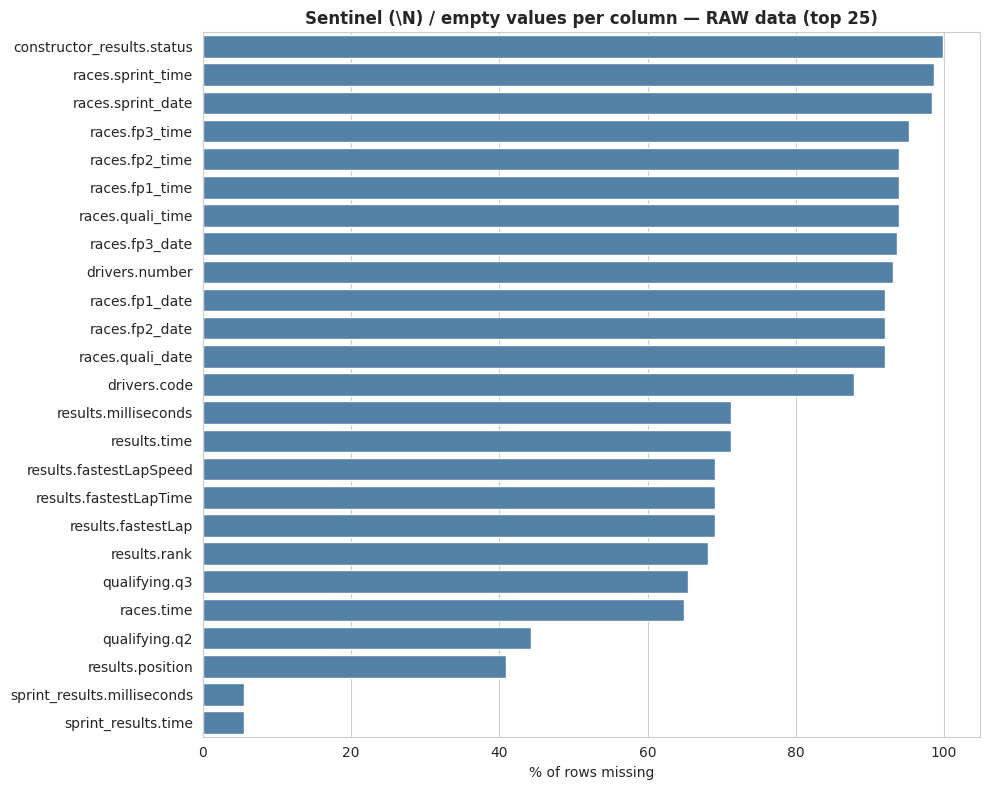

In [4]:
top = sentinel_audit.head(25).copy()
top['label'] = top['table'] + '.' + top['column']

plt.figure(figsize=(10, 8))
sns.barplot(data=top, y='label', x='pct_missing', color='steelblue')
plt.title('Sentinel (\\N) / empty values per column — RAW data (top 25)', fontweight='bold')
plt.xlabel('% of rows missing')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [5]:
# WORKING COPY: only '\N' and empty cells become NaN
tables = {}
for tbl in table_names:
    path = os.path.join(DATASET_DIR, f"{tbl}.csv")
    tables[tbl] = pd.read_csv(path, na_values=['\\N', ''], keep_default_na=False)

# Verify: NaN count in working copy == sentinels counted in raw
for tbl in table_names:
    expected = int(sentinel_audit.loc[sentinel_audit['table'] == tbl,
                                      ['n_sentinel', 'n_empty']].sum().sum())
    actual = int(tables[tbl].isna().sum().sum())
    assert expected == actual, f"{tbl}: expected {expected} NaNs, got {actual}"

print("Verified: every NaN in the working copy comes from a counted sentinel.")

Verified: every NaN in the working copy comes from a counted sentinel.


### Findings — sentinel audit
- All missingness is encoded as `\N`, except `qualifying.q2` / `q3`, which also contain **empty strings** (22 and 46 cells). Both were converted to `NaN`, and the conversion was verified exactly.
- **Structural missingness** (value cannot exist): `results.position` (41%, non-classified finishers), `results.time` / `milliseconds` (71%, only lead-lap finishers are timed), `qualifying.q2` / `q3` (eliminated drivers). Kept as `NaN`; meaningful, not errors.
- **Coverage drift** (not recorded in earlier eras): fastest-lap fields (~69%), `races.time` (65%), session dates/times (92–95%), `drivers.number` / `code`. Verified by year in Section 1.3.
- **Unusable column:** `constructor_results.status` is 99.87% missing and is dropped.
- **Target and grid are complete:** `positionOrder` and `grid` have 0% missing.
- Most high-missing columns are post-race (leakage) and are not used as features.
- Cell-level counts cannot reveal **missing rows**: `qualifying` has 10,494 rows vs 26,759 in `results` (checked in 1.3).

## 1.2 Key audit — primary keys, natural keys, foreign keys
- **Primary keys** must be unique and non-null.
- **Natural keys** (e.g. one row per driver per race) are checked separately: a table can have a unique ID column yet still repeat the same real-world entity.
- **Foreign keys** must reconcile: every reference must exist in its parent table (no orphans).

In [6]:
# Primary key of every table (from the Ergast schema)
pk_spec = {
    'circuits':              ['circuitId'],
    'constructors':          ['constructorId'],
    'constructor_results':   ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'drivers':               ['driverId'],
    'driver_standings':      ['driverStandingsId'],
    'races':                 ['raceId'],
    'results':               ['resultId'],
    'qualifying':            ['qualifyId'],
    'lap_times':             ['raceId', 'driverId', 'lap'],   # composite key
    'pit_stops':             ['raceId', 'driverId', 'stop'],  # composite key
    'sprint_results':        ['resultId'],
    'seasons':               ['year'],
    'status':                ['statusId'],
}

pk_rows = []
for tbl, key in pk_spec.items():
    df = tables[tbl]
    pk_rows.append({
        'table': tbl,
        'primary_key': ', '.join(key),
        'rows': len(df),
        'null_keys': int(df[key].isna().any(axis=1).sum()),
        'duplicate_keys': int(df.duplicated(subset=key).sum()),
    })

pk_audit = pd.DataFrame(pk_rows)
pk_audit['valid'] = (pk_audit['null_keys'] == 0) & (pk_audit['duplicate_keys'] == 0)
display(pk_audit)

,table,primary_key,rows,null_keys,duplicate_keys,valid
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,constructor_results,constructorResultsId,12625,0,0,True
3,constructor_standings,constructorStandingsId,13391,0,0,True
4,drivers,driverId,861,0,0,True
5,driver_standings,driverStandingsId,34863,0,0,True
6,races,raceId,1125,0,0,True
7,results,resultId,26759,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,lap_times,"raceId, driverId, lap",589081,0,0,True


In [7]:
# Combinations that should be unique in the real world
nk_spec = {
    'results':               ['raceId', 'driverId'],
    'qualifying':            ['raceId', 'driverId'],
    'sprint_results':        ['raceId', 'driverId'],
    'driver_standings':      ['raceId', 'driverId'],
    'constructor_standings': ['raceId', 'constructorId'],
    'constructor_results':   ['raceId', 'constructorId'],
    'races':                 ['year', 'round'],
}

nk_rows = []
for tbl, key in nk_spec.items():
    df = tables[tbl]
    dup_mask = df.duplicated(subset=key, keep=False)   # marks ALL copies
    nk_rows.append({
        'table': tbl,
        'natural_key': ', '.join(key),
        'rows_involved_in_duplicates': int(dup_mask.sum()),
        'duplicated_keys': int(df.loc[dup_mask, key].drop_duplicates().shape[0]),
    })

nk_audit = pd.DataFrame(nk_rows)
display(nk_audit)

,table,natural_key,rows_involved_in_duplicates,duplicated_keys
0,results,"raceId, driverId",176,85
1,qualifying,"raceId, driverId",0,0
2,sprint_results,"raceId, driverId",0,0
3,driver_standings,"raceId, driverId",0,0
4,constructor_standings,"raceId, constructorId",0,0
5,constructor_results,"raceId, constructorId",0,0
6,races,"year, round",0,0


In [8]:
# (child table, child column, parent table, parent column)
fk_spec = [
    ('races',                 'circuitId',     'circuits',     'circuitId'),
    ('races',                 'year',          'seasons',      'year'),
    ('results',               'raceId',        'races',        'raceId'),
    ('results',               'driverId',      'drivers',      'driverId'),
    ('results',               'constructorId', 'constructors', 'constructorId'),
    ('results',               'statusId',      'status',       'statusId'),
    ('qualifying',            'raceId',        'races',        'raceId'),
    ('qualifying',            'driverId',      'drivers',      'driverId'),
    ('qualifying',            'constructorId', 'constructors', 'constructorId'),
    ('sprint_results',        'raceId',        'races',        'raceId'),
    ('sprint_results',        'driverId',      'drivers',      'driverId'),
    ('sprint_results',        'constructorId', 'constructors', 'constructorId'),
    ('sprint_results',        'statusId',      'status',       'statusId'),
    ('driver_standings',      'raceId',        'races',        'raceId'),
    ('driver_standings',      'driverId',      'drivers',      'driverId'),
    ('constructor_standings', 'raceId',        'races',        'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results',   'raceId',        'races',        'raceId'),
    ('constructor_results',   'constructorId', 'constructors', 'constructorId'),
    ('lap_times',             'raceId',        'races',        'raceId'),
    ('lap_times',             'driverId',      'drivers',      'driverId'),
    ('pit_stops',             'raceId',        'races',        'raceId'),
    ('pit_stops',             'driverId',      'drivers',      'driverId'),
]

fk_rows = []
for child, col, parent, pcol in fk_spec:
    child_vals = tables[child][col]
    parent_vals = tables[parent][pcol].dropna().unique()
    non_null = child_vals.dropna()
    orphan_mask = ~non_null.isin(parent_vals)
    fk_rows.append({
        'relation': f"{child}.{col} → {parent}.{pcol}",
        'null_fk': int(child_vals.isna().sum()),
        'orphans': int(orphan_mask.sum()),
        'orphan_examples': list(non_null[orphan_mask].unique()[:5]),
    })

fk_audit = pd.DataFrame(fk_rows)
fk_audit['reconciles'] = (fk_audit['null_fk'] == 0) & (fk_audit['orphans'] == 0)
display(fk_audit)

,relation,null_fk,orphans,orphan_examples,reconciles
0,races.circuitId → circuits.circuitId,0,0,[],True
1,races.year → seasons.year,0,0,[],True
2,results.raceId → races.raceId,0,0,[],True
3,results.driverId → drivers.driverId,0,0,[],True
4,results.constructorId → constructors.construct...,0,0,[],True
5,results.statusId → status.statusId,0,0,[],True
6,qualifying.raceId → races.raceId,0,0,[],True
7,qualifying.driverId → drivers.driverId,0,0,[],True
8,qualifying.constructorId → constructors.constr...,0,0,[],True
9,sprint_results.raceId → races.raceId,0,0,[],True


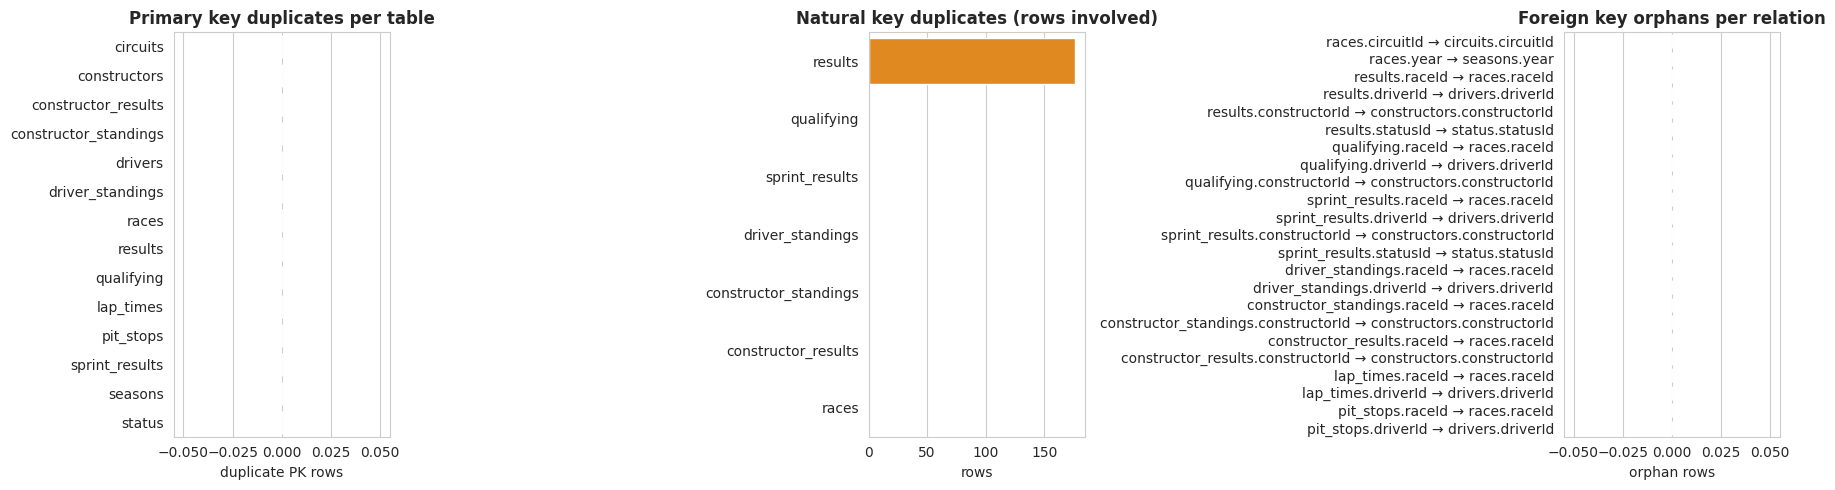

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=pk_audit, y='table', x='duplicate_keys', ax=axes[0], color='steelblue')
axes[0].set_title('Primary key duplicates per table', fontweight='bold')
axes[0].set_xlabel('duplicate PK rows'); axes[0].set_ylabel('')

sns.barplot(data=nk_audit, y='table', x='rows_involved_in_duplicates', ax=axes[1], color='darkorange')
axes[1].set_title('Natural key duplicates (rows involved)', fontweight='bold')
axes[1].set_xlabel('rows'); axes[1].set_ylabel('')

sns.barplot(data=fk_audit, y='relation', x='orphans', ax=axes[2], color='firebrick')
axes[2].set_title('Foreign key orphans per relation', fontweight='bold')
axes[2].set_xlabel('orphan rows'); axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

### Findings — key audit
- **Primary keys:** all 14 tables have unique, non-null primary keys (including the composite keys of `lap_times` and `pit_stops`).
- **Foreign keys:** all 23 relations reconcile, with 0 null references and 0 orphans. Joins between tables will not drop rows due to broken links.
- **Natural keys:** `results` has a unique `resultId`, but **85 (raceId, driverId) pairs appear more than once (176 rows)**: shared drives. Since 176 > 2 × 85, some drivers appear 3 times in one race. Handled in Section 1.4.
- `qualifying`, `sprint_results`, `driver_standings`, `constructor_standings` and `constructor_results` have no natural-key duplicates, so joining them to the modeling table will not multiply rows.

## 1.3 EDA before cleaning
Snapshot of the data **before** typing and de-duplication: column types, coverage per season, class balance, and grid distribution. Section 1.5 repeats the key views after cleaning.

In [10]:
# Columns pandas stored as text ('object'). Some are real text (names),
# others are dates/durations that need semantic typing.
dtype_rows = []
for tbl in ['races', 'results', 'qualifying', 'pit_stops', 'lap_times', 'drivers']:
    for col, dt in tables[tbl].dtypes.items():
        if dt == 'object':
            dtype_rows.append({'table': tbl, 'column': col,
                               'dtype': str(dt),
                               'example_value': tables[tbl][col].dropna().iloc[0]})

dtype_before = pd.DataFrame(dtype_rows)
display(dtype_before)

,table,column,dtype,example_value
0,races,name,object,Australian Grand Prix
1,races,date,object,2009-03-29
2,races,time,object,06:00:00
3,races,url,object,http://en.wikipedia.org/wiki/2009_Australian_G...
4,races,fp1_date,object,2021-04-16
5,races,fp1_time,object,12:00:00
6,races,fp2_date,object,2021-04-16
7,races,fp2_time,object,15:00:00
8,races,fp3_date,object,2021-04-17
9,races,fp3_time,object,12:00:00


Races in races table: 1125 | races with results: 1125


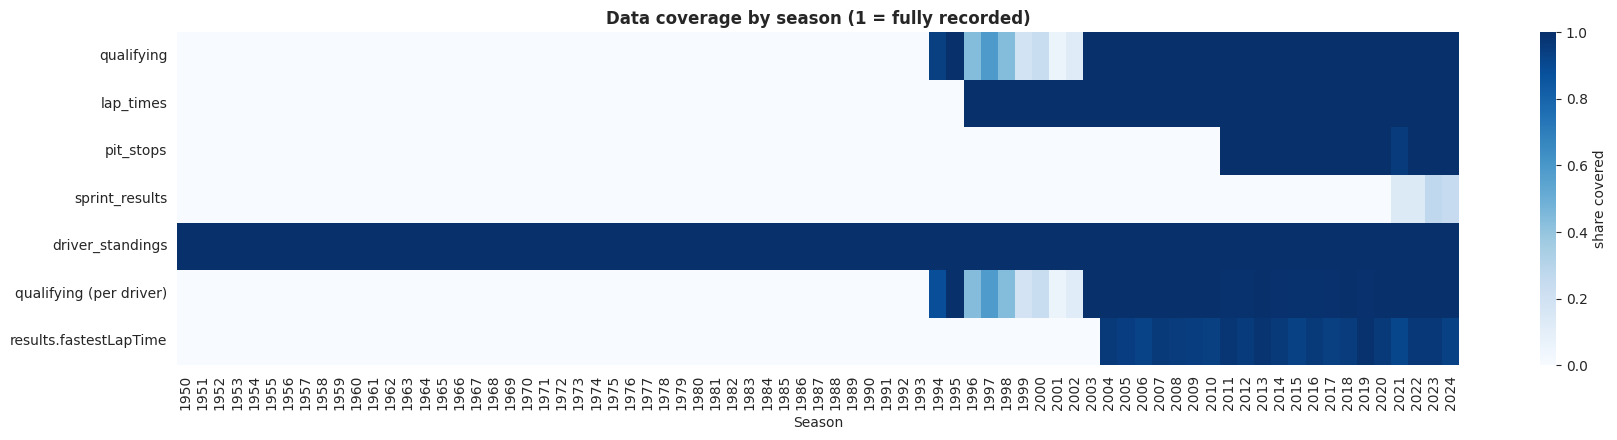

,first season with ≥90% coverage
qualifying,1994.0
lap_times,1996.0
pit_stops,2011.0
sprint_results,NaN
driver_standings,1950.0
qualifying (per driver),1995.0
results.fastestLapTime,2004.0


,qualifying,qualifying (per driver)
year,,
1993,0.00,0.00
1994,0.94,0.88
1995,1.00,1.00
1996,0.44,0.44
1997,0.59,0.59
1998,0.44,0.44
1999,0.19,0.18
2000,0.24,0.24
2001,0.06,0.06


In [11]:
races_y = tables['races'][['raceId', 'year']]

# Keep only races that actually have results
# (the races table may also contain races with no results)
raced = races_y[races_y['raceId'].isin(tables['results']['raceId'])].copy()
print(f"Races in races table: {len(races_y)} | races with results: {len(raced)}")

# Race-level: does this race have ANY rows in each table?
for tbl in ['qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'driver_standings']:
    raced[tbl] = raced['raceId'].isin(tables[tbl]['raceId'].unique())

coverage = raced.groupby('year')[['qualifying', 'lap_times', 'pit_stops',
                                  'sprint_results', 'driver_standings']].mean()

# Driver-level: share of result rows that have a matching qualifying row
res_q = tables['results'][['raceId', 'driverId']].merge(
    tables['qualifying'][['raceId', 'driverId']].drop_duplicates(),
    on=['raceId', 'driverId'], how='left', indicator=True)
res_q = res_q.merge(races_y, on='raceId')
coverage['qualifying (per driver)'] = res_q.groupby('year')['_merge'].apply(lambda s: (s == 'both').mean())

# Cell-level: share of result rows with a fastest lap time
res_fl = tables['results'].merge(races_y, on='raceId')
coverage['results.fastestLapTime'] = res_fl.groupby('year')['fastestLapTime'].apply(lambda s: s.notna().mean())

plt.figure(figsize=(18, 4.5))
sns.heatmap(coverage.T, cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'share covered'})
plt.title('Data coverage by season (1 = fully recorded)', fontweight='bold')
plt.xlabel('Season'); plt.ylabel('')
plt.tight_layout()
plt.show()

# First season with ≥90% coverage (NaN if a source never reaches 90%)
first_year = coverage.apply(lambda s: s[s >= 0.9].index.min())
display(first_year.to_frame('first season with ≥90% coverage'))

# Zoom in on the partial qualifying years
display(coverage.loc[1993:2004, ['qualifying', 'qualifying (per driver)']].round(2))

Podium rows: 3397 / 26759  → 12.69% positive class

Podium rows per race (count of races):
is_podium
3    1107
4      16
5       1
7       1
Name: count, dtype: int64


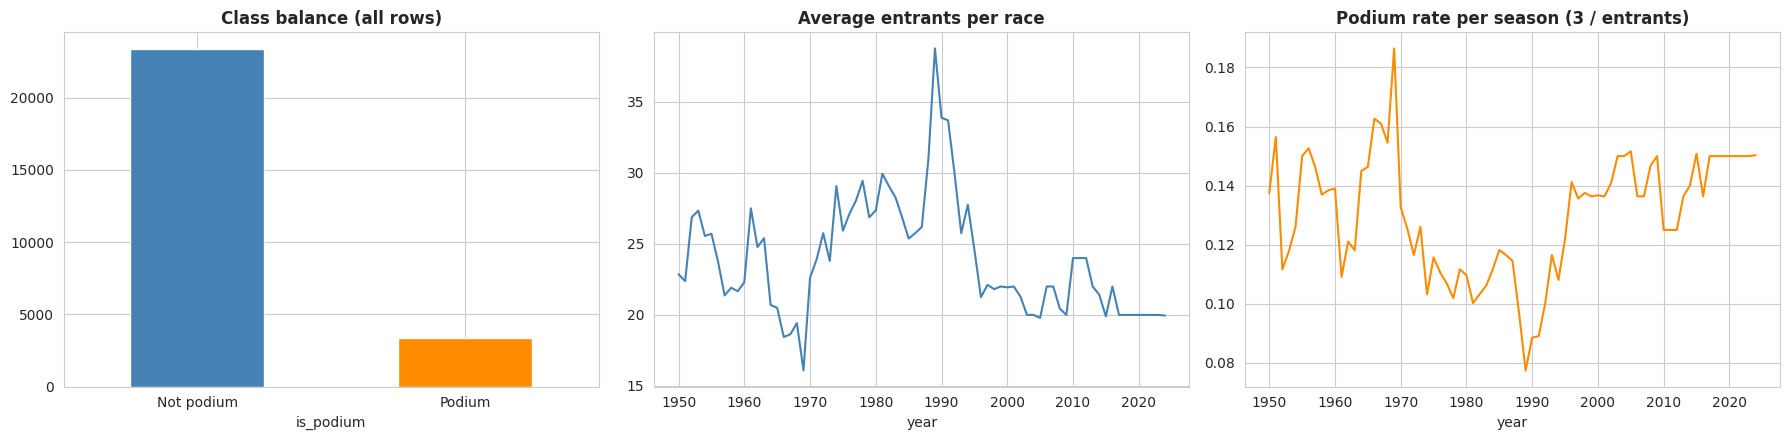

In [12]:
res = tables['results'].merge(races_y, on='raceId')
res['is_podium'] = (res['positionOrder'] <= 3).astype(int)

rate = res['is_podium'].mean()
print(f"Podium rows: {res['is_podium'].sum()} / {len(res)}  → {rate:.2%} positive class")

# Sanity check: a race should have exactly 3 podium rows
pod_per_race = res.groupby('raceId')['is_podium'].sum()
print("\nPodium rows per race (count of races):")
print(pod_per_race.value_counts().sort_index())

per_year = res.groupby('year').agg(
    entrants_per_race=('raceId', lambda s: s.value_counts().mean()),
    podium_rate=('is_podium', 'mean'))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
res['is_podium'].map({0: 'Not podium', 1: 'Podium'}).value_counts().plot.bar(
    ax=axes[0], color=['steelblue', 'darkorange'])
axes[0].set_title('Class balance (all rows)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)

per_year['entrants_per_race'].plot(ax=axes[1], color='steelblue')
axes[1].set_title('Average entrants per race', fontweight='bold')

per_year['podium_rate'].plot(ax=axes[2], color='darkorange')
axes[2].set_title('Podium rate per season (3 / entrants)', fontweight='bold')

plt.tight_layout()
plt.show()

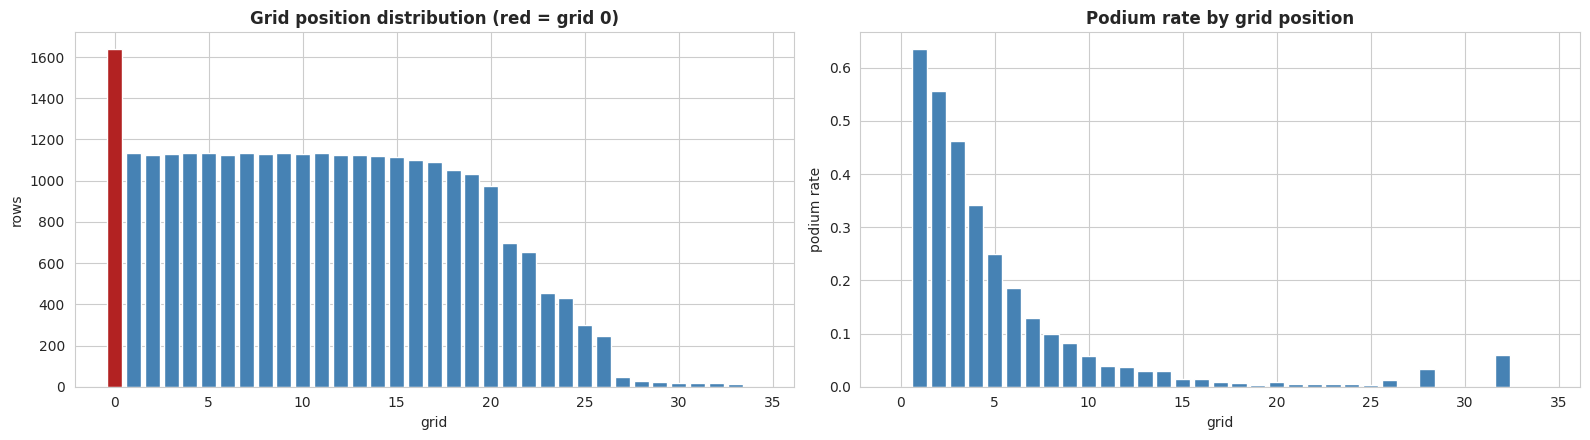

Rows with grid = 0: 1638 (6.12%)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

grid_counts = res['grid'].value_counts().sort_index()
axes[0].bar(grid_counts.index, grid_counts.values,
            color=['firebrick' if g == 0 else 'steelblue' for g in grid_counts.index])
axes[0].set_title('Grid position distribution (red = grid 0)', fontweight='bold')
axes[0].set_xlabel('grid'); axes[0].set_ylabel('rows')

pod_by_grid = res.groupby('grid')['is_podium'].mean()
axes[1].bar(pod_by_grid.index, pod_by_grid.values,
            color=['firebrick' if g == 0 else 'steelblue' for g in pod_by_grid.index])
axes[1].set_title('Podium rate by grid position', fontweight='bold')
axes[1].set_xlabel('grid'); axes[1].set_ylabel('podium rate')

plt.tight_layout()
plt.show()

print(f"Rows with grid = 0: {(res['grid'] == 0).sum()} ({(res['grid'] == 0).mean():.2%})")

### Findings — EDA before cleaning
**Types.** Dates (`races.date`, session dates, `drivers.dob`) and durations (`q1`/`q2`/`q3`, `fastestLapTime`, `lap_times.time`, `pit_stops.duration`) are stored as text and need semantic typing. `pit_stops.duration` is text because some values use `m:ss` format (long stops). `results.time` mixes absolute times and `+gap` strings; it is post-race and not used as a feature.

**Coverage drift.** `driver_standings` covers all seasons. `qualifying` is absent before 1994, partial between 1996 and 2002 (6–59% of driver entries), and complete from 2003. `lap_times` starts in 1996, `pit_stops` in 2011, fastest-lap fields around 2004. Qualifying-based features are therefore only reliable from 2003 onward.

**Class balance.** 12.69% of rows are podiums (≈1 in 8). Accuracy would be misleading, so we evaluate with ROC-AUC, PR-AUC and F1. The podium base rate also drifts by era (≈8% around 1990, ≈15% today) because field size changes (peak ≈39 entrants per race around 1989, ≈20 today).

**Grain issue confirmed.** 18 races have more than 3 podium rows, caused by shared drives (Section 1.4).

**Grid.** Podium rate falls steeply with grid position (≈63% from P1, ≈0% beyond P15), strong evidence for grid as a feature. Grid 0 (6.1% of rows) has almost no podiums and is investigated in Section 1.4. Spikes at grid 28/32 come from very small groups and are noise.

## 1.4 Cleaning
All cleaning happens on a copy (`clean`); `raw_tables` stays untouched.
### 1.4.1 Semantic typing
Date strings become datetime objects; duration strings (`m:ss.sss`, `h:mm:ss.sss`) become numeric seconds. Every conversion is checked for failures.

In [14]:
# Cleaning works on a copy
clean = {tbl: df.copy() for tbl, df in tables.items()}

# Drop the unusable column (99.87% missing, see 1.1)
clean['constructor_results'] = clean['constructor_results'].drop(columns='status')

def to_seconds(val):
    """'1:26.572' -> 86.572 | '26.898' -> 26.898 | '1:34:50.616' -> 5690.616"""
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.startswith('+'):          # gap strings ('+5.478') are not durations
        return np.nan
    try:
        parts = [float(p) for p in s.split(':')]
    except ValueError:
        return np.nan
    seconds = 0.0
    for p in parts:                # works for s, m:s and h:m:s
        seconds = seconds * 60 + p
    return seconds

typing_log = []

# Durations -> seconds
duration_cols = [('qualifying', 'q1'), ('qualifying', 'q2'), ('qualifying', 'q3'),
                 ('results', 'fastestLapTime'), ('pit_stops', 'duration'),
                 ('lap_times', 'time')]
for tbl, col in duration_cols:
    before = clean[tbl][col]
    after = before.apply(to_seconds)
    clean[tbl][f'{col}_sec'] = after
    typing_log.append({'table': tbl, 'column': col, 'new_column': f'{col}_sec',
                       'type': 'duration → seconds',
                       'non_null_before': int(before.notna().sum()),
                       'non_null_after': int(after.notna().sum()),
                       'failed': int((before.notna() & after.isna()).sum())})

# Dates -> datetime
date_cols = [('races', 'date'), ('races', 'fp1_date'), ('races', 'fp2_date'),
             ('races', 'fp3_date'), ('races', 'quali_date'), ('races', 'sprint_date'),
             ('drivers', 'dob')]
for tbl, col in date_cols:
    before = clean[tbl][col]
    after = pd.to_datetime(before, errors='coerce')
    clean[tbl][col] = after
    typing_log.append({'table': tbl, 'column': col, 'new_column': col,
                       'type': 'text → datetime',
                       'non_null_before': int(before.notna().sum()),
                       'non_null_after': int(after.notna().sum()),
                       'failed': int((before.notna() & after.isna()).sum())})

typing_log = pd.DataFrame(typing_log)
display(typing_log)

,table,column,new_column,type,non_null_before,non_null_after,failed
0,qualifying,q1,q1_sec,duration → seconds,10338,10338,0
1,qualifying,q2,q2_sec,duration → seconds,5847,5847,0
2,qualifying,q3,q3_sec,duration → seconds,3629,3629,0
3,results,fastestLapTime,fastestLapTime_sec,duration → seconds,8252,8252,0
4,pit_stops,duration,duration_sec,duration → seconds,11371,11371,0
5,lap_times,time,time_sec,duration → seconds,589081,589081,0
6,races,date,date,text → datetime,1125,1125,0
7,races,fp1_date,fp1_date,text → datetime,90,90,0
8,races,fp2_date,fp2_date,text → datetime,90,90,0
9,races,fp3_date,fp3_date,text → datetime,72,72,0


In [15]:
# lap_times has BOTH a text time and an integer 'milliseconds' column.
# If our parser is correct, time_sec * 1000 must equal milliseconds.
lt = clean['lap_times']
diff = (lt['time_sec'] * 1000 - lt['milliseconds']).abs()
print(f"Max difference (ms): {diff.max():.3f}")
print(f"Rows differing by > 1 ms: {(diff > 1).sum()}")

# Long pit stops written as m:ss (the reason 'duration' was text)
ps = clean['pit_stops']
colon_mask = ps['duration'].astype(str).str.contains(':')
print(f"\nPit stop durations written as m:ss: {colon_mask.sum()}")
display(ps.loc[colon_mask, ['raceId', 'driverId', 'stop', 'duration', 'duration_sec']].head())

Max difference (ms): 0.000
Rows differing by > 1 ms: 0

Pit stop durations written as m:ss: 517


,raceId,driverId,stop,duration,duration_sec
751,853,817,1,16:44.718,1004.718
2419,881,814,2,2:03.124,123.124
2420,881,16,2,1:29.401,89.401
2421,881,18,3,1:44.833,104.833
2422,884,16,1,1:14.026,74.026


Grid-0 rows: 1638 | podiums from grid 0: 0


,count
started_race,
0 laps,1566
completed ≥1 lap,72


,count
status,
Did not qualify,1013
Did not prequalify,331
Withdrew,164
+1 Lap,27
Finished,22
Accident,20
Injury,8
+2 Laps,7
Engine,6


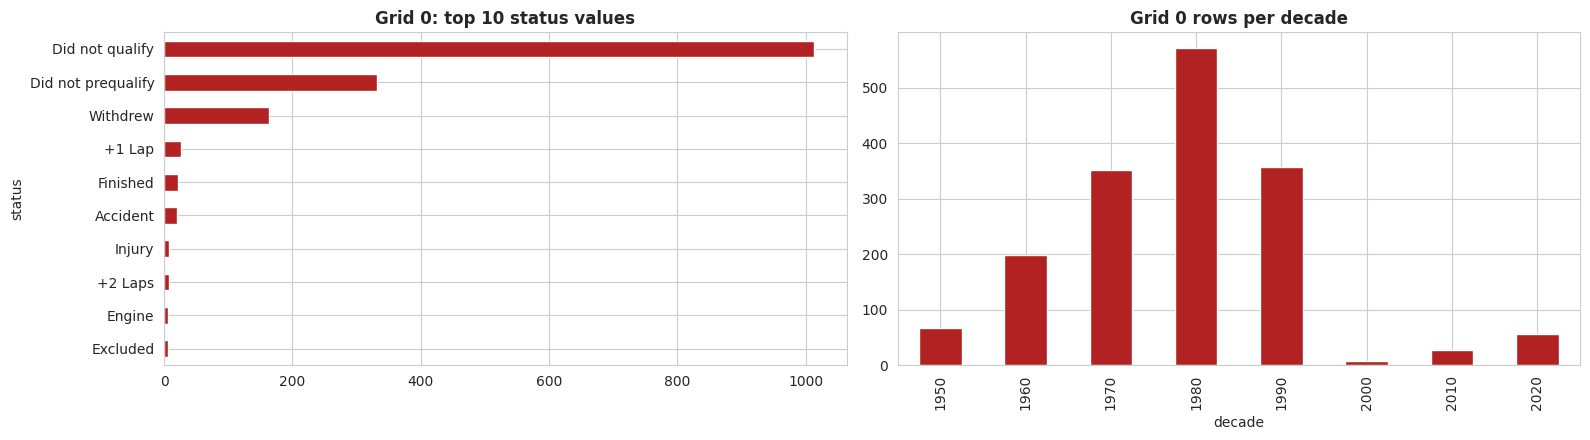

In [16]:
r = (clean['results']
     .merge(clean['status'], on='statusId', how='left')
     .merge(clean['races'][['raceId', 'year']], on='raceId', how='left')
     .merge(clean['drivers'][['driverId', 'surname']], on='driverId', how='left'))

g0 = r[r['grid'] == 0].copy()
g0['started_race'] = np.where(g0['laps'] > 0, 'completed ≥1 lap', '0 laps')

print(f"Grid-0 rows: {len(g0)} | podiums from grid 0: {(g0['positionOrder'] <= 3).sum()}")
display(g0['started_race'].value_counts().to_frame())
display(g0['status'].value_counts().head(15).to_frame('count'))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
g0['status'].value_counts().head(10).plot.barh(ax=axes[0], color='firebrick')
axes[0].invert_yaxis()
axes[0].set_title('Grid 0: top 10 status values', fontweight='bold')
g0.groupby((g0['year'] // 10) * 10).size().plot.bar(ax=axes[1], color='firebrick')
axes[1].set_title('Grid 0 rows per decade', fontweight='bold')
axes[1].set_xlabel('decade')
plt.tight_layout()
plt.show()

In [17]:
dups = r[r.duplicated(subset=['raceId', 'driverId'], keep=False)].copy()

print(f"Duplicate rows: {len(dups)} | pairs: {dups.groupby(['raceId','driverId']).ngroups}")
print(f"Seasons: {dups['year'].min()}–{dups['year'].max()}")
print("\nRows per pair:")
print(dups.groupby(['raceId', 'driverId']).size().value_counts().sort_index())

# How many rows in each pair have a real grid slot (grid > 0)?
print("\nRows with grid > 0 per pair:")
print(dups.groupby(['raceId', 'driverId'])['grid'].apply(lambda g: (g > 0).sum())
          .value_counts().sort_index())

cols = ['year', 'raceId', 'surname', 'constructorId', 'number',
        'grid', 'positionOrder', 'laps', 'points', 'status']
display(dups.sort_values(['raceId', 'driverId', 'laps'], ascending=[True, True, False])[cols].head(24))

Duplicate rows: 176 | pairs: 85
Seasons: 1950–1978

Rows per pair:
2    79
3     6
Name: count, dtype: int64

Rows with grid > 0 per pair:
grid
0     3
2    76
3     6
Name: count, dtype: int64


,year,raceId,surname,constructorId,number,grid,positionOrder,laps,points,status
13188,1978,540,Ertl,54,10.0,0,26,0,0.0,Did not qualify
13191,1978,540,Ertl,57,23.0,0,29,0,0.0,Did not prequalify
17362,1964,717,Clark,172,1.0,1,7,102,0.0,Out of fuel
24298,1964,717,Clark,172,2.0,1,12,54,0.0,Injection
17740,1962,733,Greene,172,48.0,0,22,0,0.0,Withdrew
17743,1962,733,Greene,97,50.0,0,25,0,0.0,Withdrew
17961,1961,742,Moss,102,26.0,20,19,56,0.0,Disqualified
17963,1961,742,Moss,172,28.0,5,21,44,0.0,Brakes
24297,1961,745,Gregory,172,21.0,15,11,92,0.0,+8 Laps
18062,1961,745,Gregory,172,22.0,11,17,23,0.0,Gearbox


### 1.4.1 Findings — typing
All 13 conversions succeeded with **0 failures**. Independent check: parsed `lap_times.time` × 1000 equals the `milliseconds` column with a maximum difference of **0.000 ms** over 589,081 laps. `pit_stops.duration` was text because 517 values use `m:ss` (e.g. `16:44.718` = 1,004.7 s, red-flag stoppage).

### 1.4.2 Grid 0 investigation
1,638 rows have `grid = 0`, with **0 podiums**. 1,566 (96%) completed 0 laps; their statuses are mainly *Did not qualify* (1,013), *Did not prequalify* (331) and *Withdrew* (164), concentrated in 1970–1990 (pre-qualifying era). The remaining 72 completed laps (pit-lane starts).
**Decision:** grid 0 mixes two meanings. Non-starters whose fate is fixed before the race (DNQ, DNPQ, Withdrew) are **flagged** (`pre_race_non_starter`) and excluded from the modeling table (Chapter 3), because a prediction for a driver who cannot start is trivial and would inflate scores with easy negatives. *Did not start* is kept: that driver held a grid slot and failed after the cutoff. Pit-lane starters are kept and handled in feature engineering.

### 1.4.3 Shared drives (duplicate raceId, driverId)
85 pairs (79 × 2 rows, 6 × 3 rows), seasons 1950–1978. Both rows usually have a grid slot (76 pairs have 2, 6 pairs have 3), so "has a grid slot" alone cannot pick one, and the data does not record which car the driver actually started in.

**Rule:** keep the row with the **best (lowest positive) grid**, tie-break lowest `resultId`.

**Why (evidence in the cell below):**
- **Outcome-based rules are leakage.** Keeping the best finish keeps **22 podiums** among the 85 pairs; "most laps" gives the same 22. The outcome-free rules keep only **5** (best grid) or **6** (lowest `resultId`). Choosing rows by result inflates podiums about 4.4×.
- **Best grid uses only pre-race information** with a clear meaning, while `resultId` is only database ordering.
- **Limitation:** the two outcome-free rules agree on 68.2% of pairs, so best grid is a proxy for the starting car, not a certainty. The impact is negligible: 85 of 26,668 rows (0.3%), all before 1979, outside the period with qualifying coverage.

,rule,podiums_kept,mean_positionOrder_kept
0,"Starting car (best grid, then lowest resultId)",5,14.69
1,Original entry (lowest resultId),6,15.95
2,Best finish (teammate rule),22,8.11
3,Most laps,22,8.11


Starting-car rule agrees with original-entry rule on 68.2% of pairs


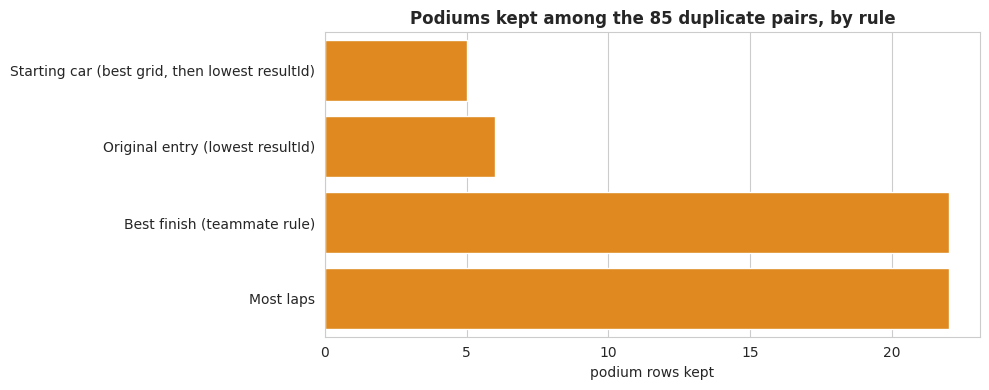

In [18]:
d = dups.copy()
d['grid_sort'] = d['grid'].astype(float).where(d['grid'] > 0, np.inf)   # grid 0 goes last
keys = ['raceId', 'driverId']

rules = {
    'Starting car (best grid, then lowest resultId)':
        d.sort_values(keys + ['grid_sort', 'resultId']).groupby(keys).head(1),
    'Original entry (lowest resultId)':
        d.sort_values(keys + ['resultId']).groupby(keys).head(1),
    'Best finish (teammate rule)':
        d.sort_values(keys + ['positionOrder']).groupby(keys).head(1),
    'Most laps':
        d.sort_values(keys + ['laps'], ascending=[True, True, False]).groupby(keys).head(1),
}

rule_cmp = pd.DataFrame([{
    'rule': name,
    'podiums_kept': int((kept['positionOrder'] <= 3).sum()),
    'mean_positionOrder_kept': round(kept['positionOrder'].mean(), 2),
} for name, kept in rules.items()])
display(rule_cmp)

agree = rules['Starting car (best grid, then lowest resultId)']['resultId'].isin(
        rules['Original entry (lowest resultId)']['resultId']).mean()
print(f"Starting-car rule agrees with original-entry rule on {agree:.1%} of pairs")

plt.figure(figsize=(10, 4))
sns.barplot(data=rule_cmp, y='rule', x='podiums_kept', color='darkorange')
plt.title('Podiums kept among the 85 duplicate pairs, by rule', fontweight='bold')
plt.xlabel('podium rows kept'); plt.ylabel('')
plt.tight_layout()
plt.show()

In [19]:
res_clean = clean['results'].copy()
before = len(res_clean)

res_clean['grid_sort'] = res_clean['grid'].astype(float).where(res_clean['grid'] > 0, np.inf)
res_clean = (res_clean
             .sort_values(['raceId', 'driverId', 'grid_sort', 'resultId'])
             .drop_duplicates(subset=['raceId', 'driverId'], keep='first')
             .drop(columns='grid_sort')
             .sort_values('resultId')
             .reset_index(drop=True))

assert not res_clean.duplicated(subset=['raceId', 'driverId']).any(), "Grain violated!"
clean['results'] = res_clean

print(f"results rows: {before} → {len(res_clean)} (removed {before - len(res_clean)})")
print("Grain verified: exactly one row per (raceId, driverId).")

results rows: 26759 → 26668 (removed 91)
Grain verified: exactly one row per (raceId, driverId).


In [20]:
status_map = clean['status'].set_index('statusId')['status']
clean['results']['status'] = clean['results']['statusId'].map(status_map)

PRE_RACE_NON_STARTER = ['Did not qualify', 'Did not prequalify', 'Withdrew']
clean['results']['pre_race_non_starter'] = clean['results']['status'].isin(PRE_RACE_NON_STARTER)

flag = clean['results']['pre_race_non_starter']
print(f"Flagged non-starters: {flag.sum()} ({flag.mean():.2%} of rows)")
print(f"Of those, rows with laps > 0 (should be 0): {(clean['results'].loc[flag, 'laps'] > 0).sum()}")
print(f"Of those, podiums (should be 0): {(clean['results'].loc[flag, 'positionOrder'] <= 3).sum()}")
display(clean['results'].loc[flag, 'status'].value_counts().to_frame('count'))

Flagged non-starters: 1601 (6.00% of rows)
Of those, rows with laps > 0 (should be 0): 24
Of those, podiums (should be 0): 0


,count
status,
Did not qualify,1024
Did not prequalify,330
Withdrew,247


In [21]:
fr = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId', how='left')
flagged = fr[fr['pre_race_non_starter']].copy()
flagged['has_grid_slot'] = flagged['grid'] > 0
flagged['drove_laps'] = flagged['laps'] > 0

# Status x grid slot x laps
display(pd.crosstab([flagged['status'], flagged['has_grid_slot']], flagged['drove_laps'],
                    margins=True))

# The suspicious rows: flagged but drove laps
cols = ['year', 'raceId', 'driverId', 'grid', 'laps', 'positionOrder', 'status']
display(flagged[flagged['drove_laps']][cols].sort_values('year'))

# Flagged with a grid slot but 0 laps
display(flagged[flagged['has_grid_slot'] & ~flagged['drove_laps']][cols]
        .sort_values('year').head(15))

drove_laps                        False  True   All
status             has_grid_slot                   
Did not prequalify False            330     0   330
Did not qualify    False           1012     0  1012
                   True              11     1    12
Withdrew           False            163     0   163
                   True              61    23    84
All                                1577    24  1601

,year,raceId,driverId,grid,laps,positionOrder,status
19624,1952,817,475,9,24,12,Withdrew
19625,1952,817,651,12,24,13,Withdrew
17640,1962,729,456,17,12,17,Withdrew
17686,1962,731,418,8,13,17,Withdrew
15923,1970,644,345,5,4,14,Withdrew
15186,1973,614,259,21,8,19,Withdrew
14949,1974,604,319,26,25,21,Withdrew
14256,1975,579,290,21,1,23,Withdrew
14257,1975,579,232,25,1,24,Withdrew
14154,1976,575,224,23,9,21,Withdrew


,year,raceId,driverId,grid,laps,positionOrder,status
20147,1950,839,697,23,0,27,Withdrew
19974,1951,831,686,8,0,21,Withdrew
19975,1951,831,781,10,0,22,Withdrew
19311,1954,803,689,26,0,31,Withdrew
19335,1954,804,663,22,0,23,Withdrew
19216,1954,799,496,9,0,18,Withdrew
19334,1954,804,633,10,0,22,Withdrew
19215,1954,799,577,7,0,17,Withdrew
19312,1954,803,690,29,0,32,Withdrew
19373,1954,806,694,21,0,21,Did not qualify


In [22]:
# Attempt 2: a non-starter must also have NO grid slot (pre-race information).
# Laps is post-race, so it is used only as a check, never in the rule.
clean['results']['pre_race_non_starter'] = (
    clean['results']['status'].isin(PRE_RACE_NON_STARTER) &
    (clean['results']['grid'] == 0)
)

flag = clean['results']['pre_race_non_starter']
print(f"Flagged non-starters: {flag.sum()} ({flag.mean():.2%} of rows)")
print(f"Of those, rows with laps > 0 (should be 0): {(clean['results'].loc[flag, 'laps'] > 0).sum()}")
print(f"Of those, podiums (should be 0): {(clean['results'].loc[flag, 'positionOrder'] <= 3).sum()}")
display(clean['results'].loc[flag, 'status'].value_counts().to_frame('count'))

Flagged non-starters: 1505 (5.64% of rows)
Of those, rows with laps > 0 (should be 0): 0
Of those, podiums (should be 0): 0


,count
status,
Did not qualify,1012
Did not prequalify,330
Withdrew,163


### 1.4.4 Pre-race non-starter flag: two attempts
**Attempt 1** (status in *Did not qualify*, *Did not prequalify*, *Withdrew*) flagged 1,601 rows, but **24 of them drove laps**, so the check failed.

**Investigation** (cross-tab above): all 1,505 flagged rows with `grid = 0` drove 0 laps, and all 24 contradictions had a grid slot. *Withdrew* has two meanings in this dataset: withdrawn **before** the race (no grid slot) or **during** the race (e.g. 2013, 2019, 2020, 2023 entries withdrew after 47–55 laps).

**Attempt 2 (final):** non-starter = status in the list **and** `grid = 0`. The rule uses only pre-race information (grid); laps is post-race and used only for validation. 72 drivers with a grid slot but 0 laps stay in the modeling table: at the cutoff they are on the grid, and their non-start happens afterwards (same treatment as *Did not start*).

## 1.5 EDA after cleaning
The same views as Section 1.3, repeated on the cleaned data to measure the impact of each cleaning step. "Before" = raw values with sentinels converted only; "after" = typed, de-duplicated, with pre-race non-starters flagged.

In [23]:
races_y = clean['races'][['raceId', 'year']]

before_df = tables['results'].merge(races_y, on='raceId')
before_df['is_podium'] = (before_df['positionOrder'] <= 3).astype(int)

after_df = clean['results'].merge(races_y, on='raceId')
after_df['is_podium'] = (after_df['positionOrder'] <= 3).astype(int)
starters = after_df[~after_df['pre_race_non_starter']]

def races_over_3_podiums(df):
    return int((df.groupby('raceId')['is_podium'].sum() > 3).sum())

def n_dup_pairs(df):
    return int(df[df.duplicated(['raceId', 'driverId'], keep=False)]
               .groupby(['raceId', 'driverId']).ngroups)

# Typed columns still stored as text (should be 0 after cleaning)
untyped_after = (
    sum(not pd.api.types.is_numeric_dtype(clean[t][f'{c}_sec']) for t, c in duration_cols) +
    sum(not pd.api.types.is_datetime64_any_dtype(clean[t][c]) for t, c in date_cols))

summary = pd.DataFrame([
    ['results rows',                        len(before_df),             len(after_df)],
    ['duplicate (raceId, driverId) pairs',  n_dup_pairs(before_df),     n_dup_pairs(after_df)],
    ['races with > 3 podium rows',          races_over_3_podiums(before_df), races_over_3_podiums(after_df)],
    ['date/duration columns stored as text', len(duration_cols) + len(date_cols), untyped_after],
    ['pre-race non-starters flagged',       0,                          int(after_df['pre_race_non_starter'].sum())],
    ['rows eligible for modeling',          len(before_df),             len(starters)],
    ['podium rate (%)',                     round(100 * before_df['is_podium'].mean(), 2),
                                            round(100 * starters['is_podium'].mean(), 2)],
], columns=['metric', 'before', 'after'])
display(summary)

,metric,before,after
0,results rows,26759.00,26668.00
1,"duplicate (raceId, driverId) pairs",85.00,0.00
2,races with > 3 podium rows,18.00,5.00
3,date/duration columns stored as text,13.00,0.00
4,pre-race non-starters flagged,0.00,1505.00
5,rows eligible for modeling,26759.00,25163.00
6,podium rate (%),12.69,13.42


In [24]:
pod = after_df.groupby('raceId')['is_podium'].sum()
print("Podium rows per race AFTER de-duplication:")
print(pod.value_counts().sort_index())

over = pod[pod > 3].index
detail = (after_df[after_df['raceId'].isin(over) & (after_df['is_podium'] == 1)]
          .merge(clean['drivers'][['driverId', 'surname']], on='driverId')
          [['year', 'raceId', 'surname', 'constructorId', 'number', 'grid', 'positionOrder']]
          .sort_values(['raceId', 'positionOrder']))
display(detail)

Podium rows per race AFTER de-duplication:
is_podium
2       3
3    1117
4       4
5       1
Name: count, dtype: int64


,year,raceId,surname,constructorId,number,grid,positionOrder
0,1955,792,Fangio,131,2.0,3,1
1,1955,792,González,6,12.0,1,2
16,1955,792,Farina,6,12.0,1,2
17,1955,792,Trintignant,6,12.0,1,2
18,1955,792,Maglioli,6,10.0,5,3
2,1955,793,Trintignant,6,44.0,9,1
3,1955,793,Castellotti,132,30.0,4,2
4,1955,793,Behra,105,34.0,5,3
19,1955,793,Perdisa,105,34.0,5,3
5,1955,794,Sweikert,113,6.0,14,1


In [25]:
# Programmatic check: in every race with > 3 podium rows, any podium position
# held by several drivers must belong to ONE car (shared drive), not to different cars.
shared = (detail.groupby(['raceId', 'positionOrder'])
          .agg(drivers=('surname', 'count'), cars=('number', 'nunique'),
               names=('surname', lambda s: ', '.join(s))))
shared_pos = shared[shared['drivers'] > 1]
display(shared_pos)

assert (shared_pos['cars'] == 1).all(), "A shared podium position involves different cars!"
print(f"Verified: all {len(shared_pos)} multi-driver podium positions are one shared car.")

,,drivers,cars,names
raceId,positionOrder,,,
792,2,3,1,"González, Farina, Trintignant"
793,3,2,1,"Behra, Perdisa"
794,2,2,1,"Bettenhausen, Russo"
809,3,2,1,"Hanks, Carter"
826,3,2,1,"McGrath, Ayulo"


Verified: all 5 multi-driver podium positions are one shared car.


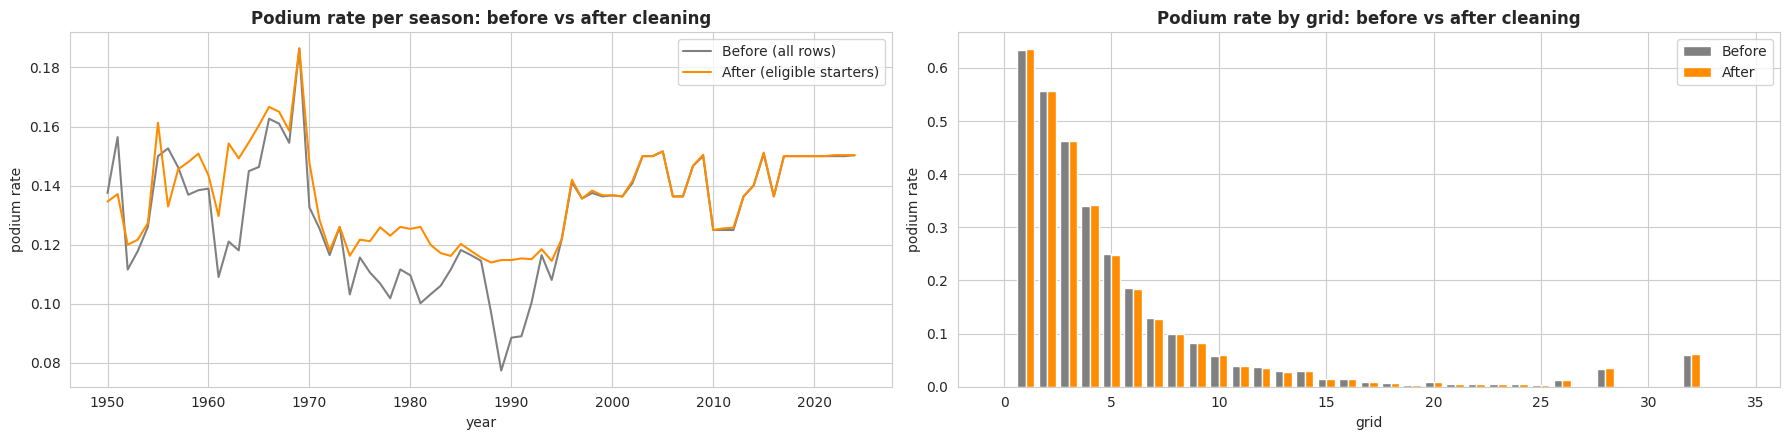

Grid 0 BEFORE: 1638 rows | AFTER (eligible): 130 rows, podiums: 0


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))

# Podium rate per season: before (all rows) vs after (eligible starters)
before_df.groupby('year')['is_podium'].mean().plot(ax=axes[0], label='Before (all rows)', color='grey')
starters.groupby('year')['is_podium'].mean().plot(ax=axes[0], label='After (eligible starters)', color='darkorange')
axes[0].set_title('Podium rate per season: before vs after cleaning', fontweight='bold')
axes[0].set_ylabel('podium rate'); axes[0].legend()

# Podium rate by grid: before vs after (grid 0 after = pit-lane starts only)
b = before_df.groupby('grid')['is_podium'].mean()
a = starters.groupby('grid')['is_podium'].mean()
axes[1].bar(b.index - 0.2, b.values, width=0.4, label='Before', color='grey')
axes[1].bar(a.index + 0.2, a.values, width=0.4, label='After', color='darkorange')
axes[1].set_title('Podium rate by grid: before vs after cleaning', fontweight='bold')
axes[1].set_xlabel('grid'); axes[1].set_ylabel('podium rate'); axes[1].legend()

plt.tight_layout()
plt.show()

g0_after = starters[starters['grid'] == 0]
print(f"Grid 0 BEFORE: {(before_df['grid'] == 0).sum()} rows | "
      f"AFTER (eligible): {len(g0_after)} rows, podiums: {g0_after['is_podium'].sum()}")

,Qualifying Q1 time (s),Fastest lap time (s),Pit stop duration (s)
count,10338.00,8252.00,11371.00
mean,88.53,90.83,85.23
std,15.39,12.34,310.43
min,53.90,55.40,12.90
25%,78.77,80.85,21.94
50%,87.14,90.27,23.61
75%,95.91,99.48,26.54
max,1002.64,202.30,3069.02


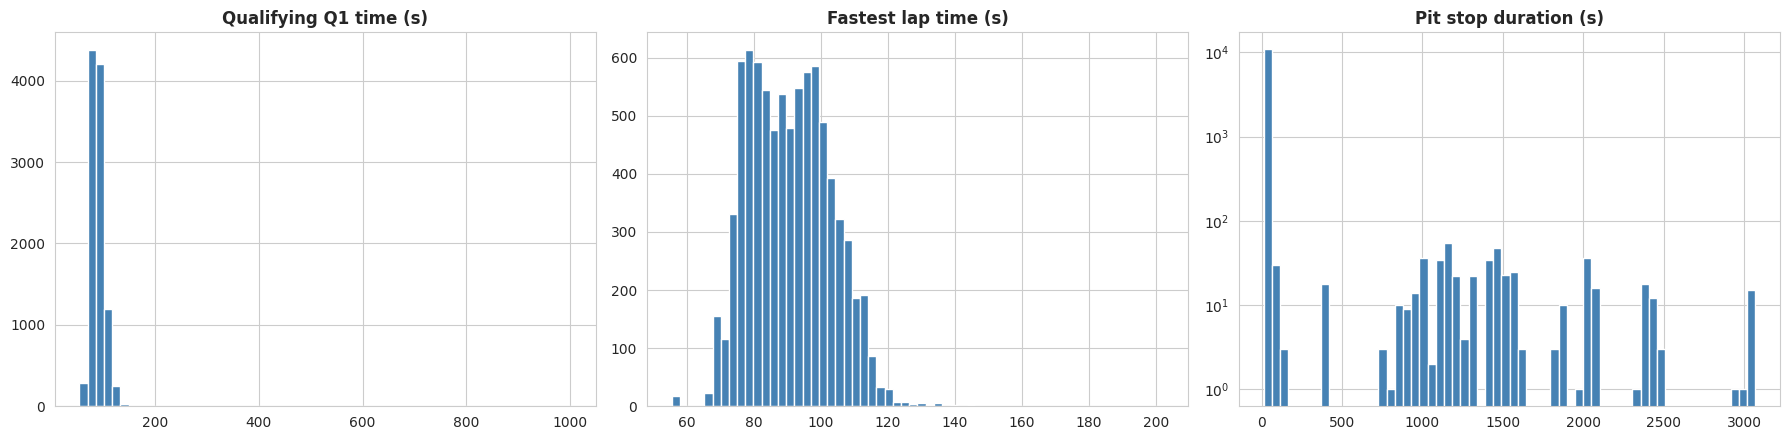

In [27]:
new_cols = {
    'Qualifying Q1 time (s)':       clean['qualifying']['q1_sec'],
    'Fastest lap time (s)':         clean['results']['fastestLapTime_sec'],
    'Pit stop duration (s)':        clean['pit_stops']['duration_sec'],
}
display(pd.DataFrame({k: v.describe() for k, v in new_cols.items()}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, s) in zip(axes, new_cols.items()):
    ax.hist(s.dropna(), bins=60, color='steelblue')
    ax.set_title(name, fontweight='bold')
axes[2].set_yscale('log')   # a few very long red-flag stops would hide the rest
plt.tight_layout()
plt.show()

In [28]:
# Raw files remain immutable: the raw text copies still match the CSV files exactly
for tbl in table_names:
    fresh = pd.read_csv(os.path.join(DATASET_DIR, f"{tbl}.csv"), dtype=str, keep_default_na=False)
    assert raw_tables[tbl].equals(fresh), f"{tbl}: raw copy was modified!"
print(f"Verified: all {len(table_names)} raw tables are unchanged; all cleaning was done on copies "
      f"(tables -> clean). Kaggle input files are also read-only.")

Verified: all 14 raw tables are unchanged; all cleaning was done on copies (tables -> clean). Kaggle input files are also read-only.


### Findings — EDA after cleaning (impact of cleaning)
| Metric | Before | After |
|---|---|---|
| results rows | 26,759 | 26,668 |
| duplicate (raceId, driverId) pairs | 85 | 0 |
| races with > 3 podium rows | 18 | 5 |
| date/duration columns stored as text | 13 | 0 |
| pre-race non-starters flagged | 0 | 1,505 |
| rows eligible for modeling | 26,759 | 25,163 |
| podium rate | 12.69% | 13.42% |

- **Remaining > 3 podium races (5)** are legitimate: different drivers shared one podium car (same car number and `positionOrder`, e.g. 1955 race 792: González, Farina, Trintignant in car #12, P2). Several are Indianapolis 500 races (part of the championship in the 1950s). The grain (one row per driver per race) holds.
- **3 races now have only 2 podium rows**, an expected side effect of the duplicate rule: the dropped row was a mid-race takeover car that finished on the podium. Each label describes the driver's starting car. All pre-1979.
- **Podium rate rose 12.69% → 13.42%** because non-starters (always negative) were removed. The effect is concentrated in 1960–1995 (≈7.8% → ≈11.5% around 1990, the pre-qualifying era); identical after 1996.
- **Grid 0** shrank from 1,638 to 130 rows and now contains only real starters without a normal grid slot (0 podiums).
- **Raw data untouched:** the raw text copies are re-checked against the CSV files after cleaning (assert above); every change was made on copies (`tables` → `clean`).
- **Typed columns reveal implausible values:** `q1` max = 1,002.6 s (median 87 s), handled when building qualifying features (Chapter 3); pit-stop durations of ~800–3,069 s are red-flag suspensions (post-race, not used as features). Raw lap times vary by circuit (55–202 s), so qualifying features must be relative to the session, not absolute.

# 2. Data-Engineering Questions
All three questions use a shared base table built with multi-hop joins: `results` → `races` → `circuits`, plus `qualifying` on (`raceId`, `driverId`). Pre-race non-starters (Section 1.4.4) are excluded, so every row is a driver who took a grid slot.

**Grain:** one row per (`raceId`, `driverId`), verified after each join.

In [29]:
from scipy.stats import spearmanr

base = (clean['results'][~clean['results']['pre_race_non_starter']]
        [['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'laps', 'statusId', 'status']]
        .merge(clean['races'][['raceId', 'year', 'round', 'circuitId']], on='raceId', how='left')
        .merge(clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'}),
               on='circuitId', how='left')
        .merge(clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
               on=['raceId', 'driverId'], how='left'))

base['is_podium'] = (base['positionOrder'] <= 3).astype(int)

assert not base.duplicated(['raceId', 'driverId']).any(), "Grain violated after joins!"
print(f"Base table: {base.shape[0]} rows | grain verified: one row per (raceId, driverId)")

Base table: 25163 rows | grain verified: one row per (raceId, driverId)


## Q1 — Front-row conversion by circuit, pre-hybrid vs hybrid era
**Window:** 2003–2024 only. Qualifying coverage is complete from 2003 (Section 1.3), and since then the grid has two cars per row, so positions 1–2 are exactly the front row. Pre-hybrid = 2003–2013, hybrid = 2014–2024 (11 seasons each).
**Two definitions:** front row by **grid** (actual starting slot, after penalties) and by **qualifying position** (before penalties).
**Small samples:** a circuit is ranked only with ≥ 10 front-row starts in **each** era. Ranking stability is measured with Spearman rank correlation.

In [30]:
q1 = base[base['year'].between(2003, 2024)].copy()
ERAS = ['Pre-hybrid (2003–2013)', 'Hybrid (2014–2024)']
q1['era'] = np.where(q1['year'] >= 2014, ERAS[1], ERAS[0])
q1['front_row_grid'] = q1['grid'].isin([1, 2])
q1['front_row_quali'] = q1['quali_pos'].isin([1, 2])

print(f"Rows 2003–2024: {len(q1)} | missing qualifying position: {q1['quali_pos'].isna().sum()}")

# Where do the two definitions disagree?
print("\nFront row by qualifying (rows) vs front row by grid (columns):")
display(pd.crosstab(q1['front_row_quali'], q1['front_row_grid'], margins=True))

# Overall conversion rate per era, for each definition
overall = pd.DataFrame({
    'Front row by GRID': q1[q1['front_row_grid']].groupby('era')['is_podium'].agg(['count', 'mean']).stack(),
    'Front row by QUALIFYING': q1[q1['front_row_quali']].groupby('era')['is_podium'].agg(['count', 'mean']).stack(),
}).unstack().round(3)
display(overall)

# Starting from the front row by grid, without having qualified there (and vice versa)
promoted = q1[q1['front_row_grid'] & ~q1['front_row_quali']]
demoted = q1[q1['front_row_quali'] & ~q1['front_row_grid']]
print(f"\nQualified P1–P2 but did NOT start there (penalty/sprint): {len(demoted)} "
      f"→ podium rate {demoted['is_podium'].mean():.2%}")
print(f"Started P1–P2 without qualifying there (promoted):        {len(promoted)} "
      f"→ podium rate {promoted['is_podium'].mean():.2%}")

Rows 2003–2024: 8961 | missing qualifying position: 23

Front row by qualifying (rows) vs front row by grid (columns):


front_row_grid,False,True,All
front_row_quali,,,
False,8069,36,8105
True,38,818,856
All,8107,854,8961


Front row by GRID       Front row by QUALIFYING       
                                   count  mean                   count   mean
era                                                                          
Hybrid (2014–2024)                 454.0  0.76                   456.0  0.737
Pre-hybrid (2003–2013)             400.0  0.68                   400.0  0.672


Qualified P1–P2 but did NOT start there (penalty/sprint): 38 → podium rate 28.95%
Started P1–P2 without qualifying there (promoted):        36 → podium rate 63.89%


In [31]:
MIN_STARTS = 10

def circuit_conversion(df, flag):
    g = (df[df[flag]].groupby(['circuit', 'era'])['is_podium']
         .agg(starts='count', rate='mean').unstack('era'))
    g.columns = [f'{m} | {e}' for m, e in g.columns]
    ok = (g[f'starts | {ERAS[0]}'] >= MIN_STARTS) & (g[f'starts | {ERAS[1]}'] >= MIN_STARTS)
    g = g[ok].copy()
    for e in ERAS:
        g[f'rank | {e}'] = g[f'rate | {e}'].rank(ascending=False, method='min').astype(int)
    g['rank change'] = g[f'rank | {ERAS[0]}'] - g[f'rank | {ERAS[1]}']   # + = moved up
    return g.sort_values(f'rate | {ERAS[1]}', ascending=False)

conv_grid = circuit_conversion(q1, 'front_row_grid')
conv_quali = circuit_conversion(q1, 'front_row_quali')

for name, g in [('GRID', conv_grid), ('QUALIFYING', conv_quali)]:
    rho, p = spearmanr(g[f'rate | {ERAS[0]}'], g[f'rate | {ERAS[1]}'])
    print(f"{name:<11} circuits ranked: {len(g)} | Spearman rho = {rho:.2f} (p = {p:.3f})")

display(conv_grid.round(2))

GRID        circuits ranked: 14 | Spearman rho = 0.30 (p = 0.292)
QUALIFYING  circuits ranked: 14 | Spearman rho = 0.57 (p = 0.033)


,starts | Hybrid (2014–2024),starts | Pre-hybrid (2003–2013),rate | Hybrid (2014–2024),rate | Pre-hybrid (2003–2013),rank | Pre-hybrid (2003–2013),rank | Hybrid (2014–2024),rank change
circuit,,,,,,,
Suzuka Circuit,18.0,18.0,0.89,0.72,4,1,3
Yas Marina Circuit,22.0,10.0,0.86,0.60,10,2,8
Circuit de Monaco,20.0,22.0,0.85,0.77,1,3,-2
Circuit de Spa-Francorchamps,22.0,18.0,0.82,0.72,4,4,0
Circuit de Barcelona-Catalunya,22.0,22.0,0.82,0.68,6,4,2
Autódromo José Carlos Pace,19.0,22.0,0.79,0.59,12,6,6
Shanghai International Circuit,14.0,20.0,0.79,0.65,8,7,1
Circuit Gilles Villeneuve,18.0,20.0,0.78,0.60,10,8,2
Silverstone Circuit,24.0,22.0,0.75,0.73,3,9,-6


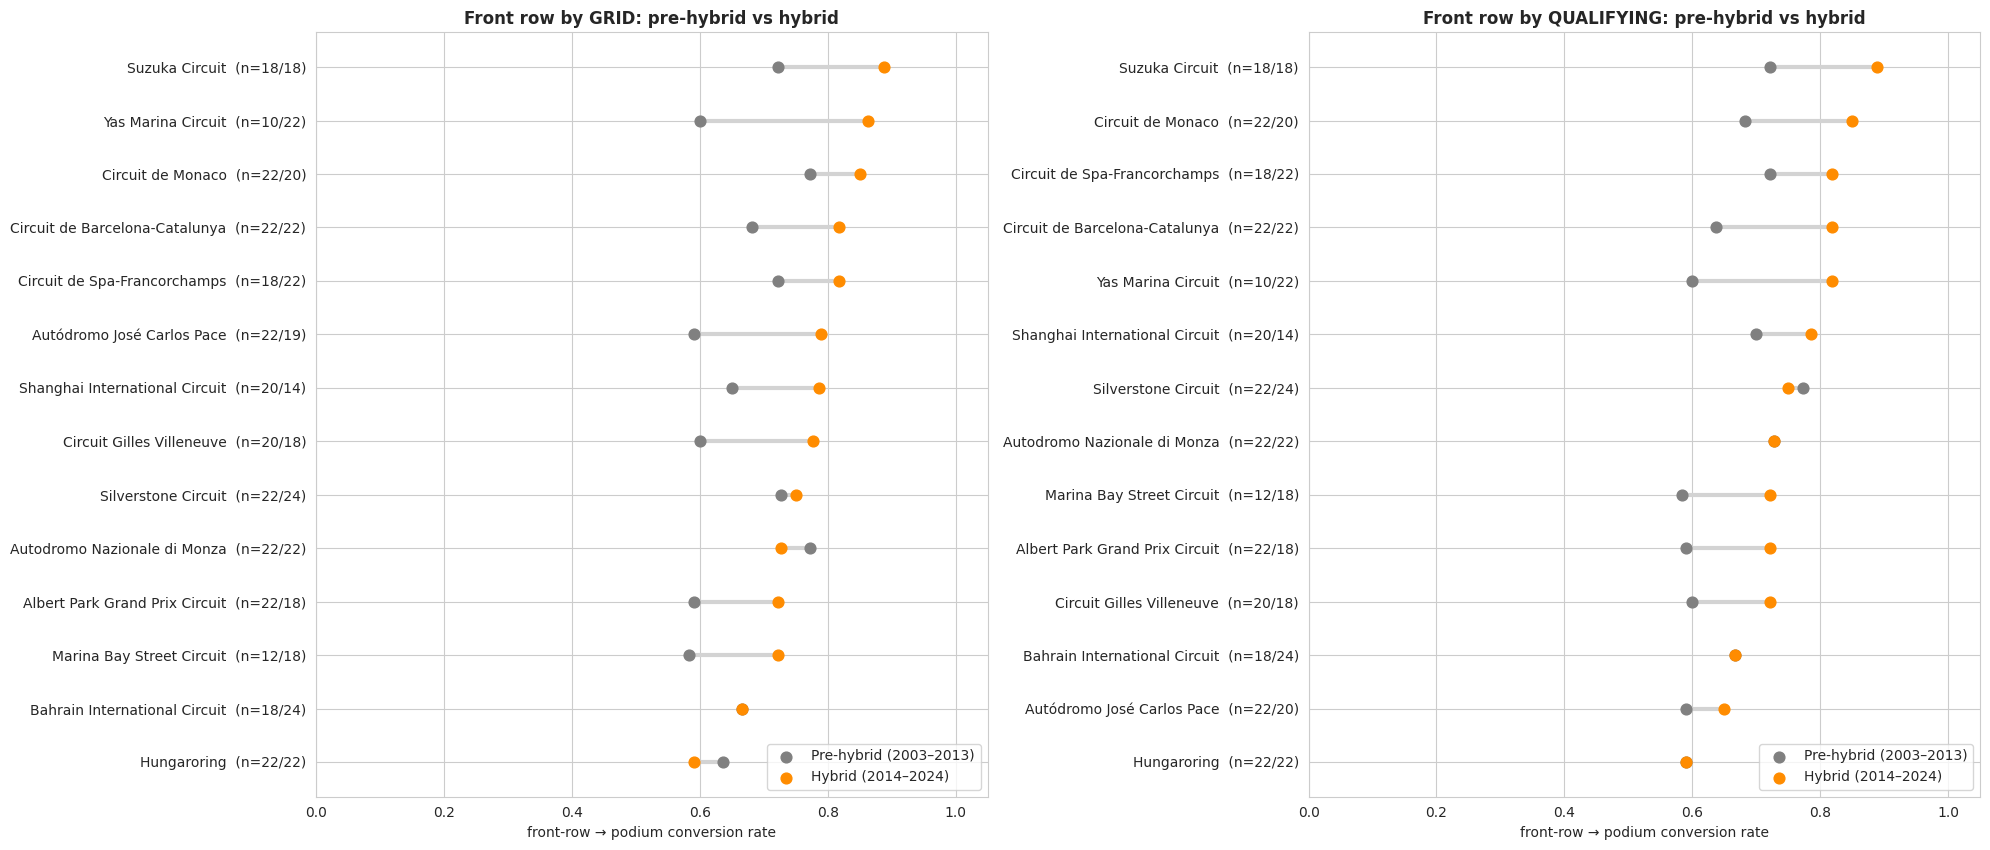

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(20, 0.4 * len(conv_grid) + 3))

for ax, (name, g) in zip(axes, [('GRID', conv_grid), ('QUALIFYING', conv_quali)]):
    g = g.sort_values(f'rate | {ERAS[1]}')
    y = np.arange(len(g))
    ax.hlines(y, g[f'rate | {ERAS[0]}'], g[f'rate | {ERAS[1]}'], color='lightgrey', lw=3)
    ax.scatter(g[f'rate | {ERAS[0]}'], y, color='grey', s=60, label=ERAS[0], zorder=3)
    ax.scatter(g[f'rate | {ERAS[1]}'], y, color='darkorange', s=60, label=ERAS[1], zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{c}  (n={int(g.loc[c, f'starts | {ERAS[0]}'])}/{int(g.loc[c, f'starts | {ERAS[1]}'])})"
                        for c in g.index])
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('front-row → podium conversion rate')
    ax.set_title(f'Front row by {name}: pre-hybrid vs hybrid', fontweight='bold')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### Q1 — Answer
**Overall:** front-row conversion rose in the hybrid era: by grid **68% → 76%** (n = 400 / 454), by qualifying **67% → 74%**. 11 of 14 ranked circuits increased, 1 is unchanged (Bahrain), 2 decreased (Monza, Hungaroring), so the main change is a general upward shift.

**Top circuits (grid definition):**
- *Pre-hybrid:* Monaco and Monza (77%), Silverstone (73%).
- *Hybrid:* Suzuka (89%), Yas Marina (86%), Monaco (85%).
- Monaco is top 3 in both eras; Hungaroring is last in the hybrid era (59%).

**Did the ranking change?** By grid, substantially: Spearman ρ = **0.30** (p = 0.29). Biggest movers: Yas Marina 10 → 2, Interlagos 12 → 6; Monza 1 → 10, Silverstone 3 → 9, Bahrain 7 → 13. By qualifying position the ranking is moderately stable (ρ = **0.57**, p = 0.03).

**Qualifying vs grid:** the definitions disagree in ~4–5% of front-row cases (penalties, 2021–22 sprint grids). Drivers who qualified P1–P2 but started further back podiumed **29%** of the time (n = 38), while drivers promoted to P1–P2 podiumed **64%** (n = 36): **starting position matters more than qualifying pace**. This supports using `grid` as a feature and keeping qualifying position alongside it (Chapter 3).

**Grain:** one row per (raceId, driverId); front row = 2 rows per race.
**Missingness:** window restricted to 2003–2024 (complete qualifying coverage, 2-wide grid); 23 rows (0.26%) lack a qualifying position and count as "not front row" by qualifying.
**Cutoff:** grid and qualifying position are both known before the start; the finishing position is used only as the outcome.
**Limitations:** each circuit rate rests on 10–24 starts, so part of the rank change is sampling noise (e.g. Yas Marina pre-hybrid n = 10). Results describe association, not cause.

## Q2 — Home advantage, controlling for starting position
**Home race:** the circuit's country (`circuits.country`) matches the driver's nationality (`drivers.nationality`), using an explicit nationality → country map. Dual nationalities count as home in either country; unmapped nationalities are excluded (not treated as "away").
**Control for starting position:** home and away drivers are compared within grid bands (P1, P2, P3, P4–6, P7–10, P11+), so the effect is not explained by home drivers qualifying better.
**Estimates:** (1) Mantel–Haenszel pooled odds ratio across grid bands; (2) logistic regression `is_podium ~ is_home + C(grid_band)`; (3) grid-standardized difference in podium rate (percentage points).
**Robustness:** repeated without the 1950–1960 Indianapolis 500 (an almost entirely American field).
**Rows:** starters with a grid slot (`grid > 0`), all seasons.

In [33]:
NAT_TO_COUNTRIES = {
    'British': ['UK'], 'German': ['Germany'], 'East German': ['Germany'],
    'Italian': ['Italy'], 'French': ['France'], 'Spanish': ['Spain'],
    'Brazilian': ['Brazil'], 'Australian': ['Australia'], 'American': ['USA'],
    'American-Italian': ['USA', 'Italy'], 'Argentine': ['Argentina'],
    'Argentinian': ['Argentina'],   # FIX: spelling variant found by Diagnostic 1
    'Argentine-Italian': ['Argentina', 'Italy'], 'Austrian': ['Austria'],
    'Dutch': ['Netherlands'], 'Belgian': ['Belgium'], 'Japanese': ['Japan'],
    'Canadian': ['Canada'], 'Finnish': ['Finland'], 'Mexican': ['Mexico'],
    'Monegasque': ['Monaco'], 'Swiss': ['Switzerland'], 'Swedish': ['Sweden'],
    'New Zealander': ['New Zealand'], 'South African': ['South Africa'],
    'Portuguese': ['Portugal'], 'Hungarian': ['Hungary'], 'Malaysian': ['Malaysia'],
    'Russian': ['Russia'], 'Chinese': ['China'], 'Indian': ['India'],
    'Danish': ['Denmark'], 'Polish': ['Poland'], 'Thai': ['Thailand'],
    'Indonesian': ['Indonesia'], 'Venezuelan': ['Venezuela'], 'Colombian': ['Colombia'],
    'Chilean': ['Chile'], 'Czech': ['Czech Republic'], 'Irish': ['Ireland'],
    'Uruguayan': ['Uruguay'], 'Rhodesian': ['Rhodesia'], 'Liechtensteiner': ['Liechtenstein'],
}
# Normalize possible spelling variants of circuit countries
COUNTRY_ALIASES = {'United States': 'USA', 'United Kingdom': 'UK', 'Great Britain': 'UK'}

q2 = base.merge(clean['drivers'][['driverId', 'nationality', 'surname']], on='driverId', how='left')
q2['circuit_country'] = q2['country'].replace(COUNTRY_ALIASES)
q2['driver_countries'] = q2['nationality'].str.strip().map(NAT_TO_COUNTRIES)

# Diagnostic 1: nationalities we could not map (excluded, not guessed)
unmapped = q2.loc[q2['driver_countries'].isna(), 'nationality'].value_counts()
print(f"Unmapped nationalities: {len(unmapped)} ({unmapped.sum()} rows)")
display(unmapped.to_frame('rows'))

# Diagnostic 2: circuit countries no nationality maps to.
# Expected: countries with no F1 drivers (e.g. Bahrain). If 'USA' or 'UK' appears here,
# the spellings do not match and the map must be fixed.
mapped_countries = {c for lst in NAT_TO_COUNTRIES.values() for c in lst}
print("Circuit countries with no matching nationality:",
      sorted(set(q2['circuit_country']) - mapped_countries))

q2['is_home'] = [cc in dc if isinstance(dc, list) else np.nan
                 for cc, dc in zip(q2['circuit_country'], q2['driver_countries'])]
print(f"\nHome rows: {int(np.nansum(q2['is_home']))} | "
      f"away rows: {int((q2['is_home'] == False).sum())} | "
      f"excluded (unmapped): {q2['is_home'].isna().sum()}")

Unmapped nationalities: 0 (0 rows)


,rows
nationality,


Circuit countries with no matching nationality: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']

Home rows: 2333 | away rows: 22830 | excluded (unmapped): 0


In [34]:
q2m = q2[(q2['grid'] > 0) & q2['is_home'].notna()].copy()
q2m['is_home'] = q2m['is_home'].astype(int)
q2m['grid_band'] = pd.cut(q2m['grid'], bins=[0, 1, 2, 3, 6, 10, np.inf],
                          labels=['P1', 'P2', 'P3', 'P4–6', 'P7–10', 'P11+'])

# Naive (NOT controlled): this is the comparison the brief warns about
naive = q2m.groupby('is_home').agg(rows=('is_podium', 'size'),
                                   podium_rate=('is_podium', 'mean'),
                                   mean_grid=('grid', 'mean'))
naive.index = naive.index.map({0: 'Away', 1: 'Home'})
display(naive.round(3))

# Controlled: home vs away INSIDE each grid band
strat = (q2m.groupby(['grid_band', 'is_home'], observed=True)['is_podium']
         .agg(n='size', rate='mean').unstack('is_home'))
strat.columns = [f'{m}_{"home" if h else "away"}' for m, h in strat.columns]
strat['diff_pp'] = 100 * (strat['rate_home'] - strat['rate_away'])
display(strat.round(3))

# One number: grid-standardized difference (weighted by home rows per band)
w = strat['n_home'] / strat['n_home'].sum()
std_diff = (w * strat['diff_pp']).sum()
print(f"Grid-standardized home effect: {std_diff:+.1f} percentage points")

,rows,podium_rate,mean_grid
is_home,,,
Away,22709,0.137,11.704
Home,2324,0.112,13.333


,n_away,n_home,rate_away,rate_home,diff_pp
grid_band,,,,,
P1,1040,95,0.642,0.558,-8.441
P2,1034,90,0.561,0.511,-4.982
P3,1044,82,0.457,0.524,6.749
P4–6,3114,264,0.260,0.239,-2.148
P7–10,4116,389,0.092,0.085,-0.725
P11+,12361,1404,0.017,0.016,-0.083


Grid-standardized home effect: -0.7 percentage points


In [35]:
from statsmodels.stats.contingency_tables import StratifiedTable
import statsmodels.formula.api as smf

def home_effect(df, label):
    # (1) Mantel–Haenszel: one 2x2 table per grid band
    # rows: home / away, cols: podium / no podium
    tabs = [pd.crosstab(g['is_home'], g['is_podium'])
              .reindex(index=[1, 0], columns=[1, 0], fill_value=0).values
            for _, g in df.groupby('grid_band', observed=True)]
    st = StratifiedTable(tabs)
    mh_lo, mh_hi = st.oddsratio_pooled_confint()

    # (2) Logistic regression controlling for grid band
    lr = smf.logit('is_podium ~ is_home + C(grid_band)', data=df).fit(disp=0)
    lr_lo, lr_hi = np.exp(lr.conf_int().loc['is_home'])

    # Naive OR (no control), for comparison
    nv = smf.logit('is_podium ~ is_home', data=df).fit(disp=0)
    nv_lo, nv_hi = np.exp(nv.conf_int().loc['is_home'])

    return pd.DataFrame([
        [label, 'Naive (no grid control)', np.exp(nv.params['is_home']), nv_lo, nv_hi, nv.pvalues['is_home']],
        [label, 'Mantel–Haenszel (grid bands)', st.oddsratio_pooled, mh_lo, mh_hi, st.test_null_odds().pvalue],
        [label, 'Logistic (home + grid band)', np.exp(lr.params['is_home']), lr_lo, lr_hi, lr.pvalues['is_home']],
    ], columns=['sample', 'method', 'odds_ratio', 'ci_low', 'ci_high', 'p_value'])

indy = q2m['circuit'].str.contains('Indianapolis') & (q2m['year'] <= 1960)
print(f"Indianapolis 500 rows (1950–1960) removed in robustness check: {indy.sum()}")

q2_results = pd.concat([home_effect(q2m, 'All races'),
                        home_effect(q2m[~indy], 'Without Indy 500')], ignore_index=True)
display(q2_results.round(3))

Indianapolis 500 rows (1950–1960) removed in robustness check: 381


,sample,method,odds_ratio,ci_low,ci_high,p_value
0,All races,Naive (no grid control),0.791,0.692,0.905,0.001
1,All races,Mantel–Haenszel (grid bands),0.907,0.773,1.063,0.224
2,All races,Logistic (home + grid band),0.906,0.772,1.062,0.224
3,Without Indy 500,Naive (no grid control),0.818,0.708,0.945,0.006
4,Without Indy 500,Mantel–Haenszel (grid bands),0.906,0.762,1.076,0.264
5,Without Indy 500,Logistic (home + grid band),0.907,0.764,1.077,0.264


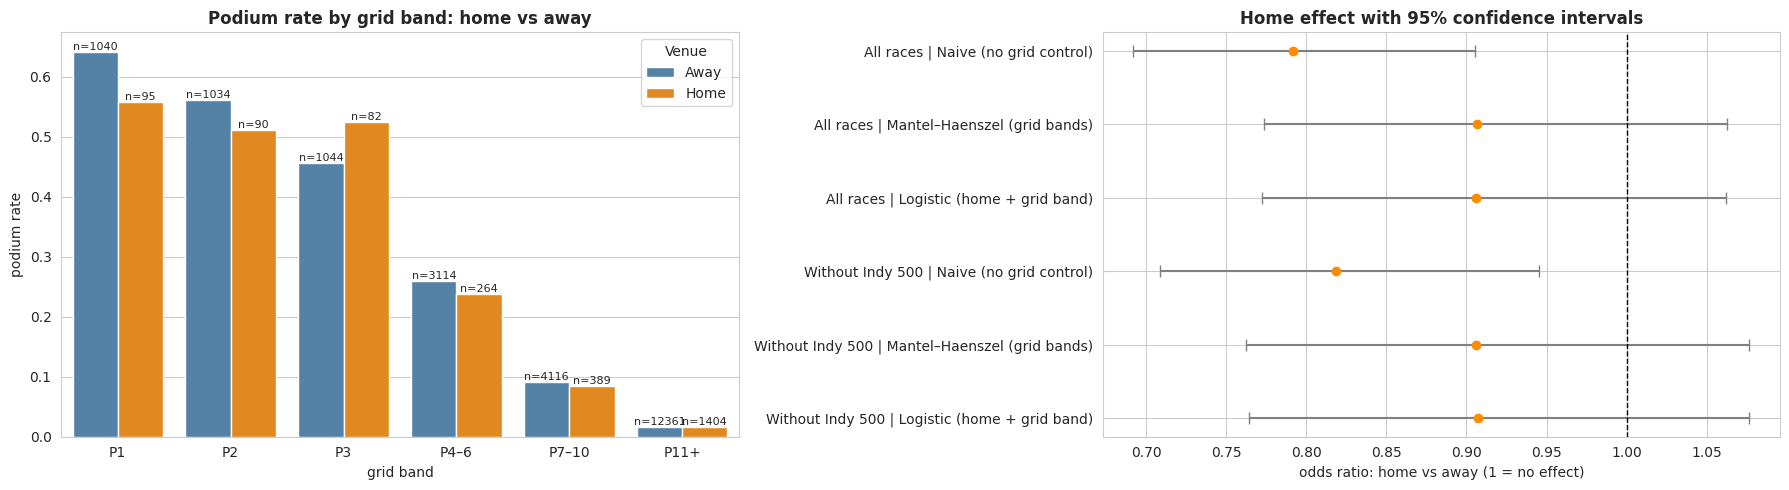

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Left: podium rate by grid band, home vs away, with counts
plot_df = (q2m.groupby(['grid_band', 'is_home'], observed=True)['is_podium']
           .agg(['mean', 'size']).reset_index())
plot_df['Venue'] = plot_df['is_home'].map({1: 'Home', 0: 'Away'})
sns.barplot(data=plot_df, x='grid_band', y='mean', hue='Venue',
            palette={'Home': 'darkorange', 'Away': 'steelblue'}, ax=axes[0])
for cont, (_, sub) in zip(axes[0].containers, plot_df.groupby('Venue', sort=False)):
    axes[0].bar_label(cont, labels=[f"n={n}" for n in sub['size']], fontsize=8)
axes[0].set_title('Podium rate by grid band: home vs away', fontweight='bold')
axes[0].set_xlabel('grid band'); axes[0].set_ylabel('podium rate')

# Right: odds ratios with 95% CI
r = q2_results.iloc[::-1].reset_index(drop=True)
y = np.arange(len(r))
axes[1].errorbar(r['odds_ratio'], y,
                 xerr=[r['odds_ratio'] - r['ci_low'], r['ci_high'] - r['odds_ratio']],
                 fmt='o', color='darkorange', ecolor='grey', capsize=4)
axes[1].axvline(1, color='black', ls='--', lw=1)
axes[1].set_yticks(y)
axes[1].set_yticklabels(r['sample'] + ' | ' + r['method'])
axes[1].set_xlabel('odds ratio: home vs away (1 = no effect)')
axes[1].set_title('Home effect with 95% confidence intervals', fontweight='bold')

plt.tight_layout()
plt.show()

### Q2 — Answer
**No: once starting position is controlled for, there is no evidence that drivers podium more often at home.**

| Method | Odds ratio (home vs away) | 95% CI | p |
|---|---|---|---|
| Naive (no control) | 0.79 | 0.69–0.91 | 0.001 |
| Mantel–Haenszel (grid bands) | 0.91 | 0.77–1.06 | 0.22 |
| Logistic (home + grid band) | 0.91 | 0.77–1.06 | 0.22 |

- **Why control matters:** home drivers start further back on average (mean grid 13.3 vs 11.7 away), plausibly because many raced only their home Grand Prix in less competitive cars. The naive comparison therefore shows a significant home *disadvantage* (OR 0.79, p = 0.001), which disappears once home and away drivers from the same grid band are compared.
- **Grid-standardized difference:** −0.7 percentage points. Per-band differences change sign (P1 −8.4, P2 −5.0, P3 +6.7, others ≈ 0) and rest on only 82–95 home rows in the front bands, consistent with noise.
- **Two independent methods agree** (Mantel–Haenszel and logistic regression both give OR ≈ 0.91).
- **Robustness:** excluding the 1950–1960 Indianapolis 500 (381 rows, almost entirely American field) gives the same result (OR 0.91, CI 0.76–1.08).
- **Interpretation:** the confidence interval rules out a large home advantage but not a small one (true OR plausibly 0.77–1.06). Association, not cause.
- **Implication for modeling:** home status adds no measurable signal beyond grid, so it is not used as a feature.

**Grain:** one row per (raceId, driverId); starters with `grid > 0` (25,033 rows).
**Missingness:** nationality mapped explicitly with diagnostics; a spelling variant (*Argentinian* vs *Argentine*) was detected and fixed, leaving 0 unmapped rows. Home status uses the circuit's country, not the race name (e.g. San Marino GP at Imola, Italy).
**Cutoff:** nationality, circuit and grid are all known before the start.

## Q3 — Mechanical retirement rate by constructor, 2014–2021 vs 2022–2024
**Definition (from the brief):** a race start that ended early because a car component failed; crashes, driver causes and regulation decisions are excluded.
**Numerator:** every status value occurring in 2014–2024 is explicitly classified (finished / mechanical / accident_driver / regulation / other / ambiguous) instead of keyword matching; the code stops if any status is unclassified.
**Denominator:** race starts, excluding *Did not start* and 0-lap *Withdrew* rows; a lap-1 retirement with 0 laps still counts as a start.
**Ambiguous statuses** (*Retired* with no reason, *Puncture*, *Wheel nut*, *Front wing* …) are excluded in the main (strict) rate and included in an upper-bound rate, to test whether classification choices change the ranking.
**Reliability:** constructors need ≥ 30 starts in an era; rates are shown with 95% Wilson confidence intervals.

In [37]:
import re

q3 = (base[base['year'].between(2014, 2024)]
      .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}),
             on='constructorId', how='left'))

# Race start: anything except non-start statuses with 0 laps
NON_START = {'Did not start', 'Withdrew', 'Did not qualify', 'Did not prequalify'}
q3['is_start'] = ~q3['status'].isin(NON_START) | (q3['laps'] > 0)
print(f"Rows 2014–2024: {len(q3)} | race starts: {q3['is_start'].sum()} | "
      f"non-starts removed: {(~q3['is_start']).sum()}")
q3s = q3[q3['is_start']].copy()

MECHANICAL = {
    'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Electronics',
    'Brakes', 'Brake duct', 'Suspension', 'Radiator', 'Overheating', 'Cooling system',
    'Oil leak', 'Oil pressure', 'Oil line', 'Water leak', 'Water pressure', 'Water pump',
    'Fuel pressure', 'Fuel pump', 'Fuel system', 'Fuel leak', 'Fuel line',
    'Power Unit', 'Power loss', 'ERS', 'Battery', 'Turbo', 'Exhaust', 'Driveshaft',
    'Halfshaft', 'Differential', 'Drivetrain', 'Throttle', 'Steering', 'Mechanical',
    'Technical', 'Vibrations', 'Rear wing', 'Pneumatics', 'Spark plugs', 'Wheel bearing',
    'Launch control', 'Engine fire', 'Fire', 'Heat shield fire', 'Track rod', 'Axle',
    'CV joint', 'Ignition', 'Injection', 'Alternator', 'Chassis', 'Crankshaft',
    'Engine misfire', 'Gear selector',
}
ACCIDENT_DRIVER = {'Accident', 'Collision', 'Collision damage', 'Damage', 'Spun off',
                   'Debris', 'Illness', 'Injury', 'Injured', 'Driver unwell', 'Fatal accident'}
REGULATION = {'Disqualified', 'Excluded', 'Underweight', '107% Rule'}
OTHER = {'Withdrew', 'Out of fuel', 'Safety concerns', 'Not restarted'}
AMBIGUOUS = {'Retired', 'Tyre', 'Puncture', 'Wheel', 'Wheel nut', 'Wheel rim',
             'Front wing', 'Undertray', 'Not classified', 'Handling', 'Seat', 'Fuel'}

def classify_status(s):
    if s == 'Finished' or re.match(r'^\+\d+ Laps?$', str(s)):
        return 'finished'
    for cat, group in [('mechanical', MECHANICAL), ('accident_driver', ACCIDENT_DRIVER),
                       ('regulation', REGULATION), ('other', OTHER), ('ambiguous', AMBIGUOUS)]:
        if s in group:
            return cat
    return 'UNCLASSIFIED'

q3s['status_cat'] = q3s['status'].apply(classify_status)

status_table = (q3s.groupby(['status_cat', 'status']).size().rename('count').reset_index()
                .sort_values(['status_cat', 'count'], ascending=[True, False]))
pd.set_option('display.max_rows', 200)
display(status_table)

unclassified = status_table.loc[status_table['status_cat'] == 'UNCLASSIFIED', 'status'].tolist()
assert not unclassified, f"Unclassified statuses — add them to a category: {unclassified}"
print(f"All {status_table['status'].nunique()} statuses in 2014–2024 are classified.")

Rows 2014–2024: 4623 | race starts: 4615 | non-starts removed: 8


,status_cat,status,count
1,accident_driver,Collision,150
0,accident_driver,Accident,85
2,accident_driver,Collision damage,59
6,accident_driver,Spun off,11
5,accident_driver,Illness,3
3,accident_driver,Damage,2
4,accident_driver,Debris,1
9,ambiguous,Retired,50
13,ambiguous,Wheel,11
8,ambiguous,Puncture,7


All 66 statuses in 2014–2024 are classified.


In [38]:
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

q3s['era'] = np.where(q3s['year'] <= 2021, '2014–2021', '2022–2024')
q3s['mech'] = (q3s['status_cat'] == 'mechanical').astype(int)
q3s['mech_upper'] = q3s['status_cat'].isin(['mechanical', 'ambiguous']).astype(int)

# Overall rate per era + test of difference
era_tot = q3s.groupby('era').agg(starts=('mech', 'size'), mech_dnf=('mech', 'sum'),
                                 mech_upper=('mech_upper', 'sum'))
era_tot['rate_strict'] = era_tot['mech_dnf'] / era_tot['starts']
era_tot['rate_upper'] = era_tot['mech_upper'] / era_tot['starts']
display(era_tot.round(3))
z, p = proportions_ztest(era_tot['mech_dnf'].values, era_tot['starts'].values)
print(f"Two-proportion z-test (strict rate, era difference): z = {z:.2f}, p = {p:.4f}")

# Per constructor, per era
MIN_STARTS = 30
cons = (q3s.groupby(['era', 'constructor'])
        .agg(starts=('mech', 'size'), mech_dnf=('mech', 'sum'), mech_upper=('mech_upper', 'sum'))
        .reset_index())
cons = cons[cons['starts'] >= MIN_STARTS].copy()
cons['rate'] = cons['mech_dnf'] / cons['starts']
cons['rate_upper'] = cons['mech_upper'] / cons['starts']
lo, hi = proportion_confint(cons['mech_dnf'], cons['starts'], method='wilson')
cons['ci_low'], cons['ci_high'] = lo, hi
cons['rank'] = cons.groupby('era')['rate'].rank(ascending=False, method='min').astype(int)
cons['rank_upper'] = cons.groupby('era')['rate_upper'].rank(ascending=False, method='min').astype(int)

for era, g in cons.groupby('era'):
    rho, _ = spearmanr(g['rate'], g['rate_upper'])
    print(f"\n{era}: {len(g)} constructors | strict vs upper-bound ranking Spearman rho = {rho:.2f}")
    display(g.sort_values('rate', ascending=False)
             [['constructor', 'starts', 'mech_dnf', 'rate', 'ci_low', 'ci_high',
               'rank', 'rate_upper', 'rank_upper']].round(3))

,starts,mech_dnf,mech_upper,rate_strict,rate_upper
era,,,,,
2014–2021,3260,302,368,0.093,0.113
2022–2024,1355,78,95,0.058,0.070


Two-proportion z-test (strict rate, era difference): z = 3.95, p = 0.0001

2014–2021: 19 constructors | strict vs upper-bound ranking Spearman rho = 0.97


,constructor,starts,mech_dnf,rate,ci_low,ci_high,rank,rate_upper,rank_upper
4,Caterham,34,8,0.235,0.124,0.400,1,0.324,1
8,Lotus F1,75,14,0.187,0.115,0.289,2,0.240,2
17,Toro Rosso,242,39,0.161,0.120,0.213,3,0.182,3
11,McLaren,319,44,0.138,0.104,0.180,4,0.160,4
15,Renault,200,27,0.135,0.094,0.189,5,0.155,5
16,Sauber,200,22,0.110,0.074,0.161,6,0.135,6
14,Red Bull,319,34,0.107,0.077,0.145,7,0.119,8
1,AlphaTauri,78,8,0.103,0.053,0.190,8,0.115,9
10,Marussia,31,3,0.097,0.033,0.249,9,0.097,11
13,Racing Point,76,7,0.092,0.045,0.178,10,0.105,10



2022–2024: 12 constructors | strict vs upper-bound ranking Spearman rho = 0.69


,constructor,starts,mech_dnf,rate,ci_low,ci_high,rank,rate_upper,rank_upper
19,Alfa Romeo,88,11,0.125,0.071,0.210,1,0.125,1
21,Alpine F1 Team,136,15,0.110,0.068,0.174,2,0.110,2
20,AlphaTauri,88,6,0.068,0.032,0.141,3,0.080,6
23,Ferrari,136,8,0.059,0.030,0.112,4,0.081,5
30,Williams,134,7,0.052,0.026,0.104,5,0.082,4
22,Aston Martin,134,6,0.045,0.021,0.094,6,0.060,8
24,Haas F1 Team,135,6,0.044,0.021,0.094,7,0.052,9
26,Mercedes,136,6,0.044,0.020,0.093,8,0.044,10
27,RB F1 Team,48,2,0.042,0.012,0.140,9,0.104,3
25,McLaren,136,5,0.037,0.016,0.083,10,0.037,12


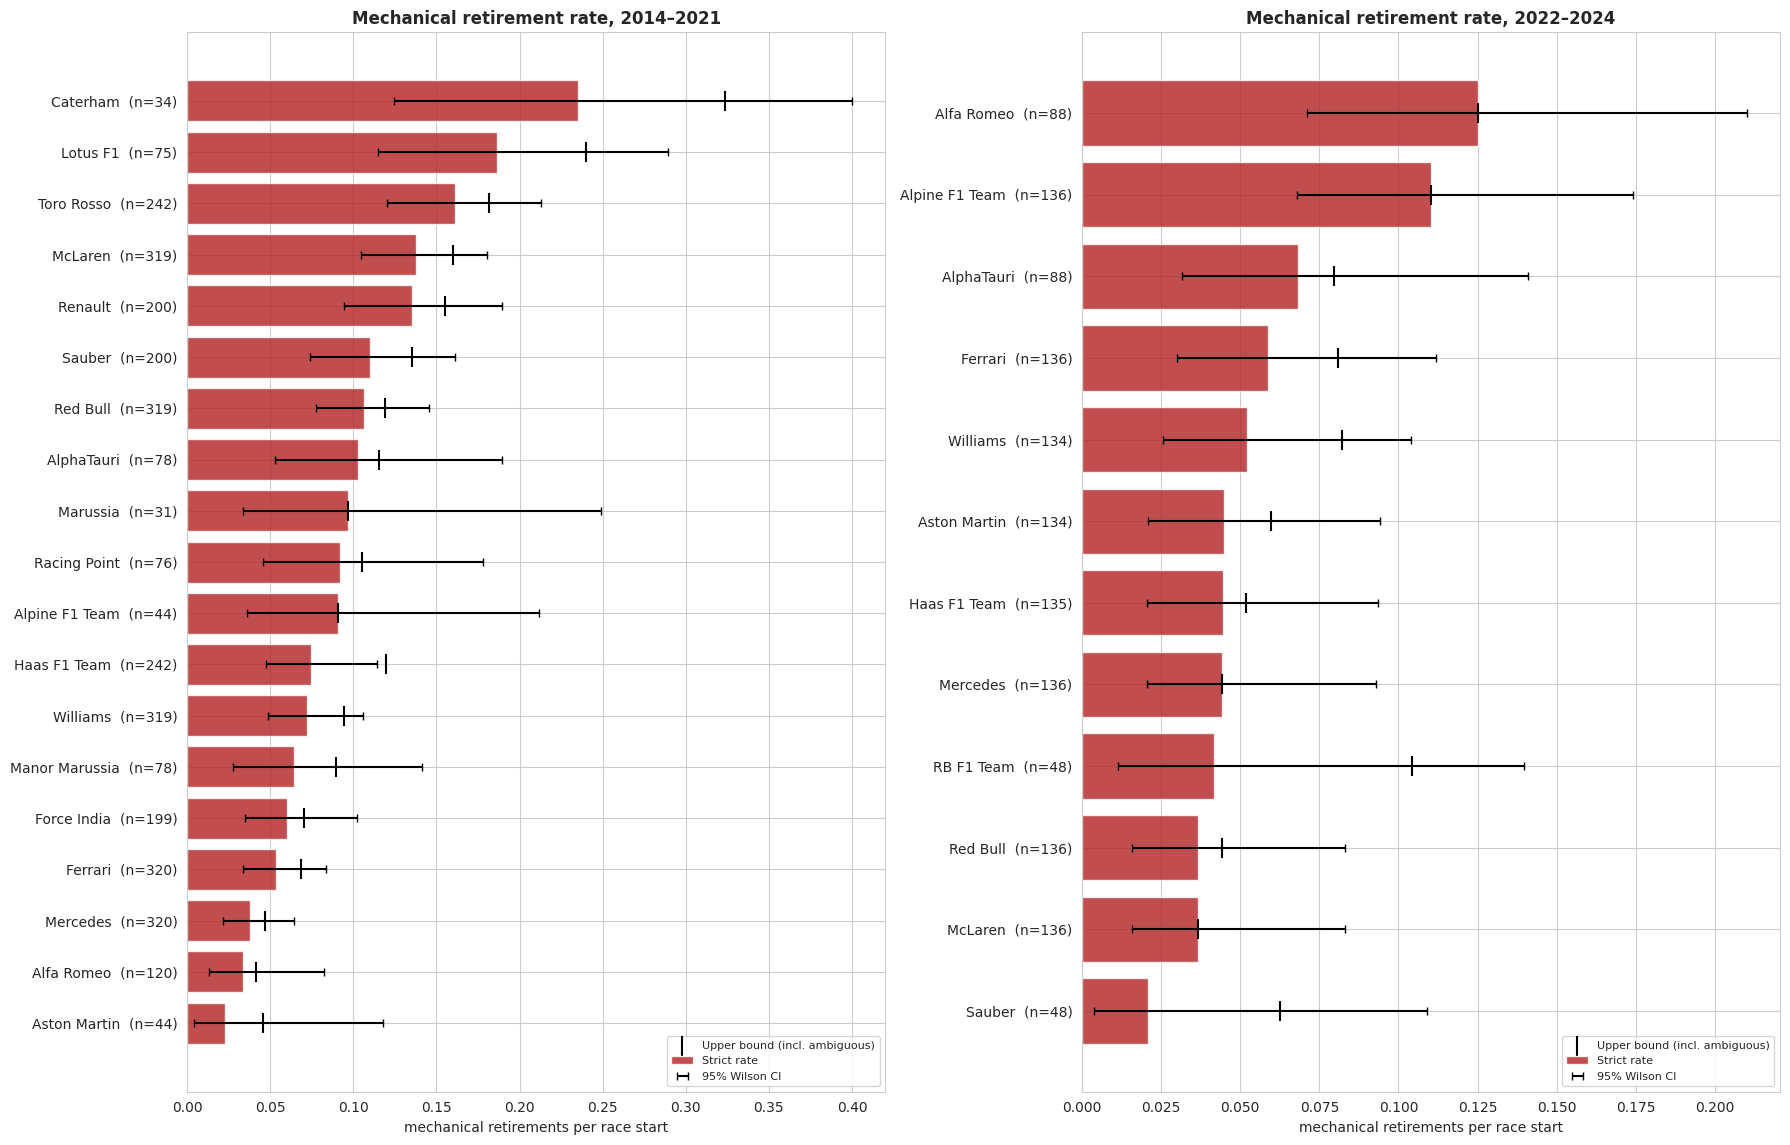

In [39]:
eras = ['2014–2021', '2022–2024']
heights = [len(cons[cons['era'] == e]) for e in eras]
fig, axes = plt.subplots(1, 2, figsize=(18, 0.45 * max(heights) + 3))

for ax, era in zip(axes, eras):
    g = cons[cons['era'] == era].sort_values('rate')
    y = np.arange(len(g))
    ax.barh(y, g['rate'], color='firebrick', alpha=0.8, label='Strict rate')
    ax.errorbar(g['rate'], y, xerr=[g['rate'] - g['ci_low'], g['ci_high'] - g['rate']],
                fmt='none', ecolor='black', capsize=3, label='95% Wilson CI')
    ax.scatter(g['rate_upper'], y, color='black', marker='|', s=200, zorder=3,
               label='Upper bound (incl. ambiguous)')
    ax.set_yticks(y)
    ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(g['constructor'], g['starts'])])
    ax.set_xlabel('mechanical retirements per race start')
    ax.set_title(f'Mechanical retirement rate, {era}', fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

### Q3 — Answer
**Overall:** mechanical retirements per race start fell from **9.3%** (2014–2021, 302 / 3,260) to **5.8%** (2022–2024, 78 / 1,355); two-proportion z-test z = 3.95, **p = 0.0001**. The drop holds with ambiguous statuses included (11.3% → 7.0%).

**2014–2021 — highest rates** (strict, ≥ 30 starts): Caterham 23.5% (n = 34, 95% CI 12–40%), Lotus F1 18.7% (n = 75), Toro Rosso 16.1% (n = 242), McLaren 13.8% (n = 319), Renault 13.5% (n = 200). Lowest: Mercedes 3.8% (n = 320). Among full-time teams (~320 starts), McLaren is highest and Mercedes lowest. Strict vs upper-bound ranking: Spearman ρ = 0.97, so classification choices do not change the ranking.

**2022–2024 — highest rates:** Alfa Romeo 12.5% (n = 88), Alpine 11.0% (n = 136), AlphaTauri 6.8% (n = 88). Lowest: Sauber 2.1% (n = 48), McLaren and Red Bull 3.7%. Strict vs upper bound: ρ = 0.69; the top two are unchanged, but mid-field teams with only 48 starts (RB F1 Team, Sauber) move several places, and confidence intervals overlap heavily in the mid-field.

**Change between eras:** McLaren improved most (13.8% → 3.7%, rank 4 → 10) and Red Bull 10.7% → 3.7%; Mercedes was low in both eras; Alpine remained among the highest.

**Grain:** one row per (raceId, driverId); only race starts (8 non-starts excluded: *Did not start*, 0-lap *Withdrew*). A lap-1 retirement with 0 laps counts as a start.
**Missingness / classification:** all 66 statuses occurring in 2014–2024 are explicitly classified (table above); 83 rows are ambiguous (mainly *Retired* with no reason, 50 rows), handled with strict and upper-bound rates.
**Cutoff:** descriptive analysis of outcomes, not a model feature. A constructor's *past* mechanical retirement rate (from earlier races only) could be a leakage-safe feature (Chapter 3).
**Limitations:** constructors follow dataset IDs, so rebrands are separate entries (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Renault → Alpine, Sauber ↔ Alfa Romeo); teams with few starts have wide confidence intervals.

# 3. Feature Selection & Engineering
**Leakage rule:** every feature must be known after qualifying and before the start ("Saturday-evening test"). Current-race results, status, laps, pit stops and post-race standings are never used.
**Population:** pre-race non-starters excluded (Section 1.4.4); target `target_podium = positionOrder ≤ 3`.
**Window:** features are computed on the full history, then rows are restricted to **2003–2024** (complete qualifying coverage, Section 1.3), so early-2003 rows still get form from 2002.
**Feature groups** (used for ablation): *grid*, *qualifying*, *standings*, *driver form*, *constructor form*.

## 3.1 Population, grid and qualifying features

In [40]:
races_info = clean['races'][['raceId', 'year', 'round', 'circuitId', 'date']]

model_df = (clean['results'][~clean['results']['pre_race_non_starter']]
            [['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'status', 'laps']]
            .merge(races_info, on='raceId', how='left')
            .sort_values(['date', 'raceId', 'grid'])
            .reset_index(drop=True))

model_df['target_podium'] = (model_df['positionOrder'] <= 3).astype(int)

# --- GRID group ---
model_df['field_size'] = model_df.groupby('raceId')['driverId'].transform('size')
model_df['pit_lane_start'] = (model_df['grid'] == 0).astype(int)
# Pit-lane start = behind the whole grid, so it gets the last position, not 0
model_df['grid_pos'] = model_df['grid'].where(model_df['grid'] > 0, model_df['field_size'])

assert not model_df.duplicated(['raceId', 'driverId']).any()
print(f"Population (all seasons): {len(model_df)} rows")
print(f"Pit-lane starts: {model_df['pit_lane_start'].sum()} | "
      f"grid_pos range: {model_df['grid_pos'].min()}–{model_df['grid_pos'].max()}")

Population (all seasons): 25163 rows
Pit-lane starts: 130 | grid_pos range: 1–34


In [41]:
q = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec', 'q2_sec', 'q3_sec']].copy()
q = q.rename(columns={'position': 'quali_pos'})

# Driver's best lap across Q1/Q2/Q3, and the fastest lap of that session (pole)
q['best_q_sec'] = q[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
q['pole_sec'] = q.groupby('raceId')['best_q_sec'].transform('min')
q['gap_to_pole_pct'] = 100 * (q['best_q_sec'] - q['pole_sec']) / q['pole_sec']

model_df = model_df.merge(q[['raceId', 'driverId', 'quali_pos', 'gap_to_pole_pct']],
                          on=['raceId', 'driverId'], how='left')

# --- QUALIFYING group ---
# Positive = started behind the qualifying position (penalty)
model_df['grid_penalty'] = model_df['grid_pos'] - model_df['quali_pos']

assert not model_df.duplicated(['raceId', 'driverId']).any()

w = model_df[model_df['year'].between(2003, 2024)]
print(f"2003–2024 rows: {len(w)}")
print(f"Missing quali_pos: {w['quali_pos'].isna().sum()} | "
      f"missing gap_to_pole_pct: {w['gap_to_pole_pct'].isna().sum()}")
display(w['gap_to_pole_pct'].describe(percentiles=[.5, .9, .95, .99]).round(3).to_frame())
print(f"Gaps > 7% (beyond the 107% rule): {(w['gap_to_pole_pct'] > 7).sum()}")
display(w.nlargest(8, 'gap_to_pole_pct')[['year', 'raceId', 'driverId', 'quali_pos',
                                          'grid_pos', 'gap_to_pole_pct', 'target_podium']])

2003–2024 rows: 8961
Missing quali_pos: 23 | missing gap_to_pole_pct: 147


,gap_to_pole_pct
count,8814.000
mean,2.277
std,2.583
min,0.000
50%,1.723
90%,4.554
95%,6.172
99%,13.577
max,45.596


Gaps > 7% (beyond the 107% rule): 290


,year,raceId,driverId,quali_pos,grid_pos,gap_to_pole_pct,target_podium
24284,2023,1099,858,20.0,20,45.595649,0
21564,2016,958,837,22.0,21,37.796536,0
21563,2016,958,836,21.0,20,34.237479,0
21565,2016,958,828,20.0,22,33.788532,0
16900,2005,71,30,18.0,19,33.588962,0
16600,2004,93,47,18.0,19,33.285268,0
23287,2020,1044,849,20.0,20,31.407229,0
19044,2010,349,810,23.0,22,31.174724,0


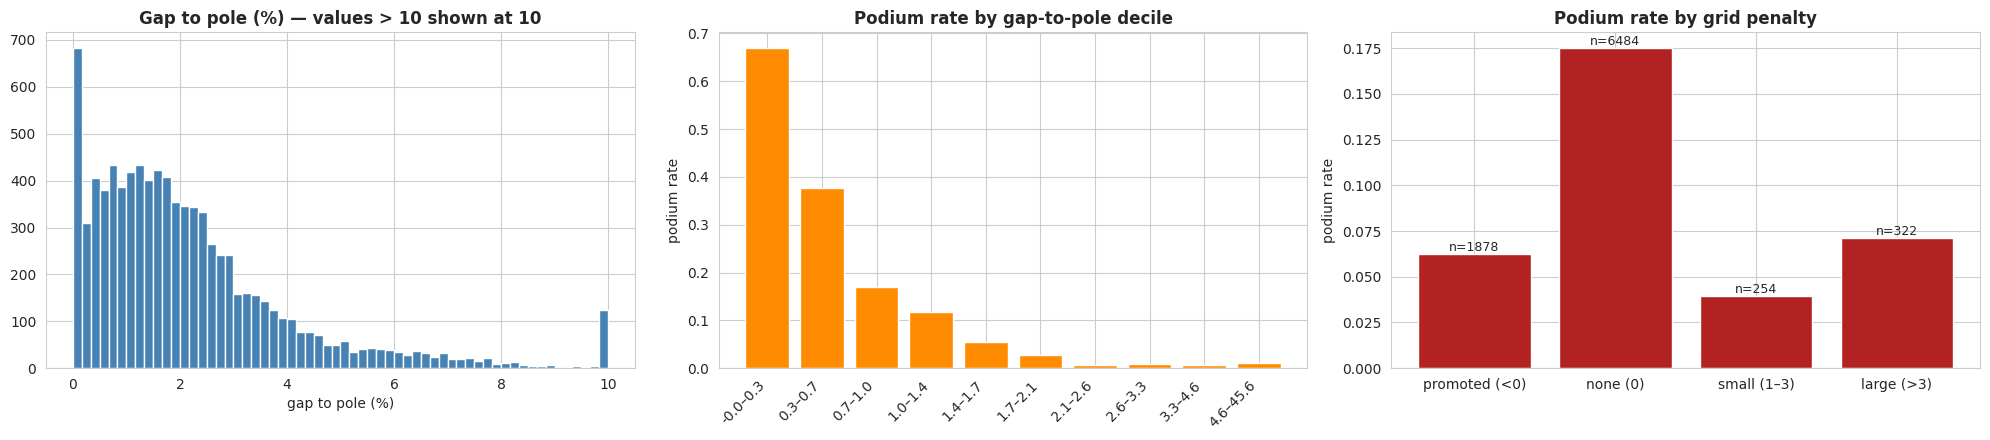

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

# 1) gap_to_pole distribution (capped view so the bulk is visible)
axes[0].hist(w['gap_to_pole_pct'].clip(upper=10).dropna(), bins=60, color='steelblue')
axes[0].set_title('Gap to pole (%) — values > 10 shown at 10', fontweight='bold')
axes[0].set_xlabel('gap to pole (%)')

# 2) podium rate vs gap_to_pole (deciles)
bins = pd.qcut(w['gap_to_pole_pct'], 10, duplicates='drop')
gp = w.groupby(bins, observed=True)['target_podium'].mean()
axes[1].bar(range(len(gp)), gp.values, color='darkorange')
axes[1].set_xticks(range(len(gp)))
axes[1].set_xticklabels([f"{i.left:.1f}–{i.right:.1f}" for i in gp.index], rotation=45, ha='right')
axes[1].set_title('Podium rate by gap-to-pole decile', fontweight='bold')
axes[1].set_ylabel('podium rate')

# 3) podium rate vs grid penalty
pen = pd.cut(w['grid_penalty'], bins=[-np.inf, -1, 0, 3, np.inf],
             labels=['promoted (<0)', 'none (0)', 'small (1–3)', 'large (>3)'])
pp = w.groupby(pen, observed=True)['target_podium'].agg(['mean', 'size'])
axes[2].bar(pp.index.astype(str), pp['mean'], color='firebrick')
for i, n in enumerate(pp['size']):
    axes[2].text(i, pp['mean'].iloc[i], f"n={n}", ha='center', va='bottom', fontsize=9)
axes[2].set_title('Podium rate by grid penalty', fontweight='bold')
axes[2].set_ylabel('podium rate')

plt.tight_layout()
plt.show()

In [43]:
GAP_CAP = 7.0   # F1 107% rule: domain constant, not learned from data -> no split leakage
before_max = model_df['gap_to_pole_pct'].max()
n_capped = (model_df['gap_to_pole_pct'] > GAP_CAP).sum()
model_df['gap_to_pole_pct'] = model_df['gap_to_pole_pct'].clip(upper=GAP_CAP)

w = model_df[model_df['year'].between(2003, 2024)]
print(f"Capped {n_capped} values (all seasons); max {before_max:.1f}% → {model_df['gap_to_pole_pct'].max():.1f}%")
print(f"Podium rate among 2003–2024 rows that were > {GAP_CAP}%: "
      f"{w.loc[w['gap_to_pole_pct'] >= GAP_CAP, 'target_podium'].mean():.2%}")

Capped 384 values (all seasons); max 922.9% → 7.0%
Podium rate among 2003–2024 rows that were > 7.0%: 2.41%


### 3.1 Findings
- **Grid group:** `grid_pos` (pit-lane starts set to the last position, `field_size`, since they start behind the grid; leaving them at 0 would read as better than pole), `pit_lane_start` flag (130 rows), `field_size`.
- **Qualifying group:** `quali_pos`, `gap_to_pole_pct` (relative to the session's fastest lap, so comparable across circuits of different lengths), `grid_penalty` = grid_pos − quali_pos (penalties, and in 2021–22 also sprint results).
- **Evidence:** podium rate falls monotonically with gap to pole: 67% in the fastest decile (0–0.3%), 38% (0.3–0.7%), 17% (0.7–1.0%), ≈ 0% beyond 2.1%.
- **Outliers:** 290 rows (2003–2024) exceed 7% (max 45.6%), from non-representative laps (rain, red flags); several drivers in the same session show 34–38%. Capped at **7%** (107% rule; 3.3% of 2003–2024 rows exceed it, i.e. ≈ 97th percentile). A fixed domain constant is not learned from data, so it is applied before the split without leakage. Rows are kept (the drivers did start); order is preserved. Capped rows still podium 2.4% of the time (vs ≈15% overall), showing that some extreme gaps come from non-representative laps of fast cars; this is further reason not to let the raw value dominate.
- **Grid penalty:** the univariate plot is confounded (most "promoted" drivers are back-markers moving up one or two places). Kept based on the Q1 front-row evidence (29% vs 64%); its contribution is measured by ablation (Chapter 5).
- **Missing:** `quali_pos` 23 rows (0.26%), `gap_to_pole_pct` 147 rows (1.6%, position but no lap time). Imputed inside the preprocessing pipeline, fitted on training data only (Chapter 4).

## 3.2 Standings before the race
`driver_standings` / `constructor_standings` for race *r* are the standings **after** race *r* (leakage). Each row instead gets the standings after the **previous race in time**: mid-season the previous round, at round 1 the previous season's final standings (both known before the start).
Points systems changed (e.g. 10 → 25 points for a win in 2010), so raw points are not comparable across eras. Features: championship **rank** and **points share** (points ÷ leader's points). Drivers/constructors with no previous standing (rookies, rebrands) get rank = worst + 1, share = 0, and an `unranked` flag.

In [44]:
# Previous race in time (round 1 -> previous season's final race)
race_order = clean['races'][['raceId', 'date']].sort_values(['date', 'raceId']).reset_index(drop=True)
race_order['prev_raceId'] = race_order['raceId'].shift(1).astype('Int64')
model_df = model_df.merge(race_order[['raceId', 'prev_raceId']], on='raceId', how='left')

def prepare_standings(df, key, prefix):
    s = df[['raceId', key, 'points', 'position']].copy()
    leader = s.groupby('raceId')['points'].transform('max')
    s[f'{prefix}_points_share_before'] = np.where(leader > 0, s['points'] / leader, 0.0)
    s = s.rename(columns={'raceId': 'prev_raceId', 'position': f'{prefix}_rank_before'})
    worst = s.groupby('prev_raceId')[f'{prefix}_rank_before'].max() + 1
    return s[['prev_raceId', key, f'{prefix}_rank_before', f'{prefix}_points_share_before']], worst

for table, key, prefix in [('driver_standings', 'driverId', 'drv'),
                           ('constructor_standings', 'constructorId', 'cons')]:
    s, worst = prepare_standings(clean[table], key, prefix)
    model_df = model_df.merge(s, on=['prev_raceId', key], how='left')
    model_df[f'{prefix}_unranked_before'] = model_df[f'{prefix}_rank_before'].isna().astype(int)
    model_df[f'{prefix}_rank_before'] = model_df[f'{prefix}_rank_before'].fillna(
        model_df['prev_raceId'].map(worst))
    model_df[f'{prefix}_points_share_before'] = model_df[f'{prefix}_points_share_before'].fillna(0.0)

assert not model_df.duplicated(['raceId', 'driverId']).any()
w = model_df[model_df['year'].between(2003, 2024)]
print("2003–2024 unranked share — drivers: "
      f"{w['drv_unranked_before'].mean():.2%} | constructors: {w['cons_unranked_before'].mean():.2%}")
display(w[['drv_rank_before', 'drv_points_share_before',
           'cons_rank_before', 'cons_points_share_before']].describe().round(3))

2003–2024 unranked share — drivers: 2.51% | constructors: 0.94%


,drv_rank_before,drv_points_share_before,cons_rank_before,cons_points_share_before
count,8961.000,8961.000,8961.000,8961.000
mean,11.347,0.250,5.784,0.301
std,6.520,0.300,3.078,0.337
min,1.000,0.000,1.000,0.000
25%,6.000,0.009,3.000,0.031
50%,11.000,0.115,6.000,0.150
75%,17.000,0.407,8.000,0.520
max,29.000,1.000,13.000,1.000


Leakage test: 100.00% of 6652 rows satisfy before + race points = after


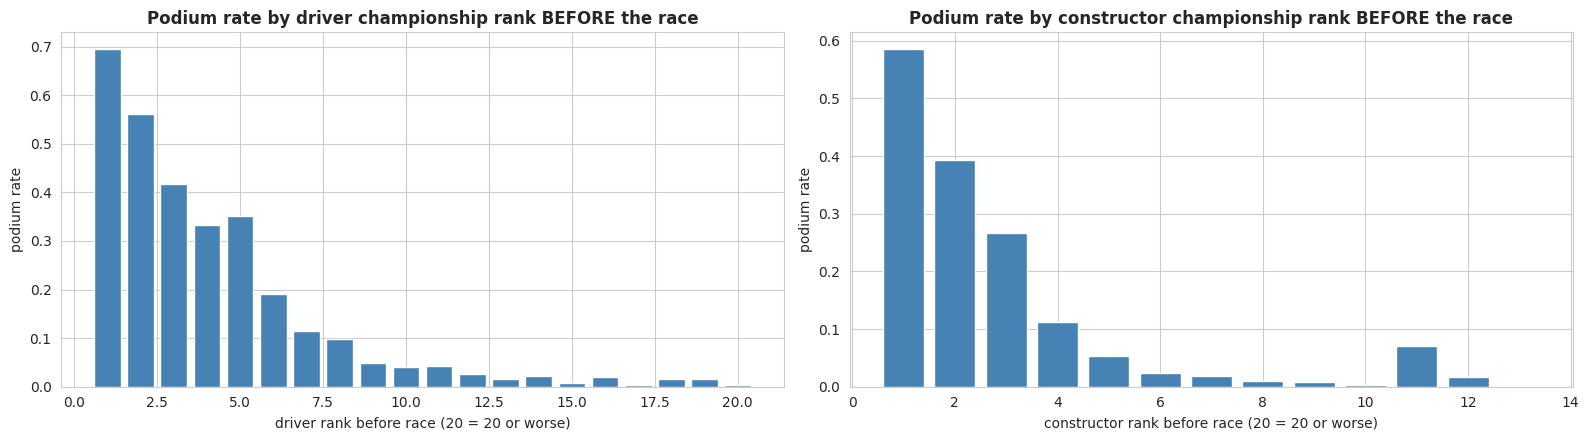

In [45]:
# LEAKAGE TEST: the standings we attached to race r must be the ones BEFORE race r.
# If so: points_after(r) - points_before(r) = points scored in race r.
# (2003–2020 only: from 2021 sprint races also add points.)
chk = model_df[model_df['year'].between(2003, 2020)][['raceId', 'driverId', 'prev_raceId']]
after = clean['driver_standings'][['raceId', 'driverId', 'points']].rename(columns={'points': 'pts_after'})
before = (clean['driver_standings'][['raceId', 'driverId', 'points']]
          .rename(columns={'raceId': 'prev_raceId', 'points': 'pts_before'}))
in_race = clean['results'][['raceId', 'driverId', 'points']].rename(columns={'points': 'pts_race'})
chk = (chk.merge(after, on=['raceId', 'driverId'])
          .merge(before, on=['prev_raceId', 'driverId'])
          .merge(in_race, on=['raceId', 'driverId']))
same_season = chk['raceId'].map(clean['races'].set_index('raceId')['year']) == \
              chk['prev_raceId'].astype(int).map(clean['races'].set_index('raceId')['year'])
chk = chk[same_season]
ok = np.isclose(chk['pts_after'] - chk['pts_before'], chk['pts_race'])
print(f"Leakage test: {ok.mean():.2%} of {len(chk)} rows satisfy before + race points = after")

# Evidence: podium rate by pre-race championship rank
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, col, title in [(axes[0], 'drv_rank_before', 'Driver'), (axes[1], 'cons_rank_before', 'Constructor')]:
    r = w.groupby(w[col].clip(upper=20))['target_podium'].mean()
    ax.bar(r.index, r.values, color='steelblue')
    ax.set_title(f'Podium rate by {title.lower()} championship rank BEFORE the race', fontweight='bold')
    ax.set_xlabel(f'{title.lower()} rank before race (20 = 20 or worse)')
    ax.set_ylabel('podium rate')
plt.tight_layout()
plt.show()

### 3.2 Findings
- **Leakage test passed:** for 100% of 6,652 driver-race rows (2003–2020, same season), points before + points scored in the race = points after, proving the standings come from before the race.
- **Evidence:** podium rate by pre-race driver rank: 69% (1st), 56% (2nd), 42% (3rd), ≈ 0% beyond 10th; by constructor rank: 58%, 39%, 27%, 11% (1st–4th).
- **Unranked:** 2.5% of driver rows and 0.9% of constructor rows (rookies, rebrands). The spike at constructor rank 11 likely reflects rebranded constructors with a competitive car (e.g. Brawn GP 2009) that have no standing under their new ID; the `cons_unranked_before` flag lets the model separate them. Rebrands losing history is a known limitation.

## 3.3 Form features (past races only)
All form features use only races **strictly before** the current one (`shift(1)` before every rolling or expanding window).
- **Driver form:** podium rate and average finishing order over the last 5 starts, career podium rate, career starts (experience).
- **Constructor form:** podium rate over the team's last 5 races, mechanical-retirement rate over its last 10 races (Q3 status classification).

**Teammate leakage trap:** a constructor has two rows per race. Shifting row by row would let one driver's feature include his teammate's result **from the same race**. Constructor results are therefore aggregated to one row per race first, then shifted by race, then merged back.
A brute-force leakage test recomputes the features for random rows from strictly earlier races only.

In [46]:
model_df = model_df.sort_values(['date', 'raceId']).reset_index(drop=True)
g = model_df.groupby('driverId')

# --- DRIVER FORM group (shift(1) = exclude the current race) ---
model_df['drv_career_starts'] = g.cumcount()                       # starts BEFORE this one
model_df['drv_podium_rate_last5'] = g['target_podium'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
model_df['drv_avg_finish_last5'] = g['positionOrder'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
model_df['drv_career_podium_rate'] = g['target_podium'].transform(
    lambda s: s.shift(1).expanding().mean())

w = model_df[model_df['year'].between(2003, 2024)]
print("Missing (2003–2024), = debut races with no history:")
print(w[['drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_career_podium_rate']].isna().sum())
print(f"Debut rows (career_starts = 0): {(w['drv_career_starts'] == 0).sum()}")

Missing (2003–2024), = debut races with no history:
drv_podium_rate_last5     89
drv_avg_finish_last5      89
drv_career_podium_rate    89
dtype: int64
Debut rows (career_starts = 0): 89


In [47]:
# Mechanical DNF of the CURRENT race (an outcome!): used only inside shifted windows,
# never as a feature itself.
model_df['_mech_dnf_outcome'] = (model_df['status'].apply(classify_status) == 'mechanical').astype(int)

# Statuses outside 2014–2024 not covered by the Q3 classification (counted as non-mechanical)
st = model_df.loc[model_df['year'] >= 2002, 'status']
uncl = st[st.apply(classify_status) == 'UNCLASSIFIED'].value_counts()
print(f"Unclassified statuses 2002–2024: {len(uncl)} ({uncl.sum()} rows)")
display(uncl.to_frame('rows'))

# 1) Collapse to ONE ROW PER CONSTRUCTOR PER RACE (avoids teammate leakage)
cr = (model_df.groupby(['constructorId', 'raceId', 'date'], as_index=False)
      .agg(c_podiums=('target_podium', 'sum'), c_entries=('target_podium', 'size'),
           c_mech=('_mech_dnf_outcome', 'sum'))
      .sort_values(['date', 'raceId']).reset_index(drop=True))
gc = cr.groupby('constructorId')

def past_rate(num, den, window):
    n = gc[num].transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())
    d = gc[den].transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())
    return n / d

# 2) Shift + roll BY RACE
cr['cons_podium_rate_last5'] = past_rate('c_podiums', 'c_entries', 5)
cr['cons_mech_dnf_rate_last10'] = past_rate('c_mech', 'c_entries', 10)

# 3) Attach back to both drivers of the team
model_df = model_df.merge(cr[['constructorId', 'raceId', 'cons_podium_rate_last5',
                              'cons_mech_dnf_rate_last10']],
                          on=['constructorId', 'raceId'], how='left')
assert not model_df.duplicated(['raceId', 'driverId']).any()

w = model_df[model_df['year'].between(2003, 2024)]
print("\nMissing (2003–2024), = a constructor's first race:")
print(w[['cons_podium_rate_last5', 'cons_mech_dnf_rate_last10']].isna().sum())

Unclassified statuses 2002–2024: 6 (8 rows)


,rows
status,
Broken wing,2
Safety,2
Fuel rig,1
Tyre puncture,1
Refuelling,1
Driver Seat,1



Missing (2003–2024), = a constructor's first race:
cons_podium_rate_last5       42
cons_mech_dnf_rate_last10    42
dtype: int64


Leakage test on 300 random rows — driver form mismatches: 0 | constructor form mismatches: 0


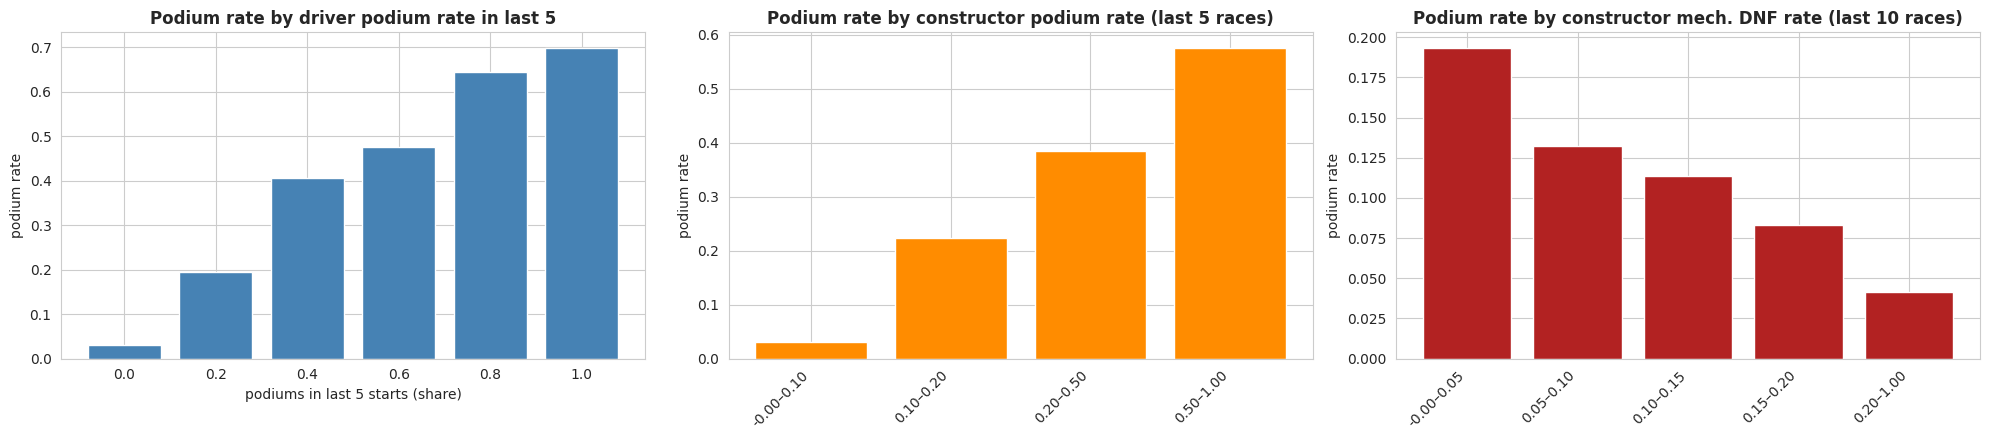

In [48]:
# LEAKAGE TEST: recompute features for random rows using ONLY strictly earlier races
sample = model_df[model_df['year'].between(2003, 2024)].sample(300, random_state=SEED)
bad_drv, bad_cons = 0, 0
for _, row in sample.iterrows():
    past = model_df[(model_df['driverId'] == row['driverId']) &
                    (model_df['date'] < row['date'])].sort_values('date').tail(5)
    exp_drv = past['target_podium'].mean() if len(past) else np.nan
    bad_drv += not np.isclose(exp_drv, row['drv_podium_rate_last5'], equal_nan=True)

    cpast = cr[(cr['constructorId'] == row['constructorId']) & (cr['date'] < row['date'])].tail(5)
    exp_cons = cpast['c_podiums'].sum() / cpast['c_entries'].sum() if len(cpast) else np.nan
    bad_cons += not np.isclose(exp_cons, row['cons_podium_rate_last5'], equal_nan=True)

print(f"Leakage test on 300 random rows — driver form mismatches: {bad_drv} | "
      f"constructor form mismatches: {bad_cons}")

# Evidence plots
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
r = w.groupby('drv_podium_rate_last5')['target_podium'].agg(['mean', 'size'])
r = r[r['size'] >= 30]
axes[0].bar(r.index.round(2).astype(str), r['mean'], color='steelblue')
axes[0].set_title('Podium rate by driver podium rate in last 5', fontweight='bold')
axes[0].set_xlabel('podiums in last 5 starts (share)')

for ax, col, title, color in [(axes[1], 'cons_podium_rate_last5', 'constructor podium rate (last 5 races)', 'darkorange'),
                              (axes[2], 'cons_mech_dnf_rate_last10', 'constructor mech. DNF rate (last 10 races)', 'firebrick')]:
    b = pd.qcut(w[col], 8, duplicates='drop')
    r = w.groupby(b, observed=True)['target_podium'].mean()
    ax.bar(range(len(r)), r.values, color=color)
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([f"{i.left:.2f}–{i.right:.2f}" for i in r.index], rotation=45, ha='right')
    ax.set_title(f'Podium rate by {title}', fontweight='bold')
for ax in axes:
    ax.set_ylabel('podium rate')
plt.tight_layout()
plt.show()

### 3.3 Findings
- **Leakage test passed:** for 300 random rows, form features recomputed from strictly earlier races only match the fast `shift`/`rolling` version exactly (0 driver mismatches, 0 constructor mismatches).
- **Missing values are only "no history":** 89 driver-form NaNs = exactly the 89 debut rows (`drv_career_starts = 0`); 42 constructor-form NaNs = a constructor's first race (new teams, rebrands). Imputed in the pipeline (Chapter 4).
- **Evidence:** podium rate rises steadily with driver podium rate in the last 5 starts (3% at 0 → 70% at 1.0) and with constructor podium rate over the last 5 races (3% → 57%); it falls with constructor mechanical-DNF rate over the last 10 races (19% for the most reliable → 4% for the least reliable), confirming the Q3 finding as a pre-race signal.
- **Status classification outside 2014–2024:** 6 statuses (8 rows, 2002–2024) were not in the Q3 lists (*Broken wing, Safety, Fuel rig, Tyre puncture, Refuelling, Driver Seat*). None is a clear component failure (crash damage, debris, pit equipment), so counting them as non-mechanical is consistent with Q3; the impact is negligible.

## 3.4 Train / validation / test split (by time)
Rows are split **by season**, never randomly, so the model always learns from the past and is evaluated on the future (as in real use), and a race is never split across sets.
- **Train:** 2003–2018 · **Validation:** 2019–2021 (model comparison and tuning) · **Test:** 2022–2024 (used once, for the final evaluation).
- The test period starts with the 2022 regulation change, so it includes a real distribution shift: an honest, demanding test.
- Feature groups are fixed here and reused for the ablation study (Chapter 5).

In [49]:
FEATURE_GROUPS = {
    'grid':             ['grid_pos', 'pit_lane_start', 'field_size'],
    'qualifying':       ['quali_pos', 'gap_to_pole_pct', 'grid_penalty'],
    'standings':        ['drv_rank_before', 'drv_points_share_before', 'drv_unranked_before',
                         'cons_rank_before', 'cons_points_share_before', 'cons_unranked_before'],
    'driver_form':      ['drv_podium_rate_last5', 'drv_avg_finish_last5',
                         'drv_career_podium_rate', 'drv_career_starts'],
    'constructor_form': ['cons_podium_rate_last5', 'cons_mech_dnf_rate_last10'],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
TARGET = 'target_podium'

# Safety check: no current-race outcome may ever be a feature
FORBIDDEN = {'positionOrder', 'status', 'laps', '_mech_dnf_outcome', TARGET}
assert not set(FEATURES) & FORBIDDEN, "Outcome column used as a feature!"

data = model_df[model_df['year'].between(2003, 2024)].copy()
data['split'] = np.select([data['year'] <= 2018, data['year'] <= 2021],
                          ['train', 'val'], default='test')

# A race must belong to exactly one split
assert data.groupby('raceId')['split'].nunique().max() == 1

split_summary = (data.groupby('split', sort=False)
                 .agg(seasons=('year', lambda s: f"{s.min()}–{s.max()}"),
                      races=('raceId', 'nunique'), rows=(TARGET, 'size'),
                      podium_rate=(TARGET, 'mean'))
                 .reindex(['train', 'val', 'test']))
display(split_summary.round(3))

missing_by_split = data.groupby('split')[FEATURES].apply(lambda d: d.isna().sum()).T
display(missing_by_split[missing_by_split.sum(axis=1) > 0][['train', 'val', 'test']])

X_train, y_train = data.loc[data['split'] == 'train', FEATURES], data.loc[data['split'] == 'train', TARGET]
X_val,   y_val   = data.loc[data['split'] == 'val',   FEATURES], data.loc[data['split'] == 'val',   TARGET]
X_test,  y_test  = data.loc[data['split'] == 'test',  FEATURES], data.loc[data['split'] == 'test',  TARGET]
print(f"{len(FEATURES)} features in {len(FEATURE_GROUPS)} groups | "
      f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")

,seasons,races,rows,podium_rate
split,,,,
train,2003–2018,300,6404,0.141
val,2019–2021,60,1200,0.150
test,2022–2024,68,1357,0.150


split,train,val,test
quali_pos,20,3,0
gap_to_pole_pct,114,20,13
grid_penalty,20,3,0
drv_podium_rate_last5,72,9,8
drv_avg_finish_last5,72,9,8
drv_career_podium_rate,72,9,8
cons_podium_rate_last5,34,6,2
cons_mech_dnf_rate_last10,34,6,2


18 features in 5 groups | train (6404, 18) | val (1200, 18) | test (1357, 18)


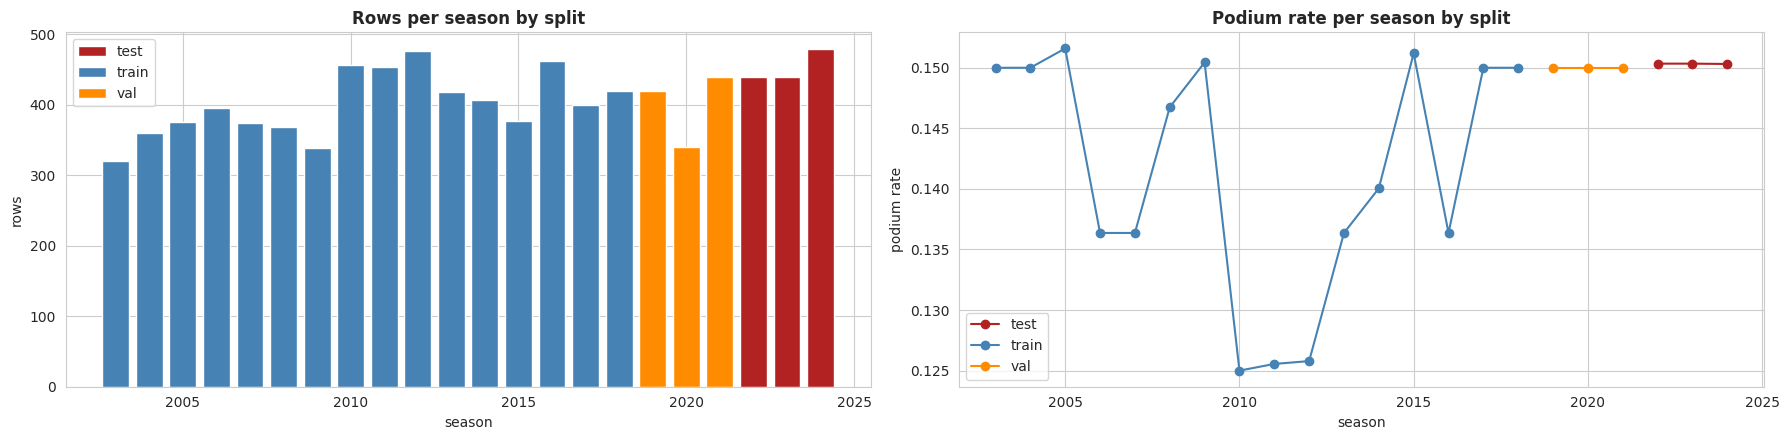

In [50]:
per_season = data.groupby(['year', 'split'], sort=False).agg(rows=(TARGET, 'size'),
                                                             podium_rate=(TARGET, 'mean')).reset_index()
colors = {'train': 'steelblue', 'val': 'darkorange', 'test': 'firebrick'}

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
for split, g in per_season.groupby('split'):
    axes[0].bar(g['year'], g['rows'], color=colors[split], label=split)
    axes[1].plot(g['year'], g['podium_rate'], marker='o', color=colors[split], label=split)
axes[0].set_title('Rows per season by split', fontweight='bold'); axes[0].set_ylabel('rows')
axes[1].set_title('Podium rate per season by split', fontweight='bold'); axes[1].set_ylabel('podium rate')
for ax in axes:
    ax.set_xlabel('season'); ax.legend()
plt.tight_layout()
plt.show()

### 3.4 Findings
| Split | Seasons | Races | Rows | Podium rate |
|---|---|---|---|---|
| Train | 2003–2018 | 300 | 6,404 (71%) | 14.1% |
| Validation | 2019–2021 | 60 | 1,200 (13%) | 15.0% |
| Test | 2022–2024 | 68 | 1,357 (15%) | 15.0% |

- 18 features in 5 groups; no outcome column is a feature (asserted), and no race is split across sets (asserted).
- The podium rate is ≈ 3 / number of starters (15% with 20 cars, 12.5% in 2010–2012 with 24 cars), so `field_size` carries base-rate information. The base rate is nearly identical across splits, so PR-AUC is comparable between validation and test.
- Missing values are small (≤ 1.8% per feature in train) and of the same kinds in every split (debuts, missing qualifying lap times, new constructors).

## 3.5 Feature evidence (training data only)
Evidence is computed on the **training split only**, so feature choices never use validation or test data.
- **Univariate ROC-AUC:** how well each feature alone ranks podium vs non-podium rows (0.5 = no signal, 1 = perfect); the stronger direction is reported.
- **Spearman correlation:** identifies redundant features.
A weak univariate feature can still add value in combination (e.g. `grid_penalty` together with grid); real contribution is measured by group ablation (Chapter 5).

,group,feature,univariate_auc,direction,missing_%
0,qualifying,quali_pos,0.909,lower → more podiums,0.31
1,grid,grid_pos,0.907,lower → more podiums,0.00
2,qualifying,gap_to_pole_pct,0.893,lower → more podiums,1.78
3,standings,cons_points_share_before,0.888,higher → more podiums,0.00
4,standings,drv_rank_before,0.885,lower → more podiums,0.00
5,standings,drv_points_share_before,0.882,higher → more podiums,0.00
6,constructor_form,cons_podium_rate_last5,0.872,higher → more podiums,0.53
7,standings,cons_rank_before,0.862,lower → more podiums,0.00
8,driver_form,drv_avg_finish_last5,0.861,lower → more podiums,1.12
9,driver_form,drv_podium_rate_last5,0.853,higher → more podiums,1.12


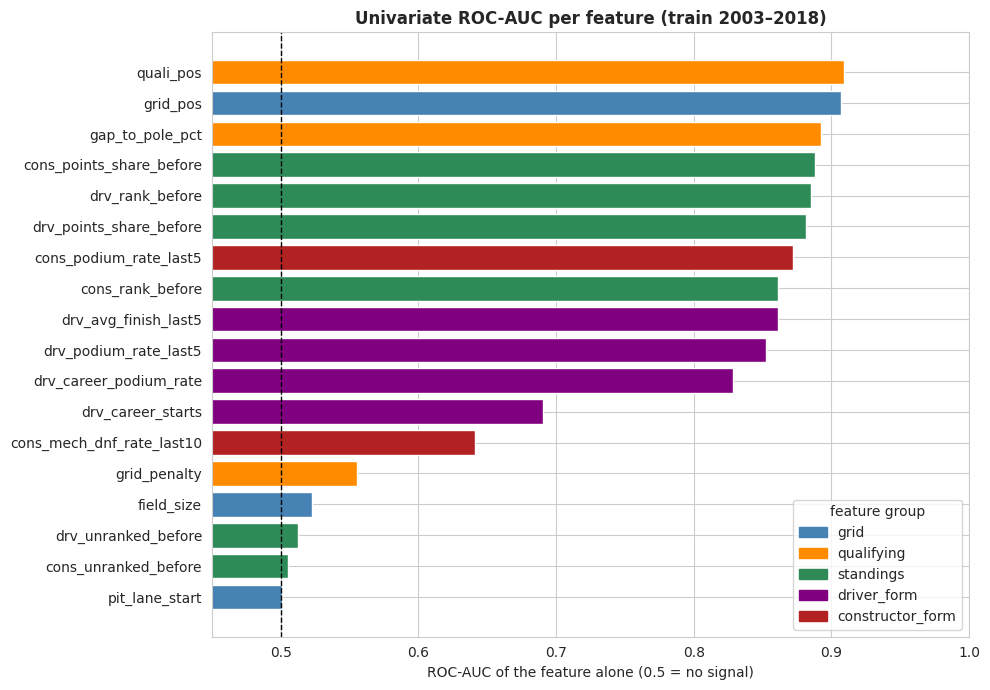

In [51]:
tr = data[data['split'] == 'train']

rows = []
for grp, feats in FEATURE_GROUPS.items():
    for f in feats:
        m = tr[f].notna()
        auc = roc_auc_score(tr.loc[m, TARGET], tr.loc[m, f])
        rows.append({'group': grp, 'feature': f,
                     'univariate_auc': max(auc, 1 - auc),
                     'direction': 'higher → more podiums' if auc >= 0.5 else 'lower → more podiums',
                     'missing_%': round(100 * (~m).mean(), 2)})
evidence = pd.DataFrame(rows).sort_values('univariate_auc', ascending=False).reset_index(drop=True)
display(evidence.round(3))

group_colors = {'grid': 'steelblue', 'qualifying': 'darkorange', 'standings': 'seagreen',
                'driver_form': 'purple', 'constructor_form': 'firebrick'}
plt.figure(figsize=(10, 7))
ev = evidence.iloc[::-1]
plt.barh(ev['feature'], ev['univariate_auc'], color=ev['group'].map(group_colors))
plt.axvline(0.5, color='black', ls='--', lw=1)
plt.xlim(0.45, 1)
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()],
           title='feature group', loc='lower right')
plt.title('Univariate ROC-AUC per feature (train 2003–2018)', fontweight='bold')
plt.xlabel('ROC-AUC of the feature alone (0.5 = no signal)')
plt.tight_layout()
plt.show()

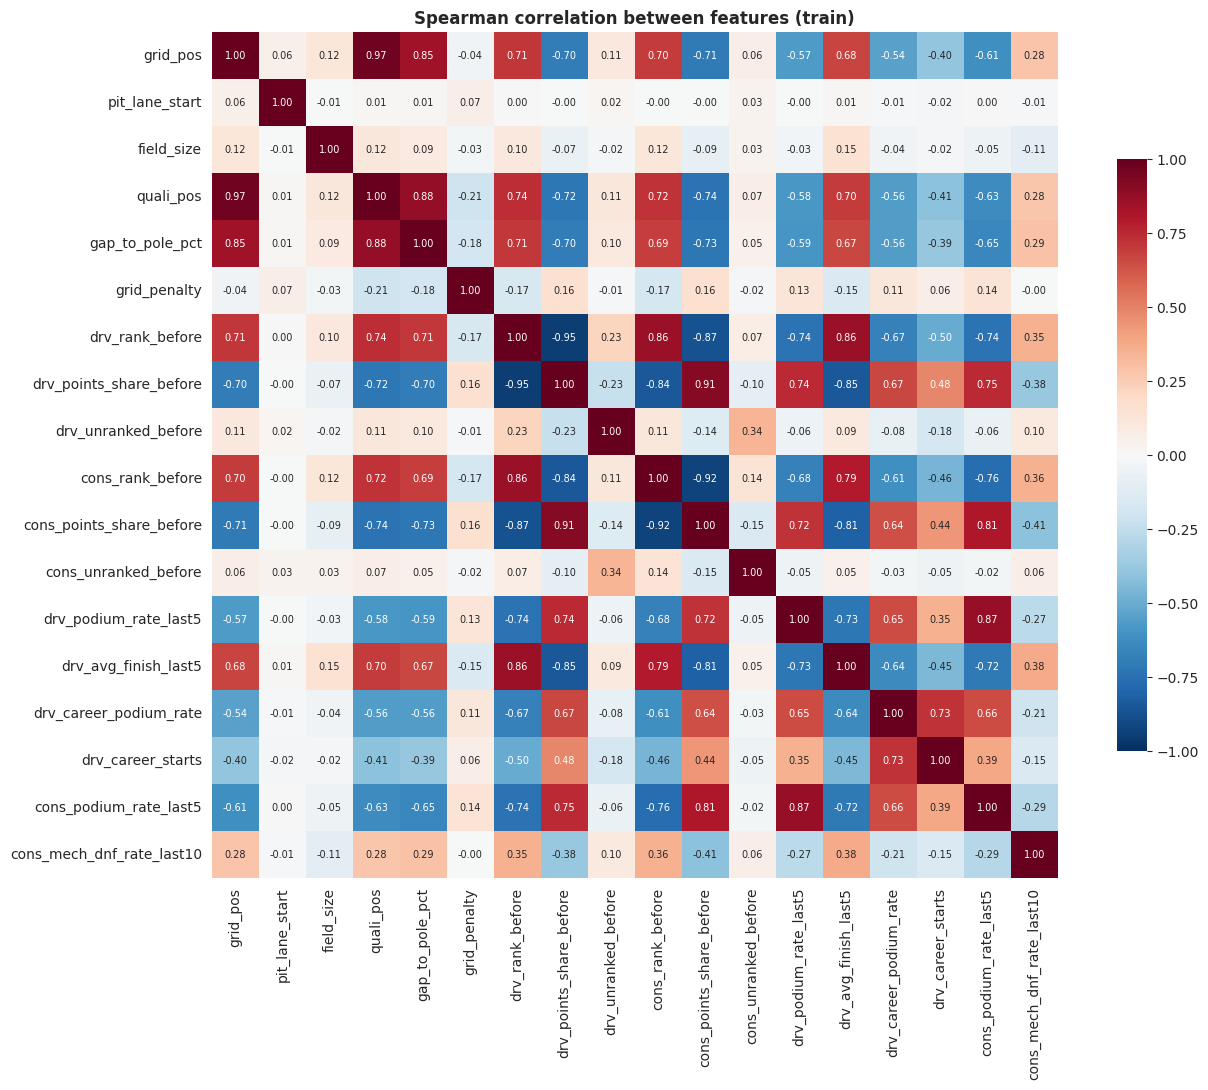

,feature_1,feature_2,rho
2,grid_pos,quali_pos,0.971
87,drv_rank_before,drv_points_share_before,-0.951
117,cons_rank_before,cons_points_share_before,-0.923
100,drv_points_share_before,cons_points_share_before,0.914
48,quali_pos,gap_to_pole_pct,0.875
141,drv_podium_rate_last5,cons_podium_rate_last5,0.873
90,drv_rank_before,cons_points_share_before,-0.870
89,drv_rank_before,cons_rank_before,0.863
93,drv_rank_before,drv_avg_finish_last5,0.863
3,grid_pos,gap_to_pole_pct,0.849


In [52]:
corr = tr[FEATURES].corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7}, square=True, cbar_kws={'shrink': 0.7})
plt.title('Spearman correlation between features (train)', fontweight='bold')
plt.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('rho').reset_index())
display(pairs[pairs['rho'].abs() >= 0.8].sort_values('rho', key=abs, ascending=False)
        .round(3).rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))

### 3.5 Findings and final feature set
**Univariate ROC-AUC (train 2003–2018):** every group contains strong features: `quali_pos` 0.909, `grid_pos` 0.907, `gap_to_pole_pct` 0.893, `cons_points_share_before` 0.888, `drv_rank_before` 0.885, `drv_points_share_before` 0.882, `cons_podium_rate_last5` 0.872, `drv_avg_finish_last5` 0.861, `drv_podium_rate_last5` 0.853. Moderate: `drv_career_starts` 0.69, `cons_mech_dnf_rate_last10` 0.64. All directions match domain expectations (better position/rank/form → more podiums; higher mechanical-DNF rate → fewer).

**Near 0.5 alone:** `grid_penalty` 0.56, `field_size` 0.52, unranked flags ≈ 0.51, `pit_lane_start` 0.50. These are **modifiers**, meaningful only in combination (penalty relative to grid, field size shifting the base rate, flags marking placeholder ranks, pit-lane starts in ~0.1% of rows). They are kept, and their contribution is measured by ablation (Chapter 5).

**Redundancy (Spearman |ρ| ≥ 0.8):** `grid_pos`–`quali_pos` 0.97; rank vs points share for drivers (−0.95) and constructors (−0.92); driver vs constructor points share (0.91) and podium form (0.87), since driver success depends heavily on the car.
- Tree models are robust to this; logistic regression uses L2 regularization, and its individual coefficients are not interpreted as importance.
- For XAI (Chapter 6), correlated features **share** importance (permuting one leaves its partner's signal intact), so importance is also assessed at the group level via ablation.

**Final feature set (18 features, 5 groups):**
| Group | Features |
|---|---|
| grid | `grid_pos`, `pit_lane_start`, `field_size` |
| qualifying | `quali_pos`, `gap_to_pole_pct`, `grid_penalty` |
| standings | `drv_rank_before`, `drv_points_share_before`, `drv_unranked_before`, `cons_rank_before`, `cons_points_share_before`, `cons_unranked_before` |
| driver_form | `drv_podium_rate_last5`, `drv_avg_finish_last5`, `drv_career_podium_rate`, `drv_career_starts` |
| constructor_form | `cons_podium_rate_last5`, `cons_mech_dnf_rate_last10` |

Every feature passes the pre-race cutoff: standings and form were verified by explicit leakage tests (Sections 3.2, 3.3).

# 4. Modeling
## 4.1 Pipeline, metrics and baselines
**Setup.** Train 2003–2018, validation 2019–2021 (model comparison and threshold choice), test 2022–2024 (used once, Section 4.4).
**Preprocessing pipeline:** median imputation with missing-value indicators, then standard scaling (for logistic regression and the neural network). Both are **fit on the training split only** inside a scikit-learn `Pipeline`, so no information from validation or test is used.
**Metrics:** ROC-AUC (ranking), PR-AUC (focus on the rare positive class; random ≈ 0.15), and at a decision threshold: F1, precision, recall. The threshold maximizes F1 **on validation**; validation F1 is therefore slightly optimistic, and the test F1 is the unbiased estimate.
**Primary metric: PR-AUC** (podiums are rare, ≈ 15%; it focuses on ranking true podium finishers and is not inflated by easy negatives). **Secondary: ROC-AUC** (overall separation, insensitive to the base rate, so comparable across eras). F1 / precision / recall describe decisions at the chosen threshold.
**Baselines:** (1) the required **statistical baseline**: logistic regression on `grid_pos` only, the simplest reasonable learned model; (2) a rule-based reference, "podium if starting in the top 3" (`grid_pos ≤ 3`). Every model must beat them.

In [53]:
def make_preprocessor(scale=True):
    """Median imputation (+ missing indicators), optional scaling. Fit on train only."""
    steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps)

def best_f1_threshold(y, p):
    """Threshold that maximizes F1 on the given (validation) data."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    return thr[np.argmax(f1)]

def metrics_row(name, split, y, p, threshold):
    pred = (p >= threshold).astype(int)
    return {'model': name, 'split': split,
            'roc_auc': roc_auc_score(y, p), 'pr_auc': average_precision_score(y, p),
            'f1': f1_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'threshold': threshold}

results = []          # one row per (model, split)
fitted = {}           # model name -> (predict-probability function, threshold)

def register(name, predict_fn, threshold=None):
    """Score a fitted model on train and validation; choose the threshold on validation."""
    p_tr, p_va = predict_fn(X_train), predict_fn(X_val)
    if threshold is None:
        threshold = best_f1_threshold(y_val, p_va)
    global results
    results = [r for r in results if r['model'] != name]          # allow re-running a cell
    results += [metrics_row(name, 'train', y_train, p_tr, threshold),
                metrics_row(name, 'val', y_val, p_va, threshold)]
    fitted[name] = (predict_fn, threshold)
    return pd.DataFrame(results).set_index(['model', 'split']).round(3)

print("Tools ready. Podium rate — train: "
      f"{y_train.mean():.3f} | val: {y_val.mean():.3f} (= PR-AUC of a random model)")

Tools ready. Podium rate — train: 0.141 | val: 0.150 (= PR-AUC of a random model)


In [54]:
# Baseline: score = -grid_pos (lower grid = higher score).
# Threshold -3  ->  "podium if grid_pos <= 3"
baseline_fn = lambda X: -X['grid_pos'].to_numpy(dtype=float)
display(register('Baseline (grid ≤ 3)', baseline_fn, threshold=-3))

# Statistical baseline (the brief requires a statistical ML model or shallow FFNN as baseline):
# logistic regression using ONLY the starting position
base_lr = Pipeline([('prep', make_preprocessor(scale=True)),
                    ('clf', LogisticRegression(max_iter=2000))]).fit(X_train[['grid_pos']], y_train)
display(register('Baseline LR (grid only)', lambda X: base_lr.predict_proba(X[['grid_pos']])[:, 1]))

roc_auc  pr_auc     f1  precision  recall  \
model               split                                              
Baseline (grid ≤ 3) train    0.907   0.618  0.638      0.638   0.638   
                    val      0.917   0.676  0.717      0.717   0.717   

                           threshold  
model               split             
Baseline (grid ≤ 3) train         -3  
                    val           -3

roc_auc  pr_auc     f1  precision  recall  \
model                   split                                              
Baseline (grid ≤ 3)     train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Baseline LR (grid only) train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   

                               threshold  
model                   split             
Baseline (grid ≤ 3)     train     -3.000  
                        val       -3.000  
Baseline LR (grid only) train      0.471  
                        val        0.471

## 4.2 Classic models
Each model gets a small hyperparameter search (trial and error), selected by **validation PR-AUC** (main metric: the positive class is rare):
- **Logistic Regression** (L2): `C` ∈ {0.01, 0.1, 1, 10}, with imputation + scaling.
- **Random Forest** (400 trees): `min_samples_leaf` ∈ {5, 20, 50}, imputation only (trees need no scaling).
- **LightGBM** (gradient boosting): `num_leaves` ∈ {7, 15, 31}, learning rate 0.02, early stopping on validation PR-AUC.
Since validation is used for selection, validation scores are slightly optimistic; the test split (Section 4.4) is the final, unbiased evaluation.

In [55]:
lr_search = []
for c_value in [0.01, 0.1, 1, 10]:   # not named 'C': that would shadow C() in the Q2 formulas
    m = Pipeline([('prep', make_preprocessor(scale=True)),
                  ('clf', LogisticRegression(C=c_value, max_iter=2000))]).fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    lr_search.append({'C': c_value, 'val_roc_auc': roc_auc_score(y_val, p),
                      'val_pr_auc': average_precision_score(y_val, p)})
lr_search = pd.DataFrame(lr_search)
display(lr_search.round(4))

best_C = lr_search.loc[lr_search['val_pr_auc'].idxmax(), 'C']
lr_model = Pipeline([('prep', make_preprocessor(scale=True)),
                     ('clf', LogisticRegression(C=best_C, max_iter=2000))]).fit(X_train, y_train)
print(f"Selected C = {best_C}")
display(register('Logistic Regression', lambda X: lr_model.predict_proba(X)[:, 1]))

,C,val_roc_auc,val_pr_auc
0,0.01,0.9350,0.7263
1,0.10,0.9384,0.7396
2,1.00,0.9388,0.7408
3,10.00,0.9388,0.7411


Selected C = 10.0


roc_auc  pr_auc     f1  precision  recall  \
model                   split                                              
Baseline (grid ≤ 3)     train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Baseline LR (grid only) train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Logistic Regression     train    0.930   0.685  0.669      0.604   0.750   
                        val      0.939   0.741  0.723      0.667   0.789   

                               threshold  
model                   split             
Baseline (grid ≤ 3)     train     -3.000  
                        val       -3.000  
Baseline LR (grid only) train      0.471  
                        val        0.471  
Logistic Regression     train      0.334  
                        val        0.334

In [56]:
rf_search = []
for leaf in [5, 20, 50]:
    m = Pipeline([('prep', make_preprocessor(scale=False)),
                  ('clf', RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf,
                                                 max_features='sqrt', n_jobs=-1,
                                                 random_state=SEED))]).fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    rf_search.append({'min_samples_leaf': leaf, 'val_roc_auc': roc_auc_score(y_val, p),
                      'val_pr_auc': average_precision_score(y_val, p)})
rf_search = pd.DataFrame(rf_search)
display(rf_search.round(4))

best_leaf = int(rf_search.loc[rf_search['val_pr_auc'].idxmax(), 'min_samples_leaf'])
rf_model = Pipeline([('prep', make_preprocessor(scale=False)),
                     ('clf', RandomForestClassifier(n_estimators=400, min_samples_leaf=best_leaf,
                                                    max_features='sqrt', n_jobs=-1,
                                                    random_state=SEED))]).fit(X_train, y_train)
# Predict with one thread: parallel vote-summing changes the last decimals between runs,
# which flips rows lying exactly on the threshold. One thread = identical results every time.
rf_model.named_steps['clf'].set_params(n_jobs=1)
print(f"Selected min_samples_leaf = {best_leaf}")
display(register('Random Forest', lambda X: rf_model.predict_proba(X)[:, 1]))

,min_samples_leaf,val_roc_auc,val_pr_auc
0,5,0.9398,0.7425
1,20,0.9400,0.7542
2,50,0.9404,0.7425


Selected min_samples_leaf = 20


roc_auc  pr_auc     f1  precision  recall  \
model                   split                                              
Baseline (grid ≤ 3)     train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Baseline LR (grid only) train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Logistic Regression     train    0.930   0.685  0.669      0.604   0.750   
                        val      0.939   0.741  0.723      0.667   0.789   
Random Forest           train    0.955   0.768  0.683      0.703   0.663   
                        val      0.940   0.754  0.734      0.724   0.744   

                               threshold  
model                   split             
Baseline (grid ≤ 3)     train     -3.000  
                        val       -3.000  
Baseline LR (grid only) train      0.471  
                        val        0.471  
Logistic Regression     train      0.334  
                        val        0.334  
Random Forest           train      0.437  
                        val        0.437

In [57]:
# Imputer fit on train only; pandas output keeps feature names (needed later for XAI)
prep_tree = make_preprocessor(scale=False).set_output(transform='pandas').fit(X_train)
Xtr_t, Xva_t = prep_tree.transform(X_train), prep_tree.transform(X_val)

lgb_search, lgb_models = [], {}
for leaves in [7, 15, 31]:
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=leaves,
                           min_child_samples=30, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=SEED, verbose=-1,
                           metric='average_precision')   # the ONLY tracked metric = PR-AUC
    m.fit(Xtr_t, y_train, eval_set=[(Xva_t, y_val)],
          callbacks=[lgb.early_stopping(200, first_metric_only=True, verbose=False)])
    p = m.predict_proba(Xva_t)[:, 1]
    lgb_search.append({'num_leaves': leaves, 'best_n_trees': m.best_iteration_,
                       'val_roc_auc': roc_auc_score(y_val, p),
                       'val_pr_auc': average_precision_score(y_val, p)})
    lgb_models[leaves] = m
lgb_search = pd.DataFrame(lgb_search)
display(lgb_search.round(4))

best_leaves = int(lgb_search.loc[lgb_search['val_pr_auc'].idxmax(), 'num_leaves'])
lgb_model = lgb_models[best_leaves]
print(f"Selected num_leaves = {best_leaves} ({lgb_model.best_iteration_} trees)")
display(register('LightGBM', lambda X: lgb_model.predict_proba(prep_tree.transform(X))[:, 1]))

,num_leaves,best_n_trees,val_roc_auc,val_pr_auc
0,7,72,0.9394,0.7535
1,15,44,0.9403,0.7515
2,31,59,0.9393,0.7562


Selected num_leaves = 31 (59 trees)


roc_auc  pr_auc     f1  precision  recall  \
model                   split                                              
Baseline (grid ≤ 3)     train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Baseline LR (grid only) train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Logistic Regression     train    0.930   0.685  0.669      0.604   0.750   
                        val      0.939   0.741  0.723      0.667   0.789   
Random Forest           train    0.955   0.768  0.683      0.703   0.663   
                        val      0.940   0.754  0.734      0.724   0.744   
LightGBM                train    0.957   0.791  0.737      0.691   0.789   
                        val      0.939   0.756  0.732      0.683   0.789   

                               threshold  
model                   split             
Baseline (grid ≤ 3)     train     -3.000  
                        val       -3.000  
Baseline LR (grid only) train      0.471  
                        val        0.471  
Logistic Regression     train      0.334  
                        val        0.334  
Random Forest           train      0.437  
                        val        0.437  
LightGBM                train      0.302  
                        val        0.302

### 4.2 Findings (validation 2019–2021)
| Model | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Baseline LR (grid only) — statistical baseline | 0.917 | 0.676 | 0.717 | 0.717 | 0.717 |
| Baseline rule (grid ≤ 3) — reference | 0.917 | 0.676 | 0.717 | 0.717 | 0.717 |
| Logistic Regression (C = 10) | 0.939 | 0.741 | 0.723 | 0.667 | 0.789 |
| Random Forest (min_samples_leaf = 20) | 0.940 | 0.754 | 0.734 | 0.724 | 0.744 |
| LightGBM (num_leaves = 31, 59 trees) | 0.939 | 0.756 | 0.732 | 0.683 | 0.789 |

- **The statistical baseline equals the rule:** logistic regression on `grid_pos` alone ranks drivers in grid order, and its F1-optimal threshold (0.471) corresponds exactly to "grid ≤ 3", so all metrics coincide.
- All models beat the baselines, most clearly on PR-AUC (+0.065 to +0.080): standings, form and reliability add information beyond the grid, although the grid already captures most of the signal (F1 gain ≤ +0.017).
- The three models are within 0.015 PR-AUC of each other; on 1,200 validation rows (180 podiums) this is within plausible noise. Remaining error reflects race-day randomness (incidents, strategy, failures).
- Hyperparameter searches changed PR-AUC by at most 0.015 (LR: weaker regularization slightly better; RF: medium leaf size best; LightGBM: `num_leaves` nearly irrelevant, early stopping on validation PR-AUC after 44–72 trees).
- Train–validation gaps are small (RF 0.768 vs 0.754, LightGBM 0.791 vs 0.756 PR-AUC), so no model strongly overfits. The baselines and LR score higher on validation than on train, reflecting an easier, more predictable recent era.
- F1-optimal thresholds are 0.30–0.44 (below 0.5) because podiums are rare; recall exceeds precision for most models.
- **Baseline note:** "grid ≤ 3" predicts exactly 3 podiums per race, matching the 3 real podiums, so its precision, recall and F1 are equal.

## 4.3 Shallow neural network (PyTorch)
Inputs: the same 18 features after imputation (+ missing indicators) and standard scaling, fit on train only.
- **Architecture:** fully connected hidden layer(s) with ReLU and 20% dropout, one output with a sigmoid (podium probability). Tried: (16), (32), (64 → 32).
- **Training:** binary cross-entropy loss, Adam (lr = 0.001, weight decay = 1e-4), batches of 128, up to 300 epochs.
- **Early stopping:** validation PR-AUC checked every epoch; training stops after 25 epochs without improvement and the best epoch's weights are restored.
- Seeds are fixed for reproducibility.

In [58]:
prep_nn = make_preprocessor(scale=True).fit(X_train)                      # fit on train only
Xtr_n = torch.tensor(prep_nn.transform(X_train), dtype=torch.float32)
Xva_n = torch.tensor(prep_nn.transform(X_val), dtype=torch.float32)
ytr_n = torch.tensor(y_train.values, dtype=torch.float32)
yva_n = torch.tensor(y_val.values, dtype=torch.float32)

class ShallowNet(nn.Module):
    def __init__(self, n_in, hidden=(32,), dropout=0.2):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))            # one output = podium logit
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

def train_nn(hidden, dropout=0.2, lr=1e-3, weight_decay=1e-4,
             max_epochs=300, patience=25, batch_size=128):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = ShallowNet(Xtr_n.shape[1], hidden, dropout)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()                 # sigmoid + binary cross-entropy
    loader = DataLoader(TensorDataset(Xtr_n, ytr_n), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    best_ap, best_state, best_epoch, wait, history = -1, None, 0, 0, []
    for epoch in range(1, max_epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()                          # how should each weight change?
            opt.step()                               # nudge the weights
            total += loss.item() * len(xb)
        model.eval()                                 # dropout off for evaluation
        with torch.no_grad():
            logits_va = model(Xva_n)
            val_loss = loss_fn(logits_va, yva_n).item()
            ap = average_precision_score(y_val, torch.sigmoid(logits_va).numpy())
        history.append({'epoch': epoch, 'train_loss': total / len(Xtr_n),
                        'val_loss': val_loss, 'val_pr_auc': ap})
        if ap > best_ap + 1e-4:                      # improvement -> remember these weights
            best_ap, best_epoch, wait = ap, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:                     # early stopping
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch, best_ap

nn_search, nn_runs = [], {}
for hidden in [(16,), (32,), (64, 32)]:
    m, hist, best_ep, best_ap = train_nn(hidden)
    nn_runs[hidden] = (m, hist, best_ep)
    nn_search.append({'hidden_layers': str(hidden), 'best_epoch': best_ep,
                      'epochs_run': len(hist), 'val_pr_auc': best_ap})
nn_search = pd.DataFrame(nn_search)
display(nn_search.round(4))

best_hidden = max(nn_runs, key=lambda h: nn_search.loc[nn_search['hidden_layers'] == str(h),
                                                       'val_pr_auc'].item())
nn_model, nn_hist, nn_best_epoch = nn_runs[best_hidden]
print(f"Selected architecture: {best_hidden}, best epoch {nn_best_epoch}")

def nn_predict(X):
    with torch.no_grad():
        x = torch.tensor(prep_nn.transform(X), dtype=torch.float32)
        return torch.sigmoid(nn_model(x)).numpy()

display(register('Shallow NN', nn_predict))

,hidden_layers,best_epoch,epochs_run,val_pr_auc
0,"(16,)",86,111,0.7456
1,"(32,)",84,109,0.7535
2,"(64, 32)",26,51,0.7457


Selected architecture: (32,), best epoch 84


roc_auc  pr_auc     f1  precision  recall  \
model                   split                                              
Baseline (grid ≤ 3)     train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Baseline LR (grid only) train    0.907   0.618  0.638      0.638   0.638   
                        val      0.917   0.676  0.717      0.717   0.717   
Logistic Regression     train    0.930   0.685  0.669      0.604   0.750   
                        val      0.939   0.741  0.723      0.667   0.789   
Random Forest           train    0.955   0.768  0.683      0.703   0.663   
                        val      0.940   0.754  0.734      0.724   0.744   
LightGBM                train    0.957   0.791  0.737      0.691   0.789   
                        val      0.939   0.756  0.732      0.683   0.789   
Shallow NN              train    0.939   0.705  0.679      0.605   0.772   
                        val      0.938   0.753  0.730      0.675   0.794   

                               threshold  
model                   split             
Baseline (grid ≤ 3)     train     -3.000  
                        val       -3.000  
Baseline LR (grid only) train      0.471  
                        val        0.471  
Logistic Regression     train      0.334  
                        val        0.334  
Random Forest           train      0.437  
                        val        0.437  
LightGBM                train      0.302  
                        val        0.302  
Shallow NN              train      0.341  
                        val        0.341

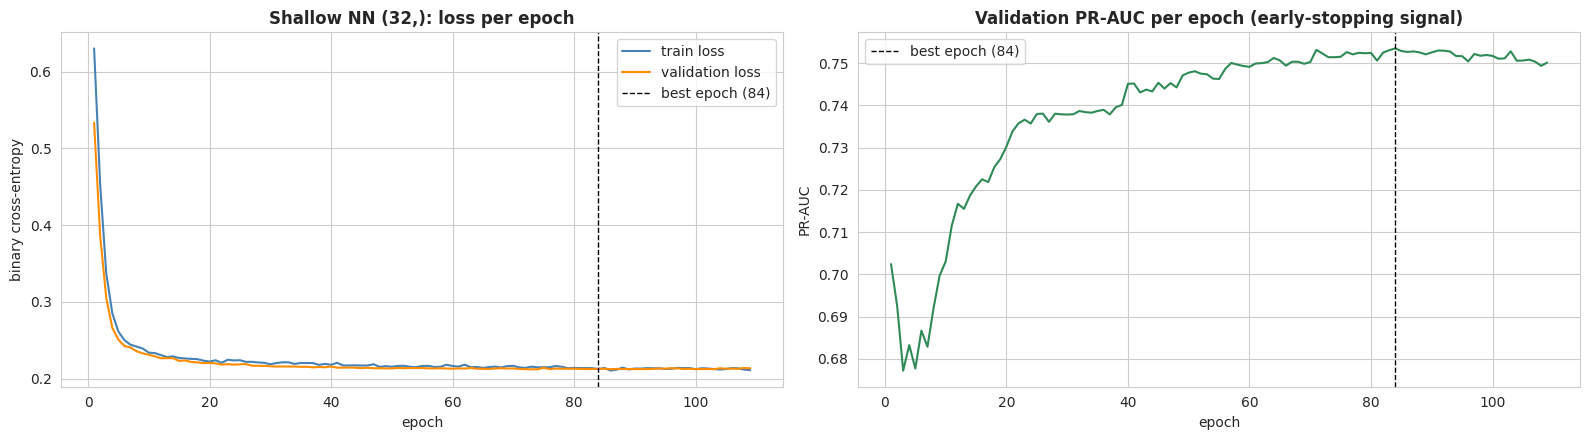

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(nn_hist['epoch'], nn_hist['train_loss'], label='train loss', color='steelblue')
axes[0].plot(nn_hist['epoch'], nn_hist['val_loss'], label='validation loss', color='darkorange')
axes[1].plot(nn_hist['epoch'], nn_hist['val_pr_auc'], color='seagreen')
for ax in axes:
    ax.axvline(nn_best_epoch, color='black', ls='--', lw=1, label=f'best epoch ({nn_best_epoch})')
    ax.set_xlabel('epoch'); ax.legend()
axes[0].set_title(f'Shallow NN {best_hidden}: loss per epoch', fontweight='bold')
axes[1].set_title('Validation PR-AUC per epoch (early-stopping signal)', fontweight='bold')
axes[0].set_ylabel('binary cross-entropy'); axes[1].set_ylabel('PR-AUC')
plt.tight_layout()
plt.show()

### 4.3 Findings
| Architecture | Best epoch | Epochs run | Val PR-AUC |
|---|---|---|---|
| (16) | 86 | 111 | 0.746 |
| **(32)** | **84** | **109** | **0.754** |
| (64 → 32) | 26 | 51 | 0.746 |

- One hidden layer of 32 neurons is selected (val ROC-AUC 0.938, PR-AUC 0.753, F1 0.730). The two-layer network peaked at epoch 26 without gaining: extra capacity does not help on this signal.
- **Learning curves:** train and validation loss decrease together and stay nearly identical, so the network does not overfit; validation PR-AUC plateaus around 0.75 after ≈ 60 epochs, and early stopping restored epoch 84 (stopped at 84 + 25 patience).
- All four model families reach val PR-AUC 0.741–0.756, indicating that most of the signal available in pre-race features has been captured; remaining error reflects race-day randomness.

## 4.4 Model comparison, final model, and test evaluation
- **Curves on validation:** ROC and precision–recall curves for all models.
- **Decision rule experiment:** each race has exactly 3 podiums, so besides the F1-optimal threshold we test a **top-3-per-race** rule (predict podium for the 3 highest probabilities in each race).
- **Final model:** chosen programmatically by **highest validation PR-AUC, before the test set is used**.
- **Test (2022–2024) is evaluated once**, with thresholds fixed from validation; no tuning happens afterwards. All models are reported for transparency.

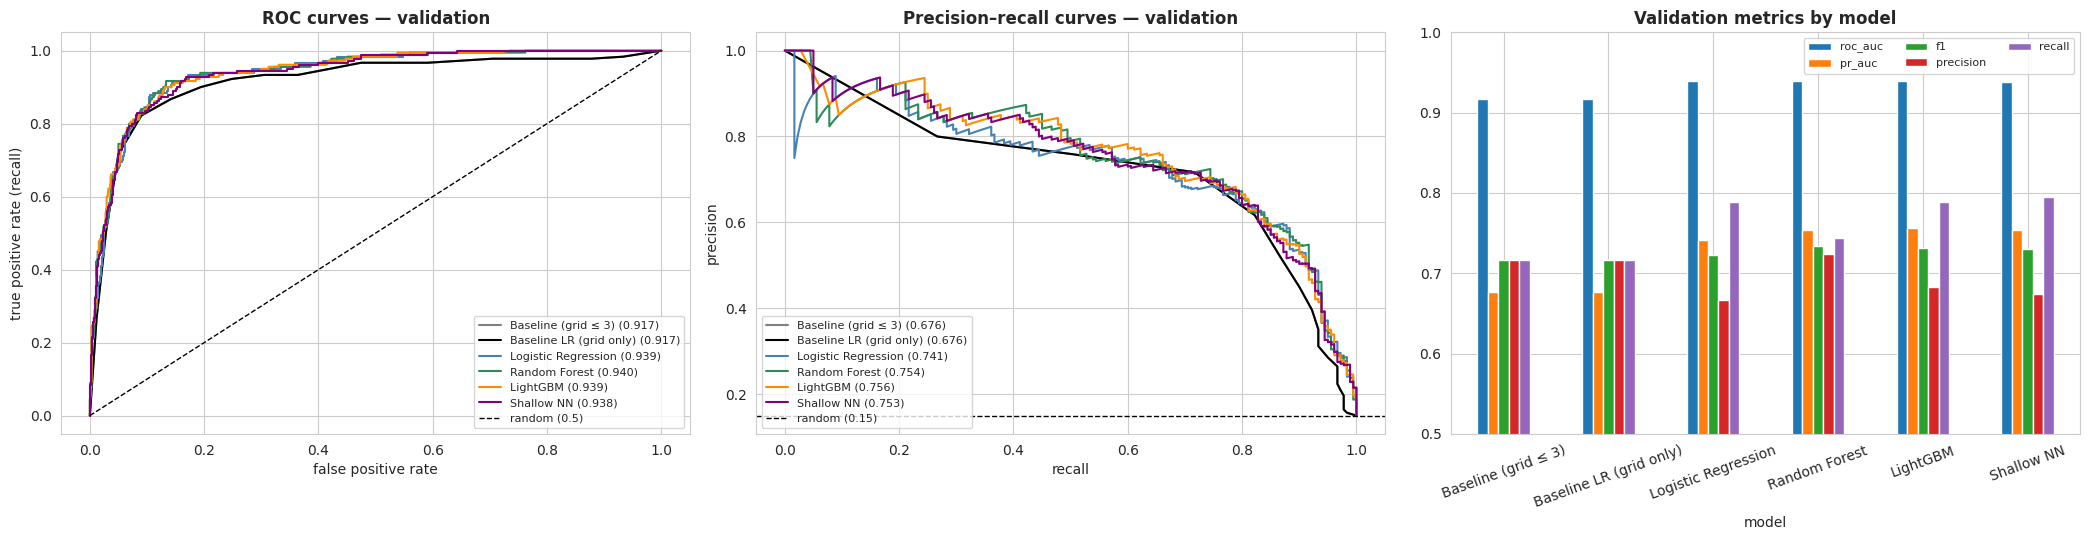

,F1 (threshold from val),F1 (top-3 per race)
model,,
Baseline (grid ≤ 3),0.717,0.717
Baseline LR (grid only),0.717,0.717
Logistic Regression,0.723,0.683
Random Forest,0.734,0.700
LightGBM,0.732,0.711
Shallow NN,0.730,0.711


Final model (highest validation PR-AUC): LightGBM


In [60]:
val_race = data.loc[data['split'] == 'val', 'raceId'].to_numpy()
test_race = data.loc[data['split'] == 'test', 'raceId'].to_numpy()

def top3_rule(p, race_ids, k=3):
    """Predict podium for the k highest probabilities in each race."""
    rank = pd.Series(p).groupby(race_ids).rank(ascending=False, method='first')
    return (rank <= k).astype(int).to_numpy()

model_names = list(fitted.keys())
colors = dict(zip(model_names, ['grey', 'black', 'steelblue', 'seagreen', 'darkorange', 'purple']))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
rule_rows = []
for name in model_names:
    fn, thr = fitted[name]
    p = fn(X_val)
    fpr, tpr, _ = roc_curve(y_val, p)
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(y_val, p):.3f})")
    axes[1].plot(rec, prec, color=colors[name], label=f"{name} ({average_precision_score(y_val, p):.3f})")
    rule_rows.append({'model': name,
                      'F1 (threshold from val)': f1_score(y_val, (p >= thr).astype(int)),
                      'F1 (top-3 per race)': f1_score(y_val, top3_rule(p, val_race))})

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='random (0.5)')
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate (recall)')
axes[0].set_title('ROC curves — validation', fontweight='bold')
axes[1].axhline(y_val.mean(), color='black', ls='--', lw=1, label=f'random ({y_val.mean():.2f})')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].set_title('Precision–recall curves — validation', fontweight='bold')
for ax in axes[:2]:
    ax.legend(fontsize=8, loc='lower left' if ax is axes[1] else 'lower right')

val_tbl = (pd.DataFrame(results).query("split == 'val'").set_index('model')
           [['roc_auc', 'pr_auc', 'f1', 'precision', 'recall']])
val_tbl.plot.bar(ax=axes[2], rot=20)
axes[2].set_ylim(0.5, 1); axes[2].set_title('Validation metrics by model', fontweight='bold')
axes[2].legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

rule_tbl = pd.DataFrame(rule_rows).set_index('model').round(3)
display(rule_tbl)

# Final model: highest validation PR-AUC (decided BEFORE touching the test set)
FINAL_MODEL = val_tbl.drop(index=['Baseline (grid ≤ 3)', 'Baseline LR (grid only)'])['pr_auc'].idxmax()
print(f"Final model (highest validation PR-AUC): {FINAL_MODEL}")

,roc_auc,pr_auc,f1,precision,recall,threshold,f1_top3_per_race
model,,,,,,,
Baseline (grid ≤ 3),0.914,0.647,0.649,0.650,0.647,-3.000,0.652
Baseline LR (grid only),0.914,0.647,0.649,0.650,0.647,0.471,0.652
Logistic Regression,0.934,0.701,0.685,0.630,0.750,0.334,0.642
Random Forest,0.938,0.710,0.658,0.686,0.632,0.437,0.652
LightGBM,0.935,0.693,0.657,0.648,0.667,0.302,0.642
Shallow NN,0.936,0.702,0.670,0.618,0.730,0.341,0.647


,validation,test
roc_auc,0.939,0.935
pr_auc,0.756,0.693
f1,0.732,0.657
precision,0.683,0.648
recall,0.789,0.667


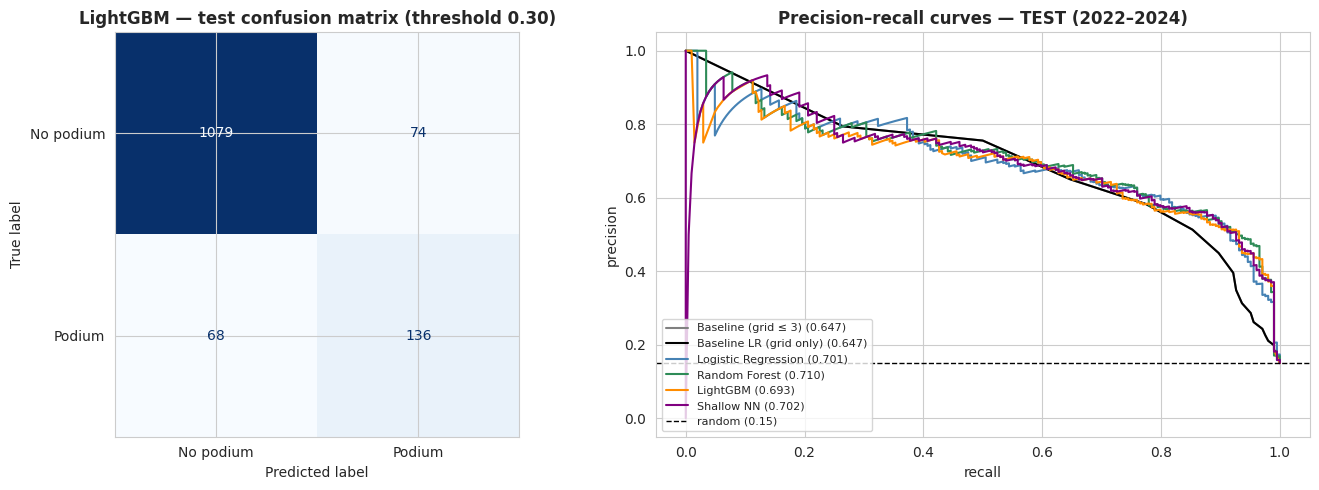

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ===== TEST SET: evaluated ONCE, thresholds fixed from validation, no tuning afterwards =====
test_rows, test_probs = [], {}
for name in model_names:
    fn, thr = fitted[name]
    p = fn(X_test)
    test_probs[name] = p
    row = metrics_row(name, 'test', y_test, p, thr)
    row['f1_top3_per_race'] = f1_score(y_test, top3_rule(p, test_race))
    test_rows.append(row)
test_results = pd.DataFrame(test_rows).drop(columns='split').set_index('model').round(3)
display(test_results)

# Final model: validation vs test side by side
cols = ['roc_auc', 'pr_auc', 'f1', 'precision', 'recall']
final_cmp = pd.DataFrame({'validation': val_tbl.loc[FINAL_MODEL, cols],
                          'test': test_results.loc[FINAL_MODEL, cols]}).round(3)
display(final_cmp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
thr = fitted[FINAL_MODEL][1]
cm = confusion_matrix(y_test, (test_probs[FINAL_MODEL] >= thr).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['No podium', 'Podium']).plot(ax=axes[0], cmap='Blues',
                                                                        colorbar=False)
axes[0].set_title(f'{FINAL_MODEL} — test confusion matrix (threshold {thr:.2f})', fontweight='bold')
for name in model_names:
    prec, rec, _ = precision_recall_curve(y_test, test_probs[name])
    axes[1].plot(rec, prec, color=colors[name],
                 label=f"{name} ({average_precision_score(y_test, test_probs[name]):.3f})")
axes[1].axhline(y_test.mean(), color='black', ls='--', lw=1, label=f'random ({y_test.mean():.2f})')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].set_title('Precision–recall curves — TEST (2022–2024)', fontweight='bold')
axes[1].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

In [62]:
# Model comparison table (deliverable): all five metrics on train, validation AND test
res_df = pd.DataFrame(results)
comparison = pd.concat({'train': res_df.query("split == 'train'").set_index('model')[cols],
                        'validation': res_df.query("split == 'val'").set_index('model')[cols],
                        'test': test_results[cols]}, axis=1).round(3)
display(comparison)

train                                validation  \
                        roc_auc pr_auc     f1 precision recall    roc_auc   
model                                                                       
Baseline (grid ≤ 3)       0.907  0.618  0.638     0.638  0.638      0.917   
Baseline LR (grid only)   0.907  0.618  0.638     0.638  0.638      0.917   
Logistic Regression       0.930  0.685  0.669     0.604  0.750      0.939   
Random Forest             0.955  0.768  0.683     0.703  0.663      0.940   
LightGBM                  0.957  0.791  0.737     0.691  0.789      0.939   
Shallow NN                0.939  0.705  0.679     0.605  0.772      0.938   

                                                          test                \
                        pr_auc     f1 precision recall roc_auc pr_auc     f1   
model                                                                          
Baseline (grid ≤ 3)      0.676  0.717     0.717  0.717   0.914  0.647  0.649   
Baseline LR (grid only)  0.676  0.717     0.717  0.717   0.914  0.647  0.649   
Logistic Regression      0.741  0.723     0.667  0.789   0.934  0.701  0.685   
Random Forest            0.754  0.734     0.724  0.744   0.938  0.710  0.658   
LightGBM                 0.756  0.732     0.683  0.789   0.935  0.693  0.657   
Shallow NN               0.753  0.730     0.675  0.794   0.936  0.702  0.670   

                                          
                        precision recall  
model                                     
Baseline (grid ≤ 3)         0.650  0.647  
Baseline LR (grid only)     0.650  0.647  
Logistic Regression         0.630  0.750  
Random Forest               0.686  0.632  
LightGBM                    0.648  0.667  
Shallow NN                  0.618  0.730

### 4.4 Findings — model comparison and test evaluation
**Validation:** all models beat the baseline mainly at high recall (the precision–recall curves separate beyond recall ≈ 0.8), i.e. by finding podiums from drivers who did not start in the top 3.

**Top-3-per-race rule (rejected):** forcing exactly 3 podium predictions per race lowers F1 for every model (e.g. LightGBM 0.732 → 0.711 on validation), and the models' top 3 is not better than the grid's top 3 (0.700–0.711 vs 0.717). Within a race the starting order is already near-optimal for choosing three names; the models' value lies in probabilities comparable across races and in flexible decisions (fewer or more than three likely podiums per race).

**Test (2022–2024, evaluated once; thresholds fixed from validation):**
| Model | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Baseline LR (grid only) | 0.914 | 0.647 | 0.649 | 0.650 | 0.647 |
| Baseline rule (grid ≤ 3) | 0.914 | 0.647 | 0.649 | 0.650 | 0.647 |
| Logistic Regression | 0.934 | 0.701 | 0.685 | 0.630 | 0.750 |
| Random Forest | 0.938 | 0.710 | 0.658 | 0.686 | 0.632 |
| **LightGBM (final)** | **0.935** | **0.693** | **0.657** | **0.648** | **0.667** |
| Shallow NN | 0.936 | 0.702 | 0.670 | 0.618 | 0.730 |

- **Ranking holds under the 2022 regulation change:** final-model ROC-AUC 0.939 (val) → 0.935 (test).
- **PR-AUC and F1 drop** (0.756 → 0.693; 0.732 → 0.657), but the baselines drop similarly (F1 0.717 → 0.649), so the decline mainly reflects a harder period, not overfitting. A plausible cause is the 2022 regulation reset: standings and form carried over from previous seasons briefly describe outdated cars (hypothesis).
- All models still beat the baselines on test in PR-AUC (+0.046 to +0.063) and ROC-AUC; F1 gains range from +0.008 (LightGBM, Random Forest) to +0.036 (Logistic Regression).
- **Model ranking changes on test** (Random Forest best, 0.710). The final model was fixed on validation (LightGBM, ahead by only 0.002) and is **not** changed after seeing test results, which would bias the reported score. This confirms that the four model families are effectively tied.
- **Confusion matrix (LightGBM, test):** 136 of 204 podiums caught (recall 0.667), 136 of 210 podium calls correct (precision 0.648), 74 false alarms, 68 misses; ≈ 3.1 podium predictions per race without forcing it.
- **Threshold shift:** recall fell from 0.789 to 0.667 because the validation-chosen threshold (0.30) is applied to an era where podium finishers received lower probabilities, a typical symptom of distribution shift.

### Metric choice, how the models work, and their limitations
**Primary metric: PR-AUC.** Podiums are rare (≈ 15% of rows) and the task is to rank true podium finishers above everyone else; PR-AUC focuses on the positive class and is not inflated by the many easy negatives (back-markers). Random PR-AUC ≈ 0.15.
**Secondary metric: ROC-AUC.** Overall separation; insensitive to the base rate, so comparable across eras with different field sizes (12.5–15% podium rate).
**F1 (with precision and recall)** is the decision-level metric at the threshold chosen on validation.

| Model | How it works | Limitations |
|---|---|---|
| **Baseline LR (grid only)** | Logistic regression on `grid_pos`: podium probability decreases with starting position. | Ignores form, standings and reliability; cannot tell a fast car starting out of position from a slow one. |
| **Logistic Regression** | Weighted sum of all (scaled) features passed through a sigmoid; L2 regularization. | Assumes additive, linear effects (no interactions such as penalty × qualifying position); correlated features make individual coefficients unstable, so they are not read as importance. |
| **Random Forest** | 400 decision trees on bootstrap samples with random feature subsets; probability = average vote. | Probabilities are not well calibrated; less interpretable than LR; cannot extrapolate beyond values seen in training (e.g. a new era). |
| **LightGBM** | Gradient boosting: small trees added one after another, each correcting the previous errors; early stopping on validation PR-AUC. | Sensitive to hyperparameters; early stopping uses validation, so validation scores are slightly optimistic; same extrapolation limit as other trees. |
| **Shallow NN** | One hidden layer (32 ReLU units, 20% dropout), sigmoid output, Adam on binary cross-entropy; early stopping on validation PR-AUC. | Needs scaling and many training choices; least interpretable; with ~6,400 training rows it has no advantage over simpler models. |

**Shared limitations:** all models learn from 2003–2018 and degrade under era shifts (2022 regulation reset: test PR-AUC drops for every model, including the baselines); race-day randomness (incidents, strategy, weather) is not observable before the start and caps achievable performance.

# 5. Experiments
## 5.1 Effect of preprocessing on the data
The preprocessing pipeline (fit on train only) applies median imputation with missing-value indicators, then standard scaling. Below: summary statistics and distributions of representative training features before and after. Scaling is linear, so it changes location and spread but not the shape of a distribution; imputation adds a small spike at the median.

Columns: 18 raw features → 26 after preprocessing (8 missing-value indicators added)
Indicators: ['missingindicator_quali_pos', 'missingindicator_gap_to_pole_pct', 'missingindicator_grid_penalty', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_avg_finish_last5', 'missingindicator_drv_career_podium_rate', 'missingindicator_cons_podium_rate_last5', 'missingindicator_cons_mech_dnf_rate_last10']


before (raw train)                             \
                                       mean    std  min    max missing   
gap_to_pole_pct                        2.23   1.81  0.0    7.0     114   
drv_career_starts                     92.62  79.43  0.0  325.0       0   
cons_points_share_before               0.30   0.34  0.0    1.0       0   
drv_podium_rate_last5                  0.14   0.25  0.0    1.0      72   

                         after (imputed + scaled)                           
                                             mean  std   min   max missing  
gap_to_pole_pct                               0.0  1.0 -1.24  2.66       0  
drv_career_starts                             0.0  1.0 -1.17  2.93       0  
cons_points_share_before                      0.0  1.0 -0.89  2.08       0  
drv_podium_rate_last5                         0.0  1.0 -0.56  3.43       0

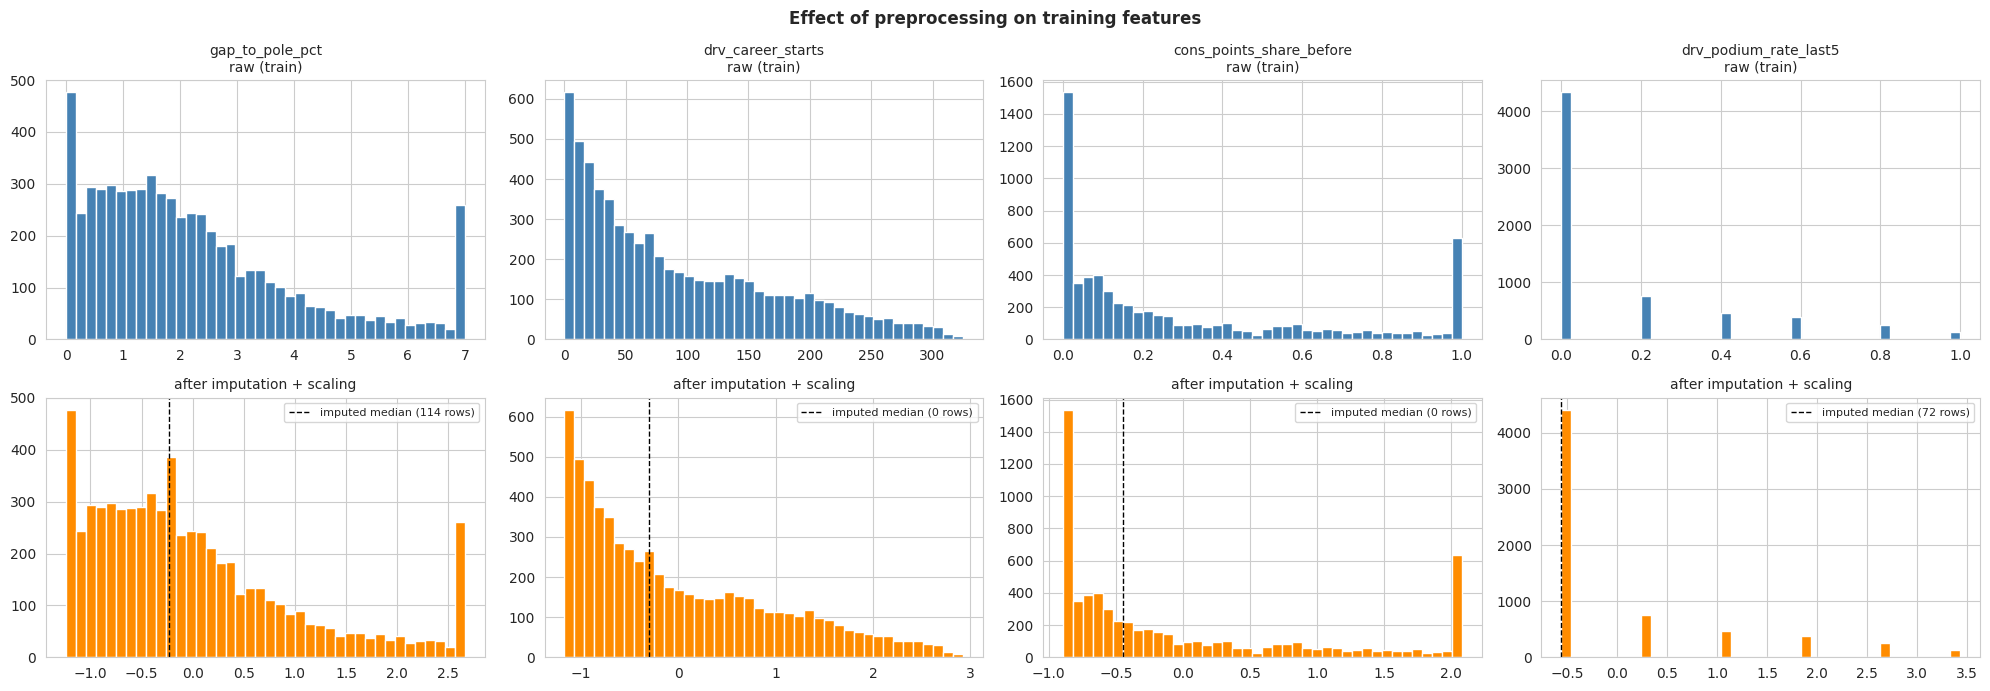

In [63]:
prep_demo = make_preprocessor(scale=True).set_output(transform='pandas').fit(X_train)
Ztr = prep_demo.transform(X_train)
print(f"Columns: {X_train.shape[1]} raw features → {Ztr.shape[1]} after preprocessing "
      f"({Ztr.shape[1] - X_train.shape[1]} missing-value indicators added)")
print("Indicators:", [c for c in Ztr.columns if c.startswith('missingindicator')])

show = ['gap_to_pole_pct', 'drv_career_starts', 'cons_points_share_before', 'drv_podium_rate_last5']
def summary_stats(df):
    s = df[show].agg(['mean', 'std', 'min', 'max']).T
    s['missing'] = df[show].isna().sum()
    return s
display(pd.concat({'before (raw train)': summary_stats(X_train),
                   'after (imputed + scaled)': summary_stats(Ztr)}, axis=1).round(2))

sc = prep_demo.named_steps['scale']
fig, axes = plt.subplots(2, len(show), figsize=(20, 7))
for j, f in enumerate(show):
    axes[0, j].hist(X_train[f].dropna(), bins=40, color='steelblue')
    axes[0, j].set_title(f'{f}\nraw (train)', fontsize=10)
    axes[1, j].hist(Ztr[f], bins=40, color='darkorange')
    pos = list(sc.feature_names_in_).index(f)
    z_med = (X_train[f].median() - sc.mean_[pos]) / sc.scale_[pos]
    axes[1, j].axvline(z_med, color='black', ls='--', lw=1,
                       label=f'imputed median ({X_train[f].isna().sum()} rows)')
    axes[1, j].set_title('after imputation + scaling', fontsize=10)
    axes[1, j].legend(fontsize=8)
plt.suptitle('Effect of preprocessing on training features', fontweight='bold')
plt.tight_layout()
plt.show()

### 5.1 Findings
- Preprocessing turns 18 raw features into 26 columns: 8 missing-value indicators are added for features with missing training values (qualifying, form features), so the model can distinguish an imputed value from a real one.
- After scaling every feature has mean 0 and standard deviation 1; missing values drop to 0.
- **Shapes are unchanged** (scaling is linear); only the axis changes. Imputation adds a spike at the median: 114 `gap_to_pole_pct` values (median ≈ 1.8%) and 72 `drv_podium_rate_last5` values (median 0, a sensible value for debutants, flagged by the indicator).
- The spike at `gap_to_pole_pct` = 7 is the 107% cap (Section 3.1).
- Scaling does not remove skew (e.g. `drv_career_starts` stays long-tailed); this matters for logistic regression and the neural network but not for trees.

## 5.2 Feature-group ablation
For each of the 5 feature groups, the model is retrained **without** that group (all others kept) and with **only** that group, using the hyperparameters selected in Chapter 4. Scores are on validation; LightGBM (final model) and Logistic Regression are both run to check that conclusions do not depend on one model.
- **Without X** measures what the model loses; because groups are correlated (e.g. grid ↔ qualifying ρ = 0.97), another group can partly substitute, so a small drop does not mean a group is useless.
- **Only X** measures a group's standalone signal.
- **Uncertainty:** a race-level bootstrap (500 resamples of the 60 validation races) gives a 95% interval for each PR-AUC drop; an interval above 0 indicates a real loss.

In [64]:
yv = y_val.to_numpy()

def lgb_val_pred(feats):
    prep = make_preprocessor(scale=False).set_output(transform='pandas').fit(X_train[feats])
    Xtr_, Xva_ = prep.transform(X_train[feats]), prep.transform(X_val[feats])
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=best_leaves,
                           min_child_samples=30, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=SEED, verbose=-1,
                           metric='average_precision')
    m.fit(Xtr_, y_train, eval_set=[(Xva_, y_val)],
          callbacks=[lgb.early_stopping(200, first_metric_only=True, verbose=False)])
    return m.predict_proba(Xva_)[:, 1]

def lr_val_pred(feats):
    m = Pipeline([('prep', make_preprocessor(scale=True)),
                  ('clf', LogisticRegression(C=best_C, max_iter=2000))]).fit(X_train[feats], y_train)
    return m.predict_proba(X_val[feats])[:, 1]

# Race-level bootstrap: resample whole races (rows of one race stay together)
rng = np.random.default_rng(SEED)
races = np.unique(val_race)
rows_of = {r: np.flatnonzero(val_race == r) for r in races}
boots = [np.concatenate([rows_of[r] for r in rng.choice(races, size=len(races), replace=True)])
         for _ in range(500)]

def drop_ci(p_full, p_var):
    d = [average_precision_score(yv[b], p_full[b]) - average_precision_score(yv[b], p_var[b])
         for b in boots]
    return np.percentile(d, [2.5, 97.5])

abl_rows = []
for model_name, pred_fn in [('LightGBM', lgb_val_pred), ('Logistic Regression', lr_val_pred)]:
    p_full = pred_fn(FEATURES)
    ap_full = average_precision_score(yv, p_full)
    abl_rows.append({'model': model_name, 'variant': 'All features', 'group': 'all',
                     'n_features': len(FEATURES), 'val_roc_auc': roc_auc_score(yv, p_full),
                     'val_pr_auc': ap_full, 'pr_auc_drop': 0.0,
                     'drop_ci_low': np.nan, 'drop_ci_high': np.nan})
    for grp, feats in FEATURE_GROUPS.items():
        without = [f for f in FEATURES if f not in feats]
        p_wo = pred_fn(without)
        lo, hi = drop_ci(p_full, p_wo)
        abl_rows.append({'model': model_name, 'variant': f'without {grp}', 'group': grp,
                         'n_features': len(without), 'val_roc_auc': roc_auc_score(yv, p_wo),
                         'val_pr_auc': average_precision_score(yv, p_wo),
                         'pr_auc_drop': ap_full - average_precision_score(yv, p_wo),
                         'drop_ci_low': lo, 'drop_ci_high': hi})
        p_only = pred_fn(feats)
        abl_rows.append({'model': model_name, 'variant': f'only {grp}', 'group': grp,
                         'n_features': len(feats), 'val_roc_auc': roc_auc_score(yv, p_only),
                         'val_pr_auc': average_precision_score(yv, p_only),
                         'pr_auc_drop': ap_full - average_precision_score(yv, p_only),
                         'drop_ci_low': np.nan, 'drop_ci_high': np.nan})

ablation = pd.DataFrame(abl_rows)
display(ablation.round(4))

,model,variant,group,n_features,val_roc_auc,val_pr_auc,pr_auc_drop,drop_ci_low,drop_ci_high
0,LightGBM,All features,all,18,0.9393,0.7562,0.0000,NaN,NaN
1,LightGBM,without grid,grid,15,0.9382,0.7430,0.0132,-0.0028,0.0314
2,LightGBM,only grid,grid,3,0.9208,0.6773,0.0790,NaN,NaN
3,LightGBM,without qualifying,qualifying,15,0.9368,0.7409,0.0153,-0.0075,0.0373
4,LightGBM,only qualifying,qualifying,3,0.9287,0.7050,0.0513,NaN,NaN
5,LightGBM,without standings,standings,12,0.9391,0.7447,0.0115,-0.0058,0.0302
6,LightGBM,only standings,standings,6,0.9111,0.6597,0.0965,NaN,NaN
7,LightGBM,without driver_form,driver_form,14,0.9383,0.7506,0.0056,-0.0102,0.0197
8,LightGBM,only driver_form,driver_form,4,0.8904,0.5974,0.1588,NaN,NaN
9,LightGBM,without constructor_form,constructor_form,16,0.9377,0.7512,0.0050,-0.0068,0.0174


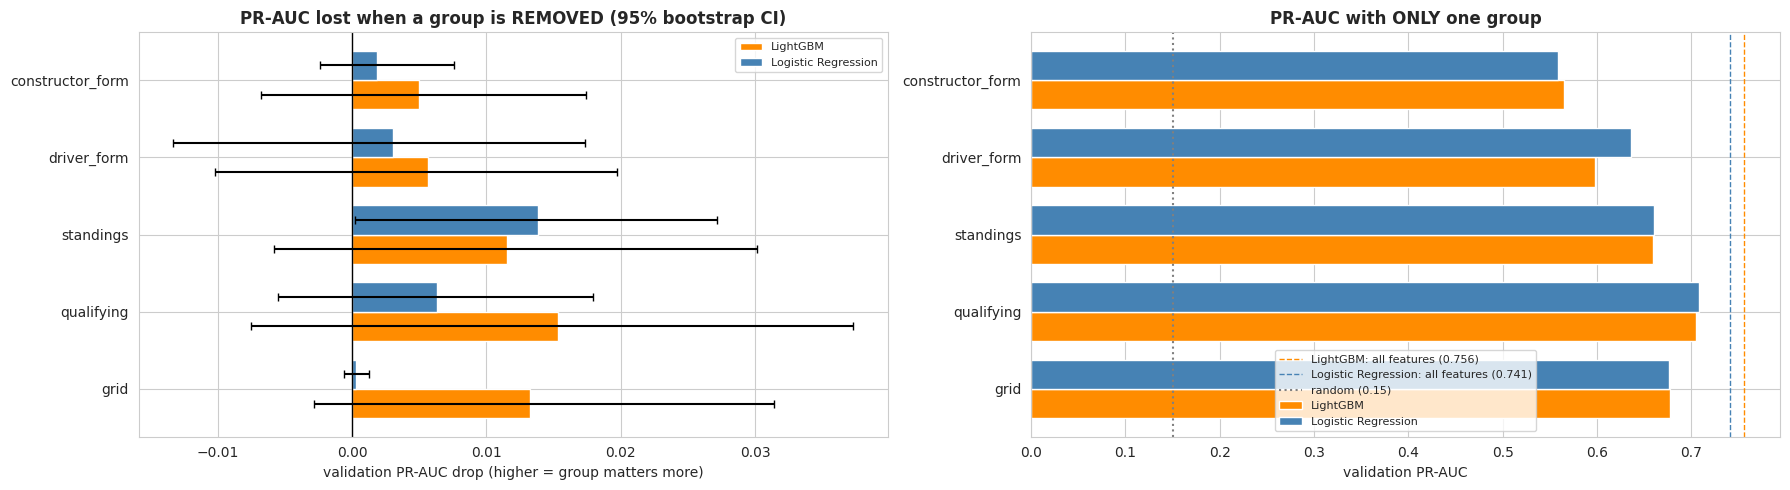

In [65]:
groups = list(FEATURE_GROUPS)
y = np.arange(len(groups)); h = 0.38
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for k, (model_name, color) in enumerate([('LightGBM', 'darkorange'), ('Logistic Regression', 'steelblue')]):
    sel = ablation['model'] == model_name
    wo = ablation[sel & ablation['variant'].str.startswith('without')].set_index('group').loc[groups]
    err = [np.clip(wo['pr_auc_drop'] - wo['drop_ci_low'], 0, None),
           np.clip(wo['drop_ci_high'] - wo['pr_auc_drop'], 0, None)]
    axes[0].barh(y + (k - 0.5) * h, wo['pr_auc_drop'], height=h, color=color, label=model_name,
                 xerr=err, capsize=3)
    only = ablation[sel & ablation['variant'].str.startswith('only')].set_index('group').loc[groups]
    axes[1].barh(y + (k - 0.5) * h, only['val_pr_auc'], height=h, color=color, label=model_name)
    full = ablation.loc[sel & (ablation['variant'] == 'All features'), 'val_pr_auc'].item()
    axes[1].axvline(full, color=color, ls='--', lw=1, label=f'{model_name}: all features ({full:.3f})')
axes[0].axvline(0, color='black', lw=1)
axes[0].set_title('PR-AUC lost when a group is REMOVED (95% bootstrap CI)', fontweight='bold')
axes[0].set_xlabel('validation PR-AUC drop (higher = group matters more)')
axes[1].axvline(y_val.mean(), color='grey', ls=':', label=f'random ({y_val.mean():.2f})')
axes[1].set_title('PR-AUC with ONLY one group', fontweight='bold')
axes[1].set_xlabel('validation PR-AUC')
for ax in axes:
    ax.set_yticks(y); ax.set_yticklabels(groups); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [66]:
# Remove CORRELATED groups together to reveal signal hidden by redundancy
combos = {
    'grid + qualifying (all position/pace)': FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying'],
    'driver_form + constructor_form (all form)': FEATURE_GROUPS['driver_form'] + FEATURE_GROUPS['constructor_form'],
    'standings + all form (all history)': (FEATURE_GROUPS['standings'] + FEATURE_GROUPS['driver_form']
                                           + FEATURE_GROUPS['constructor_form']),
}
combo_rows = []
for model_name, pred_fn in [('LightGBM', lgb_val_pred), ('Logistic Regression', lr_val_pred)]:
    p_full = pred_fn(FEATURES)
    ap_full = average_precision_score(yv, p_full)
    for name, removed in combos.items():
        kept = [f for f in FEATURES if f not in removed]
        p_wo = pred_fn(kept)
        lo, hi = drop_ci(p_full, p_wo)
        combo_rows.append({'model': model_name, 'removed': name, 'n_features_left': len(kept),
                           'val_pr_auc': average_precision_score(yv, p_wo),
                           'pr_auc_drop': ap_full - average_precision_score(yv, p_wo),
                           'drop_ci_low': lo, 'drop_ci_high': hi})
combo_ablation = pd.DataFrame(combo_rows)
display(combo_ablation.round(4))

,model,removed,n_features_left,val_pr_auc,pr_auc_drop,drop_ci_low,drop_ci_high
0,LightGBM,grid + qualifying (all position/pace),12,0.6476,0.1086,0.0471,0.1630
1,LightGBM,driver_form + constructor_form (all form),12,0.7483,0.0079,-0.0073,0.0223
2,LightGBM,standings + all form (all history),6,0.7082,0.0480,0.0044,0.0885
3,Logistic Regression,grid + qualifying (all position/pace),12,0.6565,0.0847,0.0453,0.1210
4,Logistic Regression,driver_form + constructor_form (all form),12,0.7467,-0.0056,-0.0235,0.0110
5,Logistic Regression,standings + all form (all history),6,0.7084,0.0327,-0.0126,0.0823


### 5.2 Findings — feature-group ablation
**Single-group ablation (validation PR-AUC; full model: LightGBM 0.756, LR 0.741):**
| Group | Drop without it (LightGBM) | Drop without it (LR) | PR-AUC with only it (LightGBM / LR) |
|---|---|---|---|
| grid | 0.013 (CI −0.003 to 0.031) | 0.000 (CI −0.001 to 0.001) | 0.677 / 0.677 |
| qualifying | 0.015 (CI −0.008 to 0.037) | 0.006 (CI −0.006 to 0.018) | **0.705 / 0.708** |
| standings | 0.012 (CI −0.006 to 0.030) | **0.014 (CI 0.000 to 0.027)** | 0.660 / 0.661 |
| driver_form | 0.006 (CI −0.010 to 0.020) | 0.003 (CI −0.013 to 0.017) | 0.597 / 0.636 |
| constructor_form | 0.005 (CI −0.007 to 0.017) | 0.002 (CI −0.002 to 0.008) | 0.565 / 0.559 |

- **Every group alone is strong** (PR-AUC 0.56–0.71 vs 0.15 random); qualifying, which includes the pace measure `gap_to_pole_pct`, is the strongest single group. Grid alone (0.677) reproduces the baseline (0.676).
- **Removing any single group causes no clearly significant loss** (bootstrap intervals include 0), except standings for logistic regression. Grid is the extreme case: LR loses nothing without it because `quali_pos` (ρ = 0.97) substitutes.

**Combined ablation (correlated groups removed together):**
| Removed | Drop (LightGBM) | Drop (LR) |
|---|---|---|
| grid + qualifying | **0.109 (CI 0.047 to 0.163)** | **0.085 (CI 0.045 to 0.121)** |
| driver_form + constructor_form | 0.008 (CI −0.007 to 0.022) | −0.006 (CI −0.024 to 0.011) |
| standings + both form groups | **0.048 (CI 0.004 to 0.089)** | 0.033 (CI −0.013 to 0.082) |

- **Redundancy confirmed:** grid and qualifying each look unimportant alone, but removing both costs ≈ 7× more and is clearly significant. They carry the same position/pace signal, which is the most important information in the model.
- **Form adds little beyond standings;** all history together (standings + form) adds a significant amount for LightGBM.
- **Information ranking:** position/pace ≫ history (mainly standings) > form.
- **Decision:** all 18 features are kept. No group can be removed with a clear loss and none harms performance; form features also cover rookies and new constructors whose standings are placeholders. Because importance is shared within correlated groups, XAI results (Chapter 6) are interpreted at group level as well.

## 5.3 Preprocessing-order experiments
Preprocessing steps learn statistics (medians, means, standard deviations); their **order** and the **data they are fit on** can change the model. Two experiments, using logistic regression (sensitive to scaling; same `C` as Chapter 4), evaluated on **validation** with race-level bootstrap intervals for the difference from our pipeline:
1. **Fit before vs after the split:** imputer + scaler fit on the training split only (ours) vs on all 2003–2024 rows including validation and test (leaky).
2. **Outlier capping before vs after scaling:** for `gap_to_pole_pct`, (A) cap at 7% → impute → scale (ours), (B) no cap → impute → scale, (C) impute → scale → clip the scaled value at ±3.

In [67]:
def lr_on(Ztr, Zva):
    clf = LogisticRegression(C=best_C, max_iter=2000).fit(Ztr, y_train)
    return clf.predict_proba(Zva)[:, 1]

X_all = data[FEATURES]                                   # train + val + test rows
prep_train = make_preprocessor(scale=True).fit(X_train)  # correct
prep_all = make_preprocessor(scale=True).fit(X_all)      # leaky

p_correct = lr_on(prep_train.transform(X_train), prep_train.transform(X_val))
p_leaky = lr_on(prep_all.transform(X_train), prep_all.transform(X_val))

# How different are the learned statistics?
learned = pd.DataFrame({
    'median (train only)': prep_train.named_steps['impute'].statistics_,
    'median (all data)':   prep_all.named_steps['impute'].statistics_,
    'mean (train only)':   prep_train.named_steps['scale'].mean_[:len(FEATURES)],
    'mean (all data)':     prep_all.named_steps['scale'].mean_[:len(FEATURES)],
    'std (train only)':    prep_train.named_steps['scale'].scale_[:len(FEATURES)],
    'std (all data)':      prep_all.named_steps['scale'].scale_[:len(FEATURES)],
}, index=FEATURES)
display(learned.loc[['gap_to_pole_pct', 'drv_career_starts', 'cons_points_share_before',
                     'drv_rank_before', 'field_size']].round(3))

lo, hi = drop_ci(p_correct, p_leaky)
exp1 = pd.DataFrame([
    {'variant': 'Correct: fit on train only', 'val_roc_auc': roc_auc_score(yv, p_correct),
     'val_pr_auc': average_precision_score(yv, p_correct)},
    {'variant': 'Leaky: fit on all 2003–2024 rows', 'val_roc_auc': roc_auc_score(yv, p_leaky),
     'val_pr_auc': average_precision_score(yv, p_leaky)},
])
display(exp1.round(4))
print(f"PR-AUC difference (correct − leaky): {exp1.val_pr_auc[0] - exp1.val_pr_auc[1]:+.4f} "
      f"(95% bootstrap CI {lo:+.4f} to {hi:+.4f})")

,median (train only),median (all data),mean (train only),mean (all data),std (train only),std (all data)
gap_to_pole_pct,1.799,1.723,2.223,2.108,1.795,1.715
drv_career_starts,69.000,82.000,92.619,103.936,79.424,86.411
cons_points_share_before,0.151,0.150,0.301,0.301,0.337,0.337
drv_rank_before,11.000,11.000,11.600,11.347,6.694,6.520
field_size,22.000,20.000,21.465,21.040,1.606,1.517


,variant,val_roc_auc,val_pr_auc
0,Correct: fit on train only,0.9388,0.7411
1,Leaky: fit on all 2003–2024 rows,0.9388,0.7408


PR-AUC difference (correct − leaky): +0.0003 (95% bootstrap CI -0.0007 to +0.0012)


In [68]:
# Recover the UNCAPPED gap (q, from Section 3.1, was never modified by the cap)
data['gap_raw'] = (data[['raceId', 'driverId']]
                   .merge(q[['raceId', 'driverId', 'gap_to_pole_pct']]
                          .rename(columns={'gap_to_pole_pct': 'gap_raw'}),
                          on=['raceId', 'driverId'], how='left')['gap_raw'].to_numpy())
assert np.allclose(data['gap_raw'].clip(upper=GAP_CAP), data['gap_to_pole_pct'], equal_nan=True)

def raw_gap_X(split):
    X = data.loc[data['split'] == split, FEATURES].copy()
    X['gap_to_pole_pct'] = data.loc[data['split'] == split, 'gap_raw'].to_numpy()
    return X

gi = FEATURES.index('gap_to_pole_pct')
def run_variant(Xtr, Xva, clip_after=False):
    prep = make_preprocessor(scale=True).fit(Xtr)
    Ztr, Zva = prep.transform(Xtr), prep.transform(Xva)
    if clip_after:                                    # cap AFTER scaling, in standard units
        Ztr[:, gi] = np.clip(Ztr[:, gi], -3, 3)
        Zva[:, gi] = np.clip(Zva[:, gi], -3, 3)
    return lr_on(Ztr, Zva), prep.named_steps['scale'].scale_[gi], Ztr[:, gi]

Xtr_raw, Xva_raw = raw_gap_X('train'), raw_gap_X('val')
variants = {
    'A (ours): cap 7% → impute → scale':  run_variant(X_train, X_val),
    'B: no cap → impute → scale':          run_variant(Xtr_raw, Xva_raw),
    'C: impute → scale → clip at ±3':      run_variant(Xtr_raw, Xva_raw, clip_after=True),
}
p_A = variants['A (ours): cap 7% → impute → scale'][0]
rows = []
for name, (p, gap_std, z) in variants.items():
    lo, hi = drop_ci(p_A, p) if not name.startswith('A') else (np.nan, np.nan)
    rows.append({'variant': name, 'gap std used for scaling': gap_std,
                 'scaled gap max (train)': z.max(),
                 'val_roc_auc': roc_auc_score(yv, p), 'val_pr_auc': average_precision_score(yv, p),
                 'PR-AUC: A − variant': average_precision_score(yv, p_A) - average_precision_score(yv, p),
                 'CI low': lo, 'CI high': hi})
exp2 = pd.DataFrame(rows)
print(f"Raw gap in train: max {Xtr_raw['gap_to_pole_pct'].max():.1f}%, "
      f"values > 7%: {(Xtr_raw['gap_to_pole_pct'] > 7).sum()}")
display(exp2.round(4))

Raw gap in train: max 37.8%, values > 7%: 229


,variant,gap std used for scaling,scaled gap max (train),val_roc_auc,val_pr_auc,PR-AUC: A − variant,CI low,CI high
0,A (ours): cap 7% → impute → scale,1.7945,2.6621,0.9388,0.7411,0.0000,NaN,NaN
1,B: no cap → impute → scale,2.6355,13.4353,0.9387,0.7417,-0.0005,-0.0037,0.0025
2,C: impute → scale → clip at ±3,2.6355,3.0000,0.9388,0.7421,-0.0010,-0.0036,0.0014


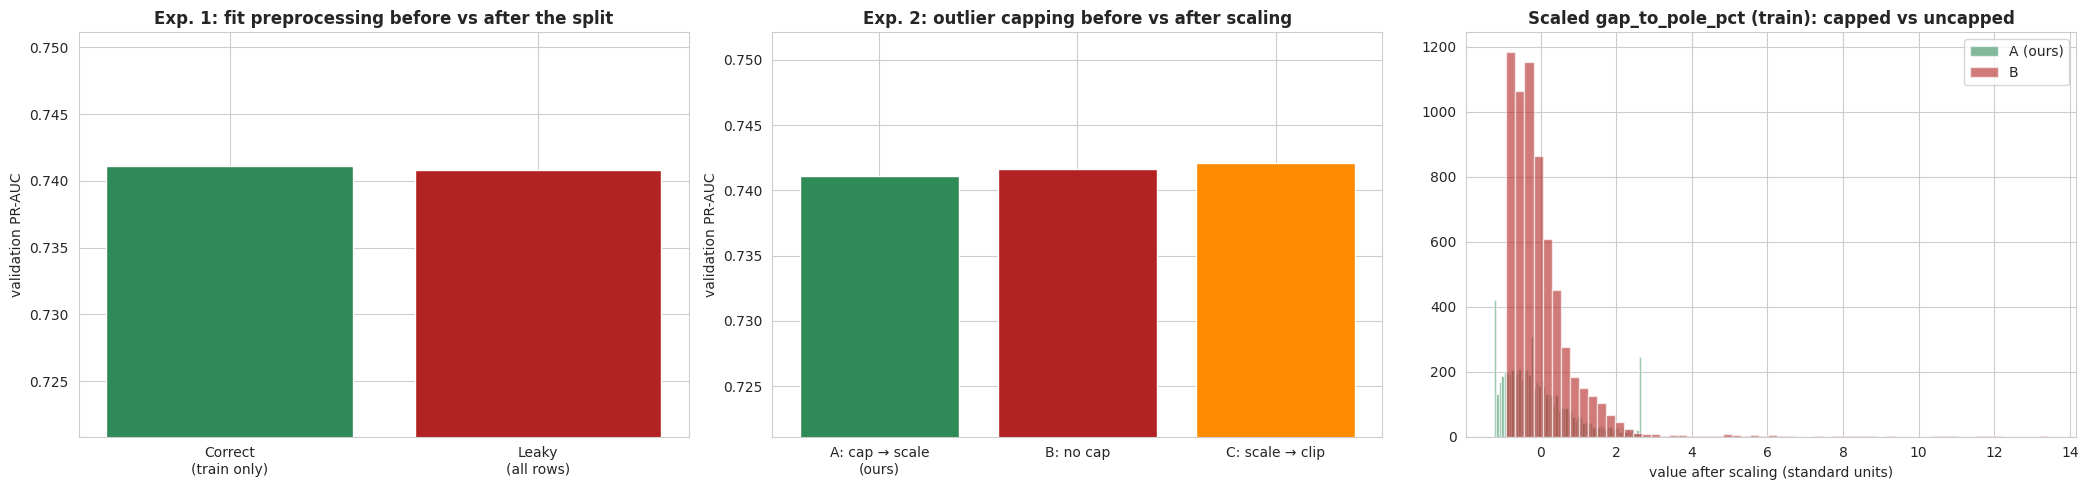

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

axes[0].bar(['Correct\n(train only)', 'Leaky\n(all rows)'], exp1['val_pr_auc'],
            color=['seagreen', 'firebrick'])
axes[0].set_ylim(exp1['val_pr_auc'].min() - 0.02, exp1['val_pr_auc'].max() + 0.01)
axes[0].set_title('Exp. 1: fit preprocessing before vs after the split', fontweight='bold')
axes[0].set_ylabel('validation PR-AUC')

axes[1].bar(['A: cap → scale\n(ours)', 'B: no cap', 'C: scale → clip'], exp2['val_pr_auc'],
            color=['seagreen', 'firebrick', 'darkorange'])
axes[1].set_ylim(exp2['val_pr_auc'].min() - 0.02, exp2['val_pr_auc'].max() + 0.01)
axes[1].set_title('Exp. 2: outlier capping before vs after scaling', fontweight='bold')
axes[1].set_ylabel('validation PR-AUC')

for (name, (_, _, z)), color in zip(list(variants.items())[:2], ['seagreen', 'firebrick']):
    axes[2].hist(z, bins=60, alpha=0.6, color=color, label=name.split(':')[0])
axes[2].set_title('Scaled gap_to_pole_pct (train): capped vs uncapped', fontweight='bold')
axes[2].set_xlabel('value after scaling (standard units)'); axes[2].legend()
plt.tight_layout()
plt.show()

,variant,val_roc_auc,val_pr_auc
0,Correct: shift(1) → rolling (past races only),0.9388,0.7411
1,LEAKY: rolling without shift (includes current...,0.9658,0.8441


PR-AUC difference (correct − leaky): -0.1030 (95% bootstrap CI -0.1453 to -0.0594)


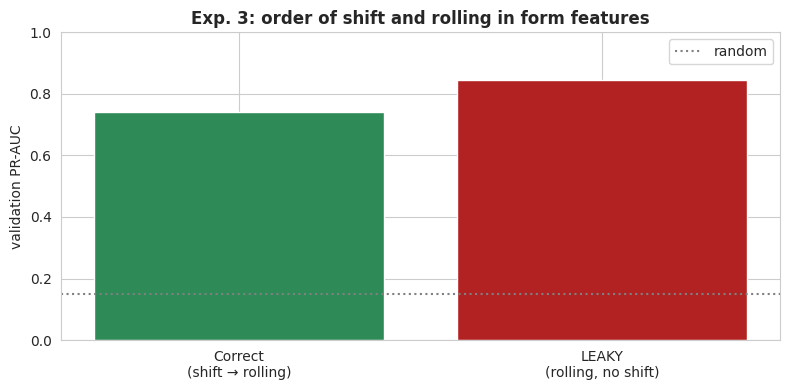

In [70]:
# DELIBERATELY LEAKY variant, for demonstration only (never used for the real model):
# rolling windows WITHOUT shift(1) include the current race's own result.
g = model_df.groupby('driverId')
leak = model_df[['raceId', 'driverId', 'constructorId']].copy()
leak['drv_podium_rate_last5'] = g['target_podium'].transform(lambda s: s.rolling(5, min_periods=1).mean())
leak['drv_avg_finish_last5'] = g['positionOrder'].transform(lambda s: s.rolling(5, min_periods=1).mean())
leak['drv_career_podium_rate'] = g['target_podium'].transform(lambda s: s.expanding().mean())

gc_leak = cr.groupby('constructorId')
cr_leak = cr[['constructorId', 'raceId']].copy()
roll = lambda col, w: gc_leak[col].transform(lambda s: s.rolling(w, min_periods=1).sum())
cr_leak['cons_podium_rate_last5'] = roll('c_podiums', 5) / roll('c_entries', 5)
cr_leak['cons_mech_dnf_rate_last10'] = roll('c_mech', 10) / roll('c_entries', 10)
leak = leak.merge(cr_leak, on=['constructorId', 'raceId'], how='left')

FORM = FEATURE_GROUPS['driver_form'][:3] + FEATURE_GROUPS['constructor_form']   # drv_career_starts is not affected
leak_rows = data[['raceId', 'driverId']].merge(leak, on=['raceId', 'driverId'], how='left')
def leaky_X(split):
    X = data.loc[data['split'] == split, FEATURES].copy()
    X[FORM] = leak_rows.loc[(data['split'] == split).to_numpy(), FORM].to_numpy()
    return X
Xtr_leak, Xva_leak = leaky_X('train'), leaky_X('val')

prep_leak = make_preprocessor(scale=True).fit(Xtr_leak)
p_leak3 = lr_on(prep_leak.transform(Xtr_leak), prep_leak.transform(Xva_leak))
lo, hi = drop_ci(p_correct, p_leak3)
exp3 = pd.DataFrame([
    {'variant': 'Correct: shift(1) → rolling (past races only)',
     'val_roc_auc': roc_auc_score(yv, p_correct), 'val_pr_auc': average_precision_score(yv, p_correct)},
    {'variant': 'LEAKY: rolling without shift (includes current race)',
     'val_roc_auc': roc_auc_score(yv, p_leak3), 'val_pr_auc': average_precision_score(yv, p_leak3)},
])
display(exp3.round(4))
print(f"PR-AUC difference (correct − leaky): {exp3.val_pr_auc[0] - exp3.val_pr_auc[1]:+.4f} "
      f"(95% bootstrap CI {lo:+.4f} to {hi:+.4f})")

plt.figure(figsize=(8, 4))
plt.bar(['Correct\n(shift → rolling)', 'LEAKY\n(rolling, no shift)'], exp3['val_pr_auc'],
        color=['seagreen', 'firebrick'])
plt.axhline(y_val.mean(), color='grey', ls=':', label='random')
plt.ylim(0, 1); plt.ylabel('validation PR-AUC'); plt.legend()
plt.title('Exp. 3: order of shift and rolling in form features', fontweight='bold')
plt.tight_layout()
plt.show()

### 5.3 Findings — preprocessing-order experiments (logistic regression, validation)
| Experiment | Correct order (ours) | Alternative | PR-AUC difference (95% CI) |
|---|---|---|---|
| 1. Fit imputer + scaler | on train only: 0.7411 | on all 2003–2024 rows (leaky): 0.7408 | +0.0003 (−0.0007 to +0.0012) |
| 2. Outlier capping (`gap_to_pole_pct`) | cap 7% → impute → scale: 0.7411 | no cap: 0.7417; scale → clip ±3: 0.7421 | −0.0005 / −0.0010 (both CIs include 0) |
| 3. Form features | `shift(1)` → rolling: 0.7411 | rolling without shift (leaky): **0.8441** | **−0.1030 (−0.1453 to −0.0594)** |

**Experiment 1 — fit before vs after the split.** The leaky fit absorbs statistics from validation/test years (e.g. `drv_career_starts` median 69 → 82, `field_size` median 22 → 20, reflecting longer modern careers and smaller modern fields), but the score is unchanged. Scaling is linear, so logistic regression compensates with slightly different weights, and imputation affects ≤ 1.8% of values. The train-only fit is kept as the correct procedure; here the leak happens to be harmless, but it would matter with heavy missingness or target-dependent preprocessing.

**Experiment 2 — capping before vs after scaling.** Without the cap, the gap's standard deviation grows 47% (1.79 → 2.64) and the largest scaled value rises from 2.66 to 13.4, compressing normal drivers into a narrow band (histogram). PR-AUC is nevertheless unchanged: only 229 training rows (3.6%) exceed 7%, they are near-certain non-podiums, and `quali_pos` / `grid_pos` carry the same information. **The cap brings no measurable gain on validation; it is kept for robustness**, since historical gaps reach 922% and an uncapped value at inference time would produce an extreme, meaningless prediction.

**Experiment 3 — order of `shift` and `rolling` (deliberately leaky).** Rolling windows without `shift(1)` include the current race's result, raising PR-AUC by 0.103 (ROC-AUC 0.939 → 0.966). This gain is **fake**: the current result is unknown before the start, so a deployed model would perform worse, not better. The fake gain exceeds every legitimate improvement in the project (best model vs baseline +0.080; all position/pace features ≈ 0.09–0.11), which is why form and standings features were validated with explicit leakage tests (Sections 3.2–3.3) rather than trusted.

**Conclusion:** the order of statistical preprocessing (experiments 1–2) has negligible impact in this project, while the order of operations in feature construction (experiment 3) is critical: one misplaced step produces a large, invisible leak.

# 6. Model Explainability (XAI)
Explanations of the **final model (LightGBM)** on the **test seasons 2022–2024** (unseen data; explanations do not tune anything).
> **Important:** feature importance and SHAP values describe **what the model relies on to predict**, not what **causes** podium finishes. They are associations learned from historical data (Section 6.4).

## 6.1 Global: permutation importance
Each feature is shuffled across rows (20 repeats) and the drop in **test PR-AUC** is measured. Because correlated features can substitute for each other (e.g. `grid_pos` ↔ `quali_pos`, ρ = 0.97), **group permutation importance** is also computed by shuffling all features of a group together.

,feature,group,pr_auc_drop_mean,pr_auc_drop_std
0,grid_pos,grid,0.0772,0.0244
1,quali_pos,qualifying,0.0682,0.0239
2,cons_points_share_before,standings,0.0141,0.0125
3,drv_points_share_before,standings,0.0079,0.0091
4,gap_to_pole_pct,qualifying,0.0023,0.0090
5,cons_podium_rate_last5,constructor_form,0.0016,0.0054
6,drv_rank_before,standings,0.0004,0.0060
7,cons_rank_before,standings,0.0004,0.0031
8,drv_career_podium_rate,driver_form,0.0004,0.0046
9,grid_penalty,qualifying,0.0000,0.0002


Test PR-AUC of the final model: 0.693


,group,pr_auc_drop_mean,pr_auc_drop_std
0,qualifying,0.1171,0.0214
1,grid,0.0725,0.0186
2,standings,0.0485,0.0177
3,driver_form,0.0067,0.0095
4,constructor_form,0.0001,0.0050


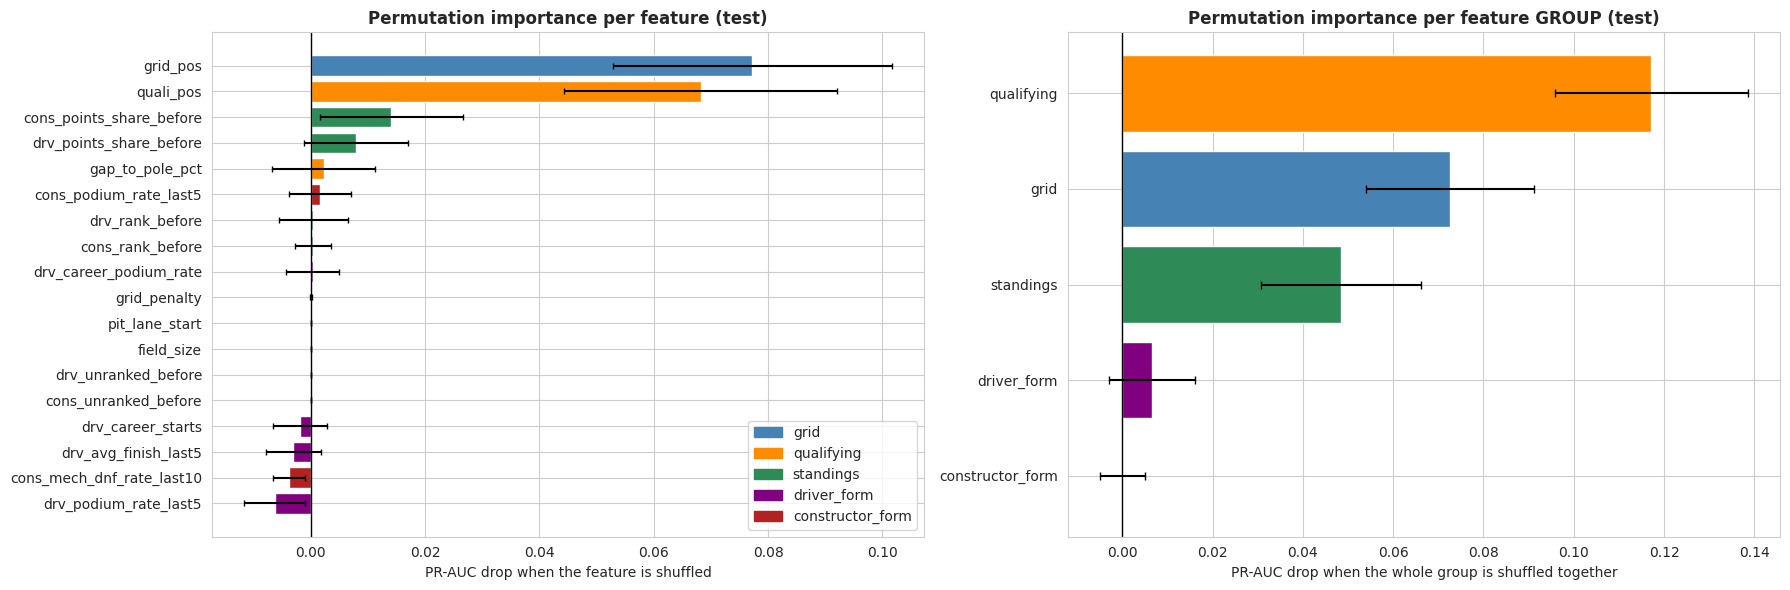

In [71]:
assert FINAL_MODEL == 'LightGBM'
final_pipe = Pipeline([('prep', prep_tree), ('clf', lgb_model)])     # already fitted: no refit
assert np.allclose(final_pipe.predict_proba(X_test)[:, 1], test_probs['LightGBM'])
feat_group = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}

# Feature-level (sklearn shuffles one column at a time)
pi = permutation_importance(final_pipe, X_test, y_test, scoring='average_precision',
                            n_repeats=20, random_state=SEED)
pi_df = (pd.DataFrame({'feature': FEATURES, 'group': [feat_group[f] for f in FEATURES],
                       'pr_auc_drop_mean': pi.importances_mean, 'pr_auc_drop_std': pi.importances_std})
         .sort_values('pr_auc_drop_mean', ascending=False).reset_index(drop=True))
display(pi_df.round(4))

# Group-level: shuffle all columns of a group with the SAME permutation
base_ap = average_precision_score(y_test, final_pipe.predict_proba(X_test)[:, 1])
rng = np.random.default_rng(SEED)
grp_rows = []
for grp, feats in FEATURE_GROUPS.items():
    drops = []
    for _ in range(20):
        Xp = X_test.copy()
        Xp[feats] = Xp[feats].to_numpy()[rng.permutation(len(Xp))]
        drops.append(base_ap - average_precision_score(y_test, final_pipe.predict_proba(Xp)[:, 1]))
    grp_rows.append({'group': grp, 'pr_auc_drop_mean': np.mean(drops), 'pr_auc_drop_std': np.std(drops)})
gpi = pd.DataFrame(grp_rows).sort_values('pr_auc_drop_mean', ascending=False).reset_index(drop=True)
print(f"Test PR-AUC of the final model: {base_ap:.3f}")
display(gpi.round(4))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
d = pi_df.iloc[::-1]
axes[0].barh(d['feature'], d['pr_auc_drop_mean'], xerr=d['pr_auc_drop_std'],
             color=d['group'].map(group_colors), capsize=2)
axes[0].set_title('Permutation importance per feature (test)', fontweight='bold')
axes[0].set_xlabel('PR-AUC drop when the feature is shuffled')
axes[0].legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()], loc='lower right')
d = gpi.iloc[::-1]
axes[1].barh(d['group'], d['pr_auc_drop_mean'], xerr=d['pr_auc_drop_std'],
             color=d['group'].map(group_colors), capsize=3)
axes[1].set_title('Permutation importance per feature GROUP (test)', fontweight='bold')
axes[1].set_xlabel('PR-AUC drop when the whole group is shuffled together')
for ax in axes:
    ax.axvline(0, color='black', lw=1)
plt.tight_layout()
plt.show()

## 6.2 Global: SHAP
SHAP splits each prediction into additive contributions: base value (average log-odds) + Σ feature contributions = the model's log-odds for that row. Computed with `TreeExplainer` on the booster truncated to the trees the model actually uses (early stopping), and checked to reproduce the model's predicted probabilities exactly.
- **Beeswarm:** each dot is one test row; horizontal position = contribution (right = towards podium); colour = feature value (red high, blue low).
- **Mean |SHAP|:** average magnitude of each feature's contribution; summed per group (missing-value indicators are counted with their feature's group) to account for shared credit among correlated features.

SHAP verified: contributions reproduce the predictions. Base value = -2.248 log-odds (≈ 9.5% podium probability)


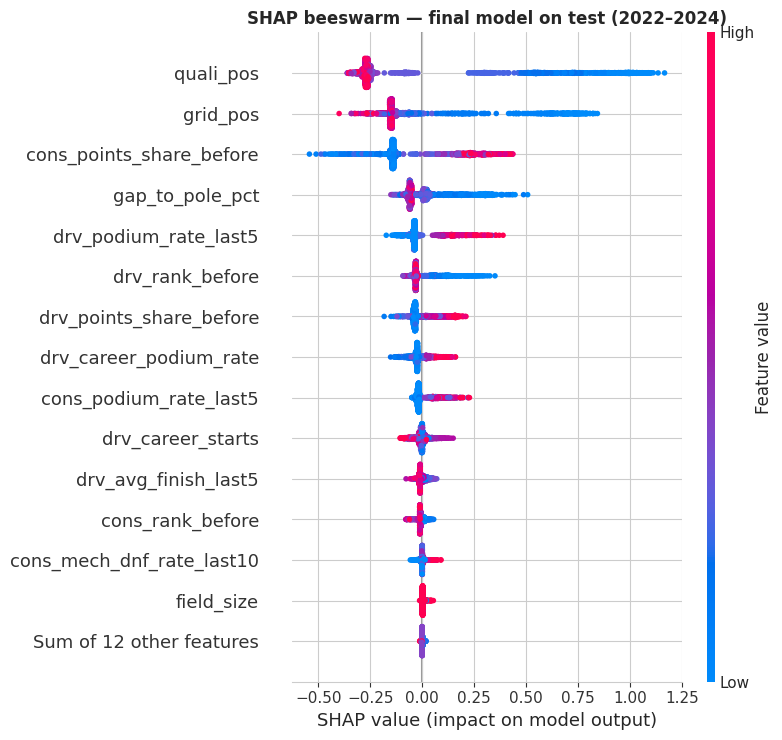

,mean_abs_shap,group
quali_pos,0.3933,qualifying
grid_pos,0.2203,grid
cons_points_share_before,0.1877,standings
gap_to_pole_pct,0.0849,qualifying
drv_podium_rate_last5,0.0688,driver_form
drv_rank_before,0.0516,standings
drv_points_share_before,0.0510,standings
drv_career_podium_rate,0.0397,driver_form
cons_podium_rate_last5,0.0383,constructor_form
drv_career_starts,0.0189,driver_form


,sum_mean_abs_shap,share_%
group,,
qualifying,0.480,40.158
standings,0.303,25.353
grid,0.225,18.827
driver_form,0.143,11.937
constructor_form,0.045,3.724


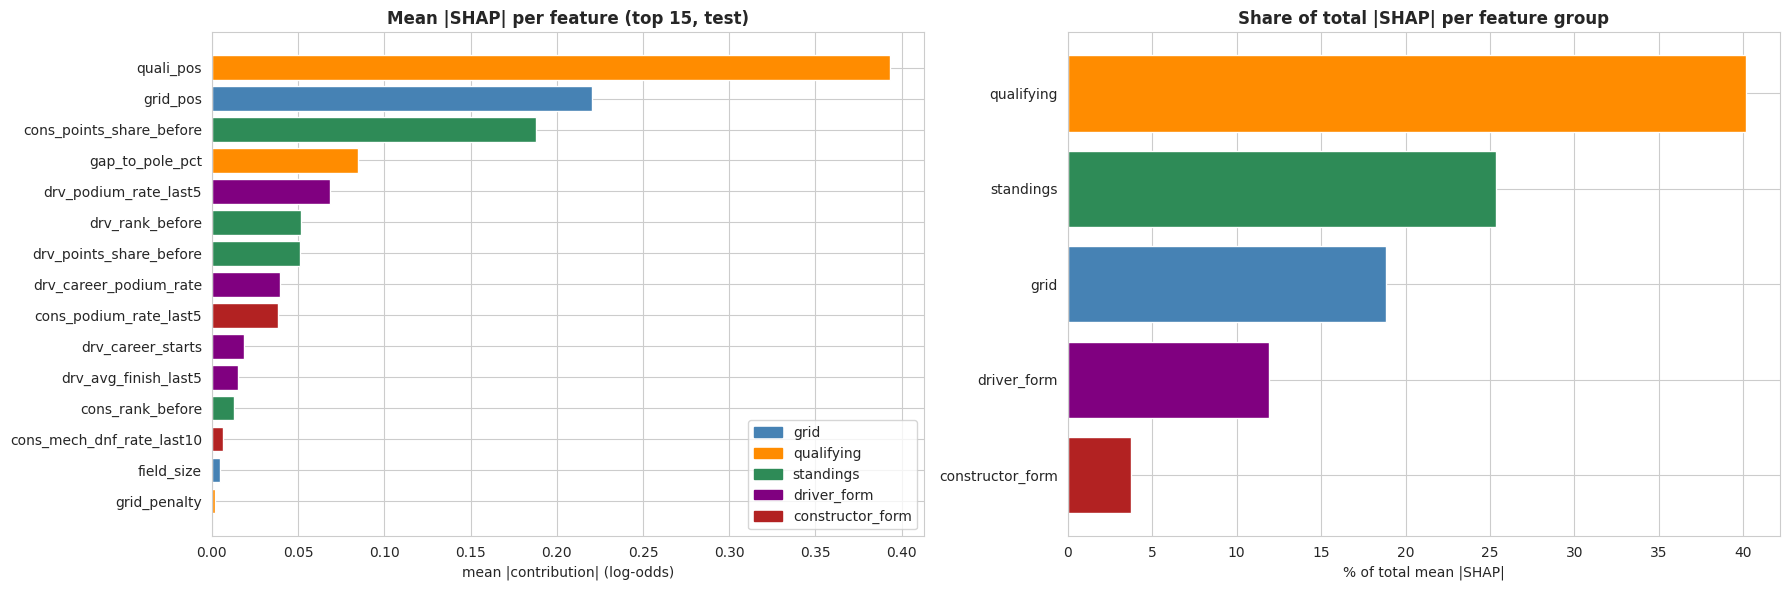

In [72]:
Xte_t = prep_tree.transform(X_test)                                  # 26 columns (incl. indicators)
booster = lgb.Booster(model_str=lgb_model.booster_.model_to_string(
                      num_iteration=lgb_model.best_iteration_))      # only the trees actually used
explainer = shap.TreeExplainer(booster)
sv = explainer(Xte_t)

# Additivity check: base value + sum of contributions must equal the model's prediction
logit = sv.values.sum(axis=1) + sv.base_values
assert np.allclose(1 / (1 + np.exp(-logit)), test_probs['LightGBM'], atol=1e-4), "SHAP does not match the model!"
base_prob = 1 / (1 + np.exp(-np.mean(sv.base_values)))
print(f"SHAP verified: contributions reproduce the predictions. Base value = {np.mean(sv.base_values):.3f} "
      f"log-odds (≈ {base_prob:.1%} podium probability)")

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP beeswarm — final model on test (2022–2024)', fontweight='bold')
plt.tight_layout(); plt.show()

# Mean |SHAP| per column and per group (indicator columns belong to their feature's group)
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=Xte_t.columns)
col_group = {c: feat_group[c.replace('missingindicator_', '')] for c in Xte_t.columns}
shap_feat = mean_abs.sort_values(ascending=False).to_frame('mean_abs_shap')
shap_feat['group'] = shap_feat.index.map(col_group)
shap_group = (shap_feat.groupby('group')['mean_abs_shap'].sum()
              .sort_values(ascending=False).to_frame('sum_mean_abs_shap'))
shap_group['share_%'] = 100 * shap_group['sum_mean_abs_shap'] / shap_group['sum_mean_abs_shap'].sum()
display(shap_feat.head(12).round(4))
display(shap_group.round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
d = shap_feat.head(15).iloc[::-1]
axes[0].barh(d.index, d['mean_abs_shap'], color=d['group'].map(group_colors))
axes[0].set_title('Mean |SHAP| per feature (top 15, test)', fontweight='bold')
axes[0].set_xlabel('mean |contribution| (log-odds)')
axes[0].legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()], loc='lower right')
d = shap_group.iloc[::-1]
axes[1].barh(d.index, d['share_%'], color=[group_colors[g] for g in d.index])
axes[1].set_title('Share of total |SHAP| per feature group', fontweight='bold')
axes[1].set_xlabel('% of total mean |SHAP|')
plt.tight_layout(); plt.show()

### 6.1–6.2 Findings — global explanations (final model, test 2022–2024, PR-AUC 0.693)
| Group | Group permutation importance (PR-AUC drop) | Share of mean \|SHAP\| | Ablation (5.2) |
|---|---|---|---|
| qualifying | **0.117 ± 0.021** | **40%** | with grid: largest combined loss |
| grid | **0.073 ± 0.019** | 19% | with qualifying: largest combined loss |
| standings | 0.049 ± 0.018 | 25% | main contributor of history |
| driver_form | 0.007 ± 0.010 | 12% | little unique value |
| constructor_form | 0.000 ± 0.005 | 4% | little unique value |

- **Consistent ranking across three methods** (ablation, permutation, SHAP): position/pace (grid + qualifying, ≈ 59% of SHAP credit) ≫ standings > form.
- **Permutation vs ablation for grid:** shuffling `grid_pos` costs the most of any feature (0.077) although removing it in the ablation cost logistic regression nothing. Permutation does not retrain, so it shows what **this** model relies on; ablation retrains, so it shows whether the information is **replaceable** (here by `quali_pos`, ρ = 0.97). Both are correct answers to different questions.
- **Shared credit:** SHAP ranks `quali_pos` above `grid_pos` (0.39 vs 0.22 mean |SHAP|), permutation the reverse; correlated features split credit differently depending on the method, so conclusions are drawn at group level.
- **Directions match domain logic (beeswarm):** front starting/qualifying positions, small gap to pole, high constructor points share, recent podiums and a high championship rank all push towards a podium. The effect is asymmetric: front positions push strongly up, back positions only moderately down. `drv_career_starts` shows mixed directions (interaction with other features).
- **Small negative permutation values** for some form features (e.g. `drv_podium_rate_last5` −0.006 ± 0.005, `cons_mech_dnf_rate_last10` −0.004 ± 0.003) are largely within noise but consistent with form carried over from the previous regulation era being slightly misleading in 2022–2024.
- Modifier features (`grid_penalty`, `pit_lane_start`, `field_size`, unranked flags) have zero test importance: they apply to very few rows.
- **SHAP base value** is −2.25 log-odds (≈ 9.5%): the mean of log-odds, which is below the 15% podium rate because the sigmoid is non-linear; it is the starting point of every explanation, not the base rate.

## 6.3 Local explanations
Two test cases are selected automatically:
- **Case A — beyond the grid:** the highest-probability driver who started outside the top 3 and did finish on the podium.
- **Case B — confident miss:** the highest-probability driver who did not finish on the podium.

**SHAP waterfall:** exact decomposition of one prediction from the base value (log-odds). **LIME:** perturbs the row 5,000 times, queries the model, and fits a weighted linear surrogate valid only around this row; its R² measures how faithful the surrogate is. Agreement between the two methods on the top features increases confidence in the explanation.

,year,race,forename,surname,team,grid_pos,quali_pos,prob,positionOrder,status
case,,,,,,,,,,
A — beyond the grid,2023,Belgian Grand Prix,Max,Verstappen,Red Bull,6,1.0,0.427,1,Finished
B — confident miss,2024,Australian Grand Prix,Max,Verstappen,Red Bull,1,1.0,0.657,19,Brakes


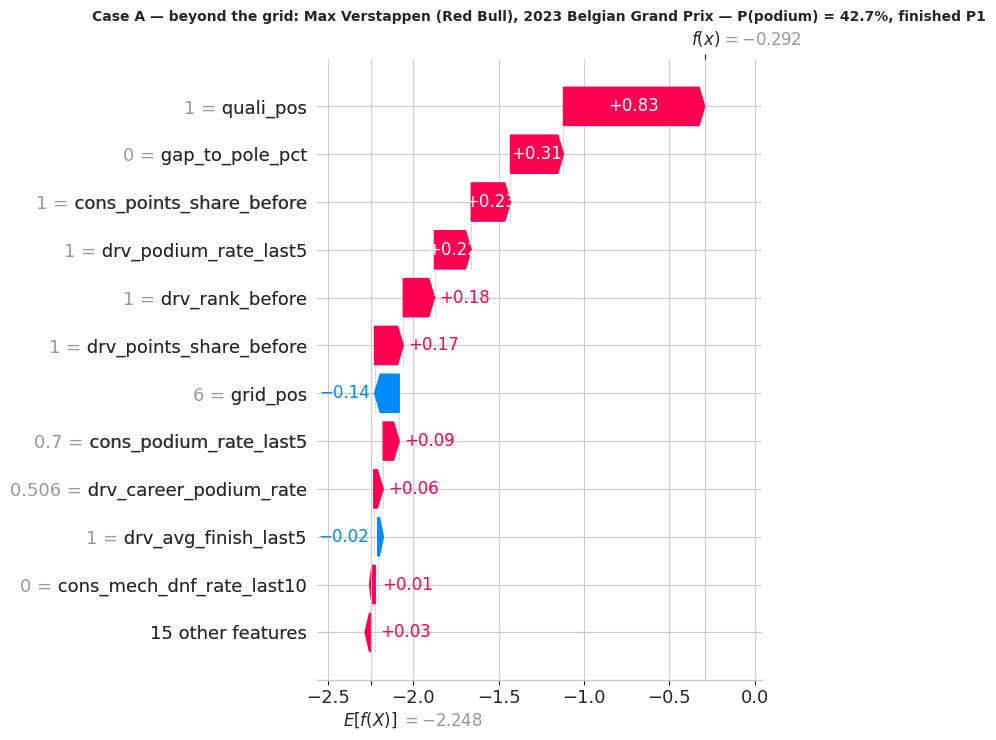

Base 9.5% → prediction 42.7% (log-odds -2.25 → -0.29)



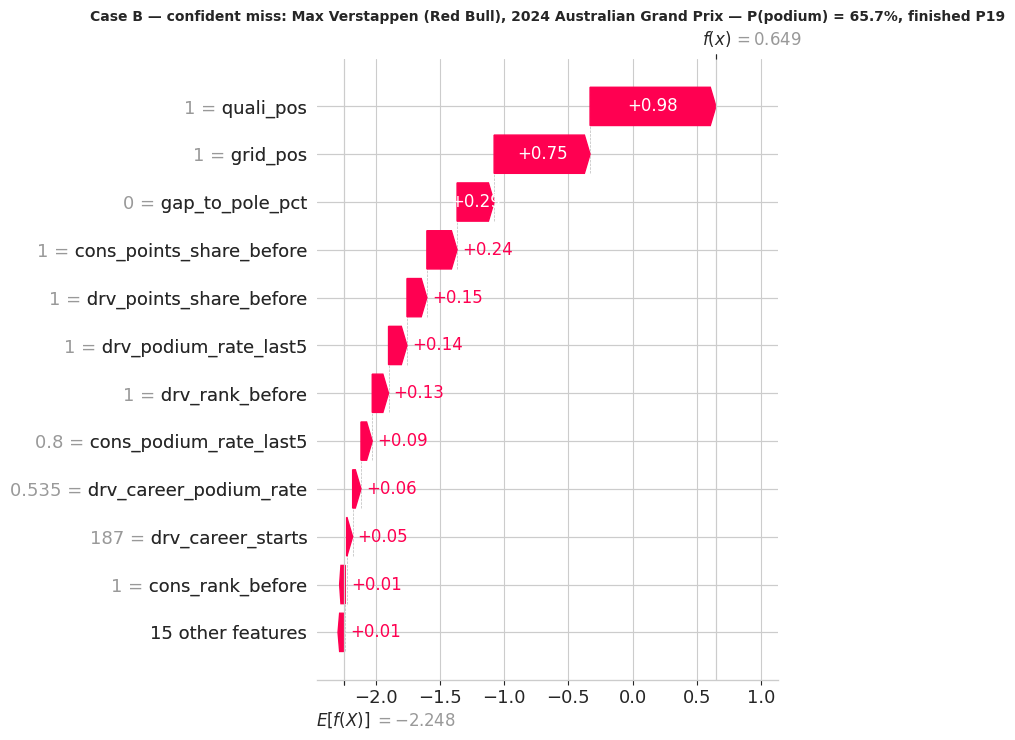

Base 9.5% → prediction 65.7% (log-odds -2.25 → 0.65)



In [73]:
te = (data.loc[data['split'] == 'test', ['year', 'raceId', 'driverId', 'constructorId',
                                         'grid_pos', 'quali_pos', 'positionOrder', 'status', TARGET]]
      .reset_index(drop=True))
te['prob'] = test_probs['LightGBM']
te = (te.merge(clean['drivers'][['driverId', 'forename', 'surname']], on='driverId', how='left')
        .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'}),
               on='constructorId', how='left')
        .merge(clean['races'][['raceId', 'name']].rename(columns={'name': 'race'}), on='raceId', how='left'))
complete = X_test.notna().all(axis=1).to_numpy()

i_a = te[(te['grid_pos'] >= 4) & (te[TARGET] == 1) & complete]['prob'].idxmax()
i_b = te[(te[TARGET] == 0) & complete]['prob'].idxmax()
cases = {'A — beyond the grid': i_a, 'B — confident miss': i_b}
display(te.loc[[i_a, i_b], ['year', 'race', 'forename', 'surname', 'team', 'grid_pos', 'quali_pos',
                            'prob', 'positionOrder', 'status']]
          .assign(case=list(cases)).set_index('case').round(3))

for name, i in cases.items():
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    r = te.loc[i]
    plt.title(f"Case {name}: {r['forename']} {r['surname']} ({r['team']}), {r['year']} {r['race']} — "
              f"P(podium) = {r['prob']:.1%}, finished P{int(r['positionOrder'])}", fontweight='bold', fontsize=10)
    plt.tight_layout(); plt.show()
    print(f"Base {base_prob:.1%} → prediction {r['prob']:.1%} "
          f"(log-odds {np.mean(sv.base_values):.2f} → {sv.values[i].sum() + sv.base_values[i]:.2f})\n")

Case A — beyond the grid: model P(podium) = 0.427 | LIME surrogate = 0.269 | surrogate fit R² = 0.62


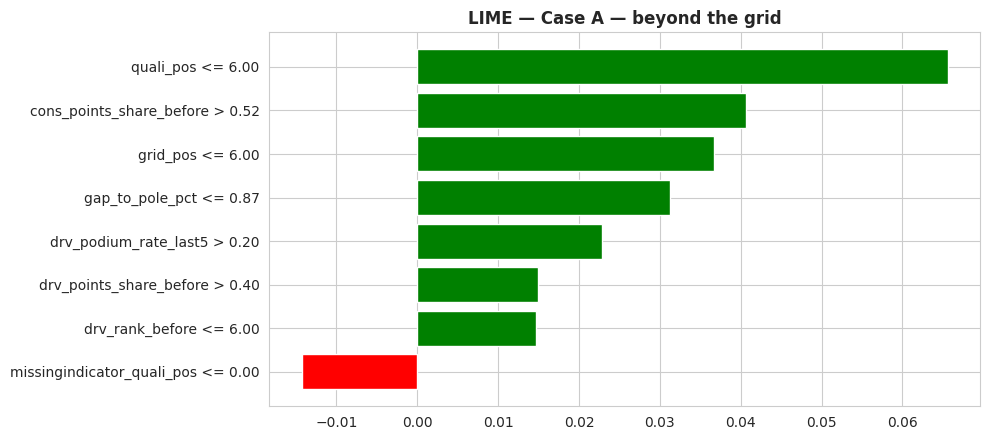

,SHAP top 8 (log-odds),LIME top 8 (probability weight)
0,quali_pos: +0.83,quali_pos <= 6.00: +0.066
1,gap_to_pole_pct: +0.31,cons_points_share_before > 0.52: +0.041
2,cons_points_share_before: +0.23,grid_pos <= 6.00: +0.037
3,drv_podium_rate_last5: +0.22,gap_to_pole_pct <= 0.87: +0.031
4,drv_rank_before: +0.18,drv_podium_rate_last5 > 0.20: +0.023
5,drv_points_share_before: +0.17,drv_points_share_before > 0.40: +0.015
6,grid_pos: -0.14,drv_rank_before <= 6.00: +0.015
7,cons_podium_rate_last5: +0.09,missingindicator_quali_pos <= 0.00: -0.014


Features in both top-8 lists: 7 / 8

Case B — confident miss: model P(podium) = 0.657 | LIME surrogate = 0.274 | surrogate fit R² = 0.62


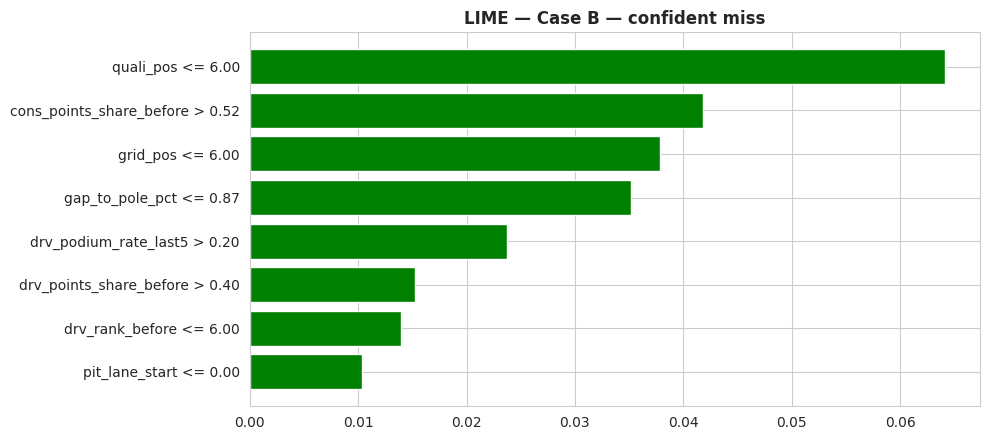

,SHAP top 8 (log-odds),LIME top 8 (probability weight)
0,quali_pos: +0.98,quali_pos <= 6.00: +0.064
1,grid_pos: +0.75,cons_points_share_before > 0.52: +0.042
2,gap_to_pole_pct: +0.29,grid_pos <= 6.00: +0.038
3,cons_points_share_before: +0.24,gap_to_pole_pct <= 0.87: +0.035
4,drv_points_share_before: +0.15,drv_podium_rate_last5 > 0.20: +0.024
5,drv_podium_rate_last5: +0.14,drv_points_share_before > 0.40: +0.015
6,drv_rank_before: +0.13,drv_rank_before <= 6.00: +0.014
7,cons_podium_rate_last5: +0.09,pit_lane_start <= 0.00: +0.010


Features in both top-8 lists: 7 / 8



In [74]:
Xtr_lime = Xtr_t.astype(float)                       # training data in the model's input space
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    Xtr_lime.to_numpy(), feature_names=list(Xtr_lime.columns),
    class_names=['No podium', 'Podium'], mode='classification',
    discretize_continuous=True, random_state=SEED)
lime_predict = lambda Z: lgb_model.predict_proba(pd.DataFrame(Z, columns=Xtr_lime.columns))

for name, i in cases.items():
    exp = lime_explainer.explain_instance(Xte_t.astype(float).iloc[i].to_numpy(), lime_predict,
                                          num_features=8, num_samples=5000)
    print(f"Case {name}: model P(podium) = {te.loc[i, 'prob']:.3f} | LIME surrogate = "
          f"{exp.local_pred[0]:.3f} | surrogate fit R² = {exp.score:.2f}")
    fig = exp.as_pyplot_figure()
    fig.set_size_inches(10, 4.5)
    plt.title(f'LIME — Case {name}', fontweight='bold')
    plt.tight_layout(); plt.show()

    shap_top = pd.Series(sv.values[i], index=Xte_t.columns).sort_values(key=np.abs, ascending=False).head(8)
    lime_feats = [next((c for c in Xtr_lime.columns if c in cond), cond) for cond, _ in exp.as_list()]
    compare = pd.DataFrame({'SHAP top 8 (log-odds)': [f"{f}: {v:+.2f}" for f, v in shap_top.items()],
                            'LIME top 8 (probability weight)': [f"{c}: {w:+.3f}" for c, w in exp.as_list()]})
    overlap = len(set(shap_top.index) & set(lime_feats))
    display(compare)
    print(f"Features in both top-8 lists: {overlap} / 8\n")

### 6.3 Findings — local explanations
**Case A — beyond the grid: Max Verstappen, Red Bull, 2023 Belgian GP.** Qualified P1 but started P6 (grid penalty) and won. Predicted P(podium) = 42.7% (above the 0.30 threshold → correctly predicted podium, where "grid ≤ 3" would say no). SHAP: `quali_pos` = 1 (+0.83 log-odds), `gap_to_pole_pct` = 0 (+0.31), constructor points share 1.0 (+0.23), recent podium rate 1.0 (+0.22), championship leader (+0.18); `grid_pos` = 6 pulls down only −0.14. The model relies on qualifying pace and team strength to see past the penalty, matching the Q1 finding that penalised front-row qualifiers still podium often.

**Case B — confident miss: Max Verstappen, Red Bull, 2024 Australian GP.** Started from pole, P(podium) = 65.7%, retired with a brake failure (P19). Every pre-race signal (pole, fastest qualifier, dominant team, top form) pushed towards a podium; a race-day mechanical failure is not observable before the start. The 65.7% itself reflects that even pole converts to a podium only ≈ 63–76% of the time (Q1).

**SHAP vs LIME:** 7 of the top 8 features agree in both cases, so the explanations are consistent about *which* features matter. LIME's local linear surrogate fits only moderately (R² = 0.62) and underestimates the model's probability (0.27 vs 0.43 / 0.66), so its weights are read as direction and ranking only (SHAP is exact by construction; units differ: log-odds vs probability). LIME's discretisation also hides detail: Case A's `grid_pos` = 6 falls in the same bin ("≤ 6") as pole, so LIME's explanations of A and B are nearly identical and miss the grid penalty that SHAP captures.

## 6.4 Explanations are not causal
**Feature importance and SHAP values show what the model relies on to predict, not what causes a podium.**
- `grid_pos` and `quali_pos` are the most important features, but this does **not** mean that moving a car to pole would make it finish on the podium. A fast car both qualifies at the front **and** finishes at the front: car and driver pace is a **common cause** of both, and the model uses the grid position as a visible signal of that pace.
- Likewise, a high constructor points share is associated with podiums because it reflects a competitive car, not because points themselves produce results.
- The model learned **associations** from 2003–2018 data; they can change when the sport changes (e.g. the 2022 regulations, Section 4.4). Correlated features also share or shift credit between methods (Section 6.1–6.2).
- Causal claims would require interventions or a causal design (e.g. comparing comparable cars with and without a penalty), which is outside the scope of this predictive model.

## 6.5 Inference function
`predict_podium(record)` returns the podium probability for one driver in one race using only pre-race fields:
- rejects unknown fields (e.g. race results), preventing leakage at prediction time;
- applies the training conventions: grid 0 → pit-lane start at the back, `grid_penalty` derived from grid and qualifying position if absent, `gap_to_pole_pct` capped at 7%;
- missing fields are imputed by the preprocessing fitted on the training data and listed in the output;
- decision threshold = the F1-optimal threshold chosen on validation.
Demonstrated on a complete record, a partially missing record, an extreme value and an invalid (leaky) input.

In [75]:
FINAL_THRESHOLD = fitted[FINAL_MODEL][1]

def predict_podium(record, threshold=FINAL_THRESHOLD):
    """Podium probability for ONE driver in ONE race, from pre-race information only.
    record: dict {feature: value} with any subset of FEATURES; missing or None values are imputed."""
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"Unknown / not-allowed fields (only pre-race features accepted): {sorted(unknown)}")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], columns=FEATURES)
    row = row.apply(pd.to_numeric, errors='coerce').astype(float)
    notes = []
    # Same conventions as in training
    if row.at[0, 'grid_pos'] == 0:
        row.at[0, 'pit_lane_start'] = 1
        if pd.notna(row.at[0, 'field_size']):
            row.at[0, 'grid_pos'] = row.at[0, 'field_size']
        notes.append('grid 0 interpreted as a pit-lane start (placed at the back)')
    if pd.isna(row.at[0, 'grid_penalty']) and row.loc[0, ['grid_pos', 'quali_pos']].notna().all():
        row.at[0, 'grid_penalty'] = row.at[0, 'grid_pos'] - row.at[0, 'quali_pos']
        notes.append('grid_penalty derived as grid_pos − quali_pos')
    if row.at[0, 'gap_to_pole_pct'] > GAP_CAP:
        notes.append(f"gap_to_pole_pct {row.at[0, 'gap_to_pole_pct']:.1f}% capped at {GAP_CAP}% (107% rule)")
        row.at[0, 'gap_to_pole_pct'] = GAP_CAP
    imputed = [f for f in FEATURES if pd.isna(row.at[0, f])]
    prob = float(final_pipe.predict_proba(row)[0, 1])
    return {'podium_probability': round(prob, 4),
            'predicted_podium': bool(prob >= threshold),
            'threshold': round(float(threshold), 4),
            'imputed_features': imputed,
            'notes': notes}

# --- Demo 1: complete record (Case A: Verstappen, 2023 Belgian GP) ---
complete_rec = X_test.iloc[i_a].to_dict()
out_complete = predict_podium(complete_rec)
assert np.isclose(out_complete['podium_probability'], te.loc[i_a, 'prob'], atol=1e-4), "Mismatch with model!"
print("Input record:"); display(pd.Series(complete_rec).to_frame('value').T.round(3))

# --- Demo 2: partially missing record (no qualifying time / position, no recent form) ---
dropped = ['quali_pos', 'gap_to_pole_pct', 'grid_penalty',
           'drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_career_podium_rate']
partial_rec = {k: v for k, v in complete_rec.items() if k not in dropped}
out_partial = predict_podium(partial_rec)

# --- Demo 3: extreme value (non-representative qualifying lap) ---
out_extreme = predict_podium(dict(complete_rec, gap_to_pole_pct=922.9))

demo = pd.DataFrame([
    {'demo': '1. Complete record', **out_complete},
    {'demo': f'2. Missing {len(dropped)} fields', **out_partial},
    {'demo': '3. gap_to_pole_pct = 922.9%', **out_extreme},
]).set_index('demo')
pd.set_option('display.max_colwidth', 120)
display(demo)

# --- Demo 4: invalid input containing a race result (leakage) must be rejected ---
try:
    predict_podium(dict(complete_rec, positionOrder=1))
except ValueError as e:
    print("Demo 4 — rejected as expected:", e)

Input record:


,grid_pos,pit_lane_start,field_size,quali_pos,gap_to_pole_pct,grid_penalty,drv_rank_before,drv_points_share_before,drv_unranked_before,cons_rank_before,cons_points_share_before,cons_unranked_before,drv_podium_rate_last5,drv_avg_finish_last5,drv_career_podium_rate,drv_career_starts,cons_podium_rate_last5,cons_mech_dnf_rate_last10
value,6.0,0.0,20.0,1.0,0.0,5.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.506,174.0,0.7,0.0


,podium_probability,predicted_podium,threshold,imputed_features,notes
demo,,,,,
1. Complete record,0.4274,True,0.3021,[],[]
2. Missing 6 fields,0.1723,False,0.3021,"[quali_pos, gap_to_pole_pct, grid_penalty, drv_podium_rate_last5, drv_avg_finish_last5, drv_career_podium_rate]",[]
3. gap_to_pole_pct = 922.9%,0.3719,True,0.3021,[],[gap_to_pole_pct 922.9% capped at 7.0% (107% rule)]


Demo 4 — rejected as expected: Unknown / not-allowed fields (only pre-race features accepted): ['positionOrder']


### 6.5 Findings — inference function
| Demo | P(podium) | Predicted podium | Notes |
|---|---|---|---|
| 1. Complete record (Case A) | 0.4274 | Yes | identical to the evaluated model (asserted) |
| 2. Six fields missing (qualifying + recent form) | 0.1723 | No | imputed fields listed in the output |
| 3. `gap_to_pole_pct` = 922.9% | 0.3719 | Yes | capped at 7% (107% rule) |
| 4. Record containing `positionOrder` | — | — | rejected: only pre-race fields accepted |

- **Missing information pulls predictions towards the typical case:** without his P1 qualifying and form, the model sees mainly "started P6" plus training medians, so P(podium) falls from 42.7% to 17.2%. The output lists every imputed field, so the user knows the prediction is less informed. `grid_penalty` is not derived when `quali_pos` is missing.
- **Cap:** a 7% gap is the worst possible value, but `quali_pos` = 1 still indicates the fastest qualifier, so the prediction drops only to 37.2%. For LightGBM the cap does not change predictions (trees treat values above the training maximum identically); it keeps inputs consistent with training and protects scaled models (logistic regression, neural network) from extreme inputs.
- **Leakage guard:** fields not in the 18 pre-race features (e.g. race results) raise an error, so the function cannot be fed post-race information.

# 7. Summary
**Data.** 14 relational tables audited: sentinels counted and converted (verified exactly), 13 date/duration columns typed (0 failures), all primary keys unique, all 23 foreign keys reconciled, raw files untouched. The grain was fixed to one row per (raceId, driverId): 85 shared-drive pairs resolved by an outcome-free rule (best grid), 1,505 pre-race non-starters excluded. Modeling window 2003–2024 (complete qualifying coverage): 8,961 rows.

**Data-engineering questions.**
- **Q1:** front-row → podium conversion rose from 68% (2003–2013) to 76% (2014–2024); the circuit ranking changed substantially by grid (Spearman ρ = 0.30) and moderately by qualifying (ρ = 0.57). Penalised front-row qualifiers podium 29% vs 64% for drivers promoted to the front row.
- **Q2:** no evidence of a home advantage once starting position is controlled (Mantel–Haenszel OR 0.91, 95% CI 0.77–1.06); the naive "home disadvantage" (OR 0.79) is explained by home drivers starting further back.
- **Q3:** mechanical retirements fell from 9.3% to 5.8% of starts (p = 0.0001); highest rates: Caterham, Lotus F1, Toro Rosso (2014–2021); Alfa Romeo, Alpine (2022–2024).

**Features.** 18 leakage-safe features in 5 groups (grid, qualifying, standings before the race, driver form, constructor form), each validated against the pre-race cutoff; standings and form verified by explicit leakage tests.

**Models (test 2022–2024, evaluated once).** Final model LightGBM: ROC-AUC 0.935, PR-AUC 0.693, F1 0.657, versus the statistical baseline (logistic regression on grid) 0.914 / 0.647 / 0.649. Logistic regression, random forest, LightGBM and the shallow neural network are effectively tied (test PR-AUC 0.693–0.710).

**Experiments & XAI.** Ablation, permutation importance and SHAP agree: position/pace (grid + qualifying, redundant with each other) ≫ standings > form. Preprocessing order had no measurable effect, whereas a single misplaced step in feature construction created a large, fake gain (+0.103 PR-AUC). Explanations describe associations the model uses, not causes.

**Limitations.** Qualifying coverage drift (features only reliable from 2003), era sensitivity (performance drops under the 2022 regulation change for all models), constructor rebrands break team history, shared-drive resolution is a proxy, and race-day events (failures, incidents, weather) are unobservable before the start.